In [ ]:
import platform
import torch

print("CPU Information:")
print(platform.processor())
print(platform.machine())

print("\nGPU Information:")
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))
    print("CUDA Version:", torch.version.cuda)
else:
    print("GPU not detected")

print("\nPyTorch Version:")
print(torch.__version__)

CPU Information:
x86_64
x86_64

GPU Information:
Tesla T4
CUDA Version: 13.0

PyTorch Version:
2.11.0+cu130


In [ ]:
!lscpu
!nvidia-smi

Architecture:                x86_64
  CPU op-mode(s):            32-bit, 64-bit
  Address sizes:             46 bits physical, 48 bits virtual
  Byte Order:                Little Endian
CPU(s):                      2
  On-line CPU(s) list:       0,1
Vendor ID:                   GenuineIntel
  Model name:                Intel(R) Xeon(R) CPU @ 2.00GHz
    CPU family:              6
    Model:                   85
    Thread(s) per core:      2
    Core(s) per socket:      1
    Socket(s):               1
    Stepping:                3
    BogoMIPS:                4000.32
    Flags:                   fpu vme de pse tsc msr pae mce cx8 apic sep mtrr pg
                             e mca cmov pat pse36 clflush mmx fxsr sse sse2 ss h
                             t syscall nx pdpe1gb rdtscp lm constant_tsc rep_goo
                             d nopl xtopology nonstop_tsc cpuid tsc_known_freq p
                             ni pclmulqdq ssse3 fma cx16 pcid sse4_1 sse4_2 x2ap
                   

In [ ]:
import torch

print("PyTorch TPU Check:")

try:
    import torch_xla
    import torch_xla.core.xla_model as xm

    device = xm.xla_device()

    print("TPU detected successfully!")
    print("TPU Device:", device)

except Exception as e:
    print("TPU check failed:")
    print(e)

PyTorch TPU Check:
TPU check failed:
No module named 'torch_xla'


Successfully renamed PrivateUse1 backend to 'tpu'. Device: device(type='tpu')
Registered Python module for 'tpu'.
Device type: tpu, Device index: default
Initializing TPU distributed runtime


In [ ]:
import os

print("TPU_NAME:", os.environ.get("TPU_NAME"))
print("COLAB_TPU_ADDR:", os.environ.get("COLAB_TPU_ADDR"))
print("TPU_VISIBLE_DEVICES:", os.environ.get("TPU_VISIBLE_DEVICES"))

TPU_NAME: None
COLAB_TPU_ADDR: None
TPU_VISIBLE_DEVICES: None


In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("Available devices:")

print("CPU:", torch.device("cpu"))
print("CUDA available:", torch.cuda.is_available())

try:
    device = torch.device("tpu")
    print("TPU device:", device)
except Exception as e:
    print("TPU device error:", e)

PyTorch version: 2.14.1+cpu
Available devices:
CPU: cpu
CUDA available: False
TPU device: tpu


In [ ]:
import torch

x = torch.randn(100, 100)
print("CPU tensor created:", x.shape)

try:
    tpu = torch.device("tpu")
    y = x.to(tpu)
    print("TPU tensor created:", y.shape)
except Exception as e:
    print("TPU operation failed:", repr(e))

CPU tensor created: torch.Size([100, 100])
TPU tensor created: torch.Size([100, 100])


In [ ]:
import torch

device = torch.device("tpu")

a = torch.randn(1000, 1000).to(device)
b = torch.randn(1000, 1000).to(device)

c = torch.matmul(a, b)

print("Matrix multiplication completed!")
print("Result shape:", c.shape)
print("Result device:", c.device)
print("Sample result:", c[0, 0].item())

Matrix multiplication completed!
Result shape: torch.Size([1000, 1000])
Result device: tpu:0
Sample result: -27.349002838134766


In [ ]:
!ls -la /dev/accel*
!ls -la /sys/class/accel/

ls: cannot access '/dev/accel*': No such file or directory
ls: cannot access '/sys/class/accel/': No such file or directory


In [ ]:
!env | grep -i -E 'TPU|XLA|PJRT'

TPU_WORKER_ID=0
TPU_SKIP_MDS_QUERY=1
CLOUD_TPU_TASK_ID=0
TPU_CHIPS_PER_HOST_BOUNDS=2,2,1
TPU_ACCELERATOR_TYPE=v5e-1
TPU_RUNTIME_METRICS_PORTS=8431,8432,8433,8434
KMP_EXTRA_ARGS=--logtostderr --listen_host=172.28.0.12 --target_host=172.28.0.12 --tunnel_background_save_url=https://colab.research.google.com/tun/m/cc48301118ce562b961b3c22d803539adc1e0c19/tpu-v5e1-s-usw1c0-1yxpyv3iyijom --tunnel_background_save_delay=10s --tunnel_periodic_background_save_frequency=30m0s --enable_output_coalescing=true --output_coalescing_required=true --use_oneplatform_for_bg_save=true 
TPU_HOST_BOUNDS=1,1,1
PJRT_DEVICE=TPU
TPU_LIBRARY_PATH=/usr/local/lib/python3.13/dist-packages/libtpu/libtpu.so
XRT_TPU_CONFIG=localservice;0;localhost:51011
TPU_PREMAPPED_BUFFER_SIZE=0
TPU_WORKER_HOSTNAMES=localhost
COLAB_IMAGE_TYPE=tpu
PYTHONWARNINGS=ignore:<TorchTpu/Performance/TcMalloc/
CLOUD_TPU_ACCELERATOR_TYPE=v5e-1


In [ ]:
Hardware Inventory — Initial Inspection
- Platform: Google Colab
- CPU: Intel Xeon CPU @ 2.00 GHz
- CPU architecture: x86_64
- Logical CPUs: 2
- GPU: NVIDIA Tesla T4
- GPU memory: 15 GB
- CUDA: 13.0
- TPU: Google TPU v5e-1
- GPU software environment: PyTorch 2.11.0+cu130
- TPU software environment: PyTorch 2.14.1+cpu, TPU backend registered

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

project_path = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"

folders = [
    "Code",
    "Raw_Results",
    "CSV_Data",
    "Graphs",
    "Research_Paper",
    "Documentation"
]

for folder in folders:
    os.makedirs(os.path.join(project_path, folder), exist_ok=True)

print("Project folders created successfully!")
print(project_path)

Project folders created successfully!
/content/drive/MyDrive/AI_Inference_Precision_Comparison


In [ ]:
import os

project_path = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"

folders = [
    "Code",
    "Results/Raw_CSV",
    "Results/Graphs",
    "Research_Paper",
    "Documentation"
]

for folder in folders:
    os.makedirs(os.path.join(project_path, folder), exist_ok=True)

print("Project folder structure verified!")

Project folder structure verified!


In [ ]:
import json
import os
from datetime import datetime

project_path = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"

hardware_info = {
    "project": "Numerical Precision Impact on AI Inference",
    "platform": "Google Colab",
    "CPU": "Intel Xeon CPU @ 2.00GHz (2 logical CPUs)",
    "GPU": "NVIDIA Tesla T4 (15 GB)",
    "TPU": "Google Cloud TPU v5e-1",
    "framework": "PyTorch",
    "GPU_runtime_torch_version": "2.11.0+cu130",
    "TPU_runtime_torch_version": "2.14.1+cpu",
    "NPU": "Not confirmed; instructor discussion pending",
    "record_date": datetime.now().strftime("%Y-%m-%d")
}

file_path = os.path.join(project_path, "Documentation", "hardware_inventory.json")

with open(file_path, "w") as file:
    json.dump(hardware_info, file, indent=4)

print("Hardware inventory saved successfully!")
print(file_path)

Hardware inventory saved successfully!
/content/drive/MyDrive/AI_Inference_Precision_Comparison/Documentation/hardware_inventory.json


In [ ]:
import pandas as pd
import os

project_path = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"

columns = [
    "Experiment",
    "Device",
    "Matrix_Size",
    "Precision",
    "Repetition",
    "Runtime_Seconds",
    "FLOPS",
    "Notes"
]

df = pd.DataFrame(columns=columns)

file_path = os.path.join(
    project_path,
    "Results",
    "Raw_CSV",
    "experiment_log.csv"
)

df.to_csv(file_path, index=False)

print("Experiment tracking file created!")
print(file_path)

Experiment tracking file created!
/content/drive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/experiment_log.csv


In [ ]:
import torch
import platform
import os

print("CPU:", platform.processor())
print("Logical CPUs:", os.cpu_count())

print("\nPyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU Memory:", round(
        torch.cuda.get_device_properties(0).total_memory / (1024**3), 2
    ), "GB")

print("\nCPU and GPU verification completed!")

CPU: x86_64
Logical CPUs: 2

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU Memory: 14.56 GB

CPU and GPU verification completed!


In [ ]:
import torch
import time
import os
import pandas as pd
import statistics

# Reproducibility and CPU configuration
torch.manual_seed(42)
torch.set_num_threads(2)
torch.set_float32_matmul_precision("highest")

# Connect Google Drive if needed
from google.colab import drive
if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")

project_path = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
results = []

matrix_sizes = [256, 512, 1024, 2048, 1536]
repetitions = 10
warmups = 3

def benchmark(device, a, b, n):

    # Warm-up
    for _ in range(warmups):
        c = torch.matmul(a, b)

    if device == "GPU":
        torch.cuda.synchronize()

    times = []

    # Actual measurements
    for _ in range(repetitions):

        if device == "GPU":
            torch.cuda.synchronize()

        start = time.perf_counter()

        c = torch.matmul(a, b)

        if device == "GPU":
            torch.cuda.synchronize()

        end = time.perf_counter()
        times.append(end - start)

    median_time = statistics.median(times)
    mean_time = statistics.mean(times)
    std_time = statistics.stdev(times)

    operations = 2 * (n ** 3)
    gflops = operations / median_time / 1e9

    return median_time, mean_time, std_time, gflops


for n in matrix_sizes:

    print(f"\nTesting matrix size: {n} x {n}")

    # Generate identical input matrices
    a_cpu = torch.randn(n, n, dtype=torch.float32)
    b_cpu = torch.randn(n, n, dtype=torch.float32)

    # CPU benchmark
    cpu_result = benchmark("CPU", a_cpu, b_cpu, n)

    # Move inputs to GPU outside the timed region
    a_gpu = a_cpu.to("cuda")
    b_gpu = b_cpu.to("cuda")

    # GPU benchmark
    gpu_result = benchmark("GPU", a_gpu, b_gpu, n)

    for device, result in [
        ("CPU", cpu_result),
        ("GPU", gpu_result)
    ]:

        median_time, mean_time, std_time, gflops = result

        results.append({
            "Device": device,
            "Matrix_Size": n,
            "Precision": "FP32",
            "Repetitions": repetitions,
            "Median_Seconds": median_time,
            "Mean_Seconds": mean_time,
            "Std_Seconds": std_time,
            "GFLOPS": gflops
        })

        print(
            f"{device}: Median = {median_time:.6f}s | "
            f"GFLOPS = {gflops:.3f}"
        )

# Save results
df = pd.DataFrame(results)

csv_path = os.path.join(
    project_path,
    "Results",
    "Raw_CSV",
    "matrix_multiplication_cpu_gpu.csv"
)

df.to_csv(csv_path, index=False)

print("\nBenchmark completed!")
print("Results saved to:", csv_path)

display(df)

Mounted at /content/drive

Testing matrix size: 256 x 256
CPU: Median = 0.000289s | GFLOPS = 116.076
GPU: Median = 0.000061s | GFLOPS = 549.735

Testing matrix size: 512 x 512
CPU: Median = 0.001800s | GFLOPS = 149.108
GPU: Median = 0.000128s | GFLOPS = 2098.890

Testing matrix size: 1024 x 1024
CPU: Median = 0.016136s | GFLOPS = 133.083
GPU: Median = 0.000730s | GFLOPS = 2941.315

Testing matrix size: 2048 x 2048
CPU: Median = 0.129117s | GFLOPS = 133.056
GPU: Median = 0.006078s | GFLOPS = 2826.772

Testing matrix size: 1536 x 1536
CPU: Median = 0.051338s | GFLOPS = 141.177
GPU: Median = 0.002649s | GFLOPS = 2736.356

Benchmark completed!
Results saved to: /content/drive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/matrix_multiplication_cpu_gpu.csv


,Device,Matrix_Size,Precision,Repetitions,Median_Seconds,Mean_Seconds,Std_Seconds,GFLOPS
0,CPU,256,FP32,10,0.000289,0.000294,0.000013,116.075981
1,GPU,256,FP32,10,0.000061,0.000063,0.000007,549.734704
2,CPU,512,FP32,10,0.001800,0.001795,0.000100,149.107946
3,GPU,512,FP32,10,0.000128,0.000128,0.000002,2098.890143
4,CPU,1024,FP32,10,0.016136,0.017012,0.002586,133.082530
5,GPU,1024,FP32,10,0.000730,0.000733,0.000012,2941.315210
6,CPU,2048,FP32,10,0.129117,0.131315,0.012575,133.056145
7,GPU,2048,FP32,10,0.006078,0.006082,0.000015,2826.772435
8,CPU,1536,FP32,10,0.051338,0.054201,0.009779,141.176952
9,GPU,1536,FP32,10,0.002649,0.002647,0.000014,2736.355965


In [ ]:
import torch

device = torch.device("tpu")

print("PyTorch:", torch.__version__)
print("TPU backend:", hasattr(torch, "tpu"))

# Create matrices directly on TPU
a = torch.randn(1000, 1000, device=device)
b = torch.randn(1000, 1000, device=device)

# Synchronize using the public PyTorch API
torch.accelerator.synchronize()

# Matrix multiplication
c = torch.matmul(a, b)

# Wait for TPU computation to finish
torch.accelerator.synchronize()

print("\nTPU computation completed!")
print("Result shape:", c.shape)
print("Result device:", c.device)
print("Sample result:", c[0, 0].item())

PyTorch: 2.14.1+cpu
TPU backend: True

TPU computation completed!
Result shape: torch.Size([1000, 1000])
Result device: tpu:0
Sample result: 8.51412296295166


In [ ]:
import torch
import time
import os
import pandas as pd
import statistics

# Configuration
torch.manual_seed(42)

device = torch.device("tpu")

matrix_sizes = [256, 512, 1024, 2048, 1536]
repetitions = 10
warmups = 3

results = []

def benchmark_tpu(a, b, n):

    # Warm-up
    for _ in range(warmups):
        c = torch.matmul(a, b)

    torch.accelerator.synchronize()

    times = []

    # Actual measurements
    for _ in range(repetitions):

        torch.accelerator.synchronize()
        start = time.perf_counter()

        c = torch.matmul(a, b)

        torch.accelerator.synchronize()
        end = time.perf_counter()

        times.append(end - start)

    median_time = statistics.median(times)
    mean_time = statistics.mean(times)
    std_time = statistics.stdev(times)

    operations = 2 * (n ** 3)
    gflops = operations / median_time / 1e9

    return median_time, mean_time, std_time, gflops


for n in matrix_sizes:

    print(f"\nTesting TPU matrix size: {n} x {n}")

    # Generate FP32 matrices directly on TPU
    a = torch.randn(n, n, dtype=torch.float32, device=device)
    b = torch.randn(n, n, dtype=torch.float32, device=device)

    result = benchmark_tpu(a, b, n)

    median_time, mean_time, std_time, gflops = result

    results.append({
        "Device": "TPU",
        "Matrix_Size": n,
        "Precision": "FP32",
        "Repetitions": repetitions,
        "Median_Seconds": median_time,
        "Mean_Seconds": mean_time,
        "Std_Seconds": std_time,
        "GFLOPS": gflops
    })

    print(f"Median: {median_time:.6f} seconds")
    print(f"GFLOPS: {gflops:.3f}")

    del a, b # No effect on benchmark results

# Save TPU results
df = pd.DataFrame(results)

project_path = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"

csv_path = os.path.join(
    project_path,
    "Results",
    "Raw_CSV",
    "matrix_multiplication_tpu.csv"
)

df.to_csv(csv_path, index=False)

print("\nTPU benchmark completed!")
print("Results saved to:", csv_path)

display(df)


Testing TPU matrix size: 256 x 256
Median: 0.000271 seconds
GFLOPS: 123.651

Testing TPU matrix size: 512 x 512
Median: 0.000308 seconds
GFLOPS: 872.890

Testing TPU matrix size: 1024 x 1024
Median: 0.000306 seconds
GFLOPS: 7015.754

Testing TPU matrix size: 2048 x 2048
Median: 0.000490 seconds
GFLOPS: 35061.673

Testing TPU matrix size: 1536 x 1536
Median: 0.000374 seconds
GFLOPS: 19398.740


OSError: Cannot save file into a non-existent directory: '/content/drive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV'

In [ ]:
import torch
import time

device = torch.device("tpu")

print("TPU available:", torch.accelerator.is_available())
print("TPU devices:", torch.accelerator.device_count())
print("Current accelerator:", torch.accelerator.current_accelerator())

for n in [256, 1024, 2048]:

    torch.manual_seed(42)

    a = torch.randn(n, n, dtype=torch.float32)
    b = torch.randn(n, n, dtype=torch.float32)

    # CPU reference
    cpu_result = torch.matmul(a, b)

    # Transfer inputs to TPU
    a_tpu = a.to(device)
    b_tpu = b.to(device)

    # Warm-up and materialize result
    warmup = torch.matmul(a_tpu, b_tpu)
    warmup.cpu()
    torch.accelerator.synchronize()

    # Timed execution with result materialization
    start = time.perf_counter()

    result_tpu = torch.matmul(a_tpu, b_tpu)
    result_cpu = result_tpu.cpu()

    elapsed = time.perf_counter() - start

    # Numerical correctness
    difference = (cpu_result - result_cpu).abs().max().item()

    print(f"\nMatrix size: {n}")
    print(f"Elapsed time: {elapsed:.6f} seconds")
    print(f"Maximum absolute difference: {difference:.6f}")

TPU available: True
TPU devices: 1
Current accelerator: tpu

Matrix size: 256
Elapsed time: 0.001321 seconds
Maximum absolute difference: 0.182104

Matrix size: 1024
Elapsed time: 0.009080 seconds
Maximum absolute difference: 0.380457

Matrix size: 2048
Elapsed time: 0.032863 seconds
Maximum absolute difference: 0.570232


In [ ]:
import torch

torch.manual_seed(42)

print("Original precision:", torch.get_float32_matmul_precision())

# Request highest FP32 matmul precision
torch.set_float32_matmul_precision("highest")

print("Selected precision:", torch.get_float32_matmul_precision())

device = torch.device("tpu")

for n in [256, 1024]:

    a = torch.randn(n, n, dtype=torch.float32)
    b = torch.randn(n, n, dtype=torch.float32)

    # CPU reference
    cpu_result = a @ b

    # TPU calculation
    tpu_result = (a.to(device) @ b.to(device)).cpu()
    torch.accelerator.synchronize()

    difference = (cpu_result - tpu_result).abs()

    max_error = difference.max().item()
    mean_error = difference.mean().item()
    rmse = torch.sqrt(torch.mean(difference ** 2)).item()

    print(f"\nMatrix size: {n}")
    print("Maximum absolute error:", max_error)
    print("Mean absolute error:", mean_error)
    print("RMSE:", rmse)

Original precision: medium
Selected precision: highest

Matrix size: 256
Maximum absolute error: 2.288818359375e-05
Mean absolute error: 2.5610224838601425e-06
RMSE: 3.5193058920413023e-06


/tmp/ipykernel_5687/3484043553.py:23: UserWarning: <TorchTpu/Performance/> TPU is using HIGHEST precision as requested, but performance may be significantly lower. Consider using torch.set_float32_matmul_precision('medium') for better performance. (Triggered internally at csrc/ops/precision_context.cc:70.)
  tpu_result = (a.to(device) @ b.to(device)).cpu()



Matrix size: 1024
Maximum absolute error: 7.62939453125e-05
Mean absolute error: 6.815627330070129e-06
RMSE: 8.913638339436147e-06


In [ ]:
import torch
import time
import statistics
import csv
import os

device = torch.device("tpu")
sizes = [256, 512, 1024, 1536, 2048]
modes = ["medium", "high", "highest"]
repetitions = 10
warmups = 3

results = []

for n in sizes:
    torch.manual_seed(42)

    # Same input matrices for every precision mode
    a_cpu = torch.randn(n, n, dtype=torch.float32)
    b_cpu = torch.randn(n, n, dtype=torch.float32)

    # CPU FP32 reference
    reference = a_cpu @ b_cpu

    a_tpu = a_cpu.to(device)
    b_tpu = b_cpu.to(device)

    for mode in modes:
        torch.set_float32_matmul_precision(mode)

        # Warm-up: allow TPU execution/compilation to finish
        for _ in range(warmups):
            output = a_tpu @ b_tpu
            torch.accelerator.synchronize()

        # Timed compute-only repetitions
        times = []

        for _ in range(repetitions):
            torch.accelerator.synchronize()
            start = time.perf_counter()

            output = a_tpu @ b_tpu
            torch.accelerator.synchronize()

            elapsed = time.perf_counter() - start
            times.append(elapsed)

        # Numerical comparison outside the timed region
        output_cpu = output.cpu()
        difference = (reference - output_cpu).abs()

        median_time = statistics.median(times)
        mean_time = statistics.mean(times)
        std_time = statistics.stdev(times)

        max_error = difference.max().item()
        mean_error = difference.mean().item()
        rmse = torch.sqrt(torch.mean(difference ** 2)).item()

        gflops = (2 * n**3) / median_time / 1e9

        results.append({
            "Device": "TPU v5e-1",
            "Matrix_Size": n,
            "Precision": mode,
            "Median_Seconds": median_time,
            "Mean_Seconds": mean_time,
            "Std_Seconds": std_time,
            "GFLOPS": gflops,
            "Max_Absolute_Error": max_error,
            "Mean_Absolute_Error": mean_error,
            "RMSE": rmse
        })

        print(
            f"N={n}, Precision={mode}, "
            f"Median={median_time:.6f}s, "
            f"GFLOPS={gflops:.2f}, "
            f"Max Error={max_error:.8f}, "
            f"RMSE={rmse:.8f}"
        )

    del a_cpu, b_cpu, reference, a_tpu, b_tpu, output, output_cpu

# Save results to Google Drive
folder = "/content/drive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV"
os.makedirs(folder, exist_ok=True)

file_path = os.path.join(folder, "tpu_precision_comparison.csv")

with open(file_path, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=results[0].keys())
    writer.writeheader()
    writer.writerows(results)

print("\nSaved:", file_path)

N=256, Precision=medium, Median=0.000307s, GFLOPS=109.18, Max Error=0.18210411, RMSE=0.03777457
N=256, Precision=high, Median=0.000303s, GFLOPS=110.90, Max Error=0.00111008, RMSE=0.00020831
N=256, Precision=highest, Median=0.000305s, GFLOPS=109.87, Max Error=0.00002289, RMSE=0.00000352
N=512, Precision=medium, Median=0.000279s, GFLOPS=962.89, Max Error=0.26791382, RMSE=0.05326051
N=512, Precision=high, Median=0.000312s, GFLOPS=861.45, Max Error=0.00151062, RMSE=0.00029414
N=512, Precision=highest, Median=0.000317s, GFLOPS=847.96, Max Error=0.00005341, RMSE=0.00000574
N=1024, Precision=medium, Median=0.000322s, GFLOPS=6665.27, Max Error=0.38045692, RMSE=0.07524784
N=1024, Precision=high, Median=0.000352s, GFLOPS=6099.76, Max Error=0.00219727, RMSE=0.00041515
N=1024, Precision=highest, Median=0.000403s, GFLOPS=5334.24, Max Error=0.00007248, RMSE=0.00000890
N=1536, Precision=medium, Median=0.000370s, GFLOPS=19593.03, Max Error=0.47424316, RMSE=0.09207034
N=1536, Precision=high, Median=0.0

In [ ]:

import torch
import time
import statistics
import pandas as pd

device = torch.device("tpu")

sizes = [256, 512, 1024, 1536, 2048]
modes = ["medium", "high", "highest"]

results = []

for n in sizes:

    torch.manual_seed(42)

    a_cpu = torch.randn(n, n, dtype=torch.float32)
    b_cpu = torch.randn(n, n, dtype=torch.float32)

    a_tpu = a_cpu.to(device)
    b_tpu = b_cpu.to(device)

    for mode in modes:

        torch.set_float32_matmul_precision(mode)

        # Warm-up
        for _ in range(3):
            output = a_tpu @ b_tpu
            output_cpu = output.cpu()
            torch.accelerator.synchronize()

        times = []

        # Ten timed repetitions
        for _ in range(10):

            torch.accelerator.synchronize()

            start = time.perf_counter()

            output = a_tpu @ b_tpu
            output_cpu = output.cpu()

            torch.accelerator.synchronize()

            elapsed = time.perf_counter() - start
            times.append(elapsed)

        median_time = statistics.median(times)

        results.append({
            "Matrix_Size": n,
            "Precision": mode,
            "Median_End_to_End_Seconds": median_time
        })

        print(
            f"N={n}, Precision={mode}, "
            f"Median={median_time:.6f}s"
        )

df = pd.DataFrame(results)

path = (
    "/content/drive/MyDrive/"
    "AI_Inference_Precision_Comparison/"
    "Results/Raw_CSV/"
    "tpu_precision_timing_validation.csv"
)

df.to_csv(path, index=False)

print("\nSaved:", path)


N=256, Precision=medium, Median=0.001071s
N=256, Precision=high, Median=0.001046s
N=256, Precision=highest, Median=0.001106s
N=512, Precision=medium, Median=0.002202s
N=512, Precision=high, Median=0.002165s
N=512, Precision=highest, Median=0.002214s
N=1024, Precision=medium, Median=0.008963s
N=1024, Precision=high, Median=0.008924s
N=1024, Precision=highest, Median=0.009403s
N=1536, Precision=medium, Median=0.017773s
N=1536, Precision=high, Median=0.017952s
N=1536, Precision=highest, Median=0.018321s
N=2048, Precision=medium, Median=0.031052s
N=2048, Precision=high, Median=0.031104s
N=2048, Precision=highest, Median=0.031398s

Saved: /content/drive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/tpu_precision_timing_validation.csv


In [ ]:

import torch
import time
import statistics
import pandas as pd

device = torch.device("tpu")

sizes = [256, 512, 1024, 1536, 2048]
results = []

torch.set_float32_matmul_precision("highest")

for n in sizes:

    torch.manual_seed(42)

    a_cpu = torch.randn(n, n, dtype=torch.float32)
    b_cpu = torch.randn(n, n, dtype=torch.float32)

    reference = a_cpu @ b_cpu

    a_tpu = a_cpu.to(device)
    b_tpu = b_cpu.to(device)

    # Warm-up
    for _ in range(3):
        output = a_tpu @ b_tpu
        torch.accelerator.synchronize()

    times = []

    for _ in range(10):

        torch.accelerator.synchronize()

        start = time.perf_counter()

        output = a_tpu @ b_tpu

        torch.accelerator.synchronize()

        elapsed = time.perf_counter() - start
        times.append(elapsed)

    output_cpu = output.cpu()

    difference = (reference - output_cpu).abs()

    median_time = statistics.median(times)
    mean_time = statistics.mean(times)
    std_time = statistics.stdev(times)

    gflops = (2 * n**3) / median_time / 1e9

    results.append({
        "Device": "TPU v5e-1",
        "Matrix_Size": n,
        "Precision": "FP32 highest",
        "Median_Seconds": median_time,
        "Mean_Seconds": mean_time,
        "Std_Seconds": std_time,
        "GFLOPS": gflops,
        "Max_Absolute_Error": difference.max().item(),
        "RMSE": torch.sqrt(torch.mean(difference**2)).item()
    })

    print(
        f"N={n}, Median={median_time:.6f}s, "
        f"GFLOPS={gflops:.2f}, "
        f"Max Error={difference.max().item():.8f}"
    )

df = pd.DataFrame(results)

path = (
    "/content/drive/MyDrive/"
    "AI_Inference_Precision_Comparison/"
    "Results/Raw_CSV/"
    "matrix_multiplication_tpu_final.csv"
)

df.to_csv(path, index=False)

print("\nSaved:", path)


N=256, Median=0.000288s, GFLOPS=116.38, Max Error=0.00002289
N=512, Median=0.000295s, GFLOPS=908.92, Max Error=0.00005341
N=1024, Median=0.000369s, GFLOPS=5824.47, Max Error=0.00007248
N=1536, Median=0.000560s, GFLOPS=12931.69, Max Error=0.00009155
N=2048, Median=0.000885s, GFLOPS=19417.88, Max Error=0.00012207

Saved: /content/drive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/matrix_multiplication_tpu_final.csv


In [ ]:

import torch
import time
import statistics

device = torch.device("tpu")
torch.set_float32_matmul_precision("highest")

sizes = [256, 512, 1024, 1536, 2048]

for n in sizes:

    torch.manual_seed(42)

    a = torch.randn(n, n, dtype=torch.float32).to(device)
    b = torch.randn(n, n, dtype=torch.float32).to(device)

    # Warm-up and materialize
    for _ in range(3):
        output = a @ b
        output.cpu()
        torch.accelerator.synchronize()

    event_times = []
    host_times = []

    for _ in range(10):

        start_event = torch.tpu.Event(enable_timing=True)
        end_event = torch.tpu.Event(enable_timing=True)

        torch.accelerator.synchronize()

        host_start = time.perf_counter()

        start_event.record()
        output = a @ b
        end_event.record()

        end_event.synchronize()

        host_elapsed = time.perf_counter() - host_start
        event_elapsed = start_event.elapsed_time(end_event) / 1000

        host_times.append(host_elapsed)
        event_times.append(event_elapsed)

    # Materialize output outside the timed region
    output_cpu = output.cpu()

    print(f"\nMatrix size: {n}")
    print(f"Median event time: {statistics.median(event_times)*1000:.3f} ms")
    print(f"Median host time:  {statistics.median(host_times)*1000:.3f} ms")


/tmp/ipykernel_5687/3135223534.py:28: UserWarning: <TorchTpu/ApiStage/ExperimentalApi/> Event is experimental and subject to change: Event() is experimental and may change or be removed without notice.
  start_event = torch.tpu.Event(enable_timing=True)
/tmp/ipykernel_5687/3135223534.py:35: UserWarning: <TorchTpu/ApiStage/ExperimentalApi/> record is experimental and subject to change: record() is experimental and may change or be removed without notice.
  start_event.record()
/tmp/ipykernel_5687/3135223534.py:39: UserWarning: <TorchTpu/ApiStage/ExperimentalApi/> synchronize is experimental and subject to change: synchronize() is experimental and may change or be removed without notice.
  end_event.synchronize()
/tmp/ipykernel_5687/3135223534.py:42: UserWarning: <TorchTpu/ApiStage/ExperimentalApi/> elapsed_time is experimental and subject to change: elapsed_time() is experimental and may change or be removed without notice.
  event_elapsed = start_event.elapsed_time(end_event) / 1000



Matrix size: 256
Median event time: 0.269 ms
Median host time:  0.297 ms

Matrix size: 512
Median event time: 0.277 ms
Median host time:  0.306 ms

Matrix size: 1024
Median event time: 0.356 ms
Median host time:  0.385 ms

Matrix size: 1536
Median event time: 0.548 ms
Median host time:  0.576 ms

Matrix size: 2048
Median event time: 0.894 ms
Median host time:  0.930 ms


In [ ]:

import pandas as pd

data = [
    [256, 0.269, 0.297],
    [512, 0.277, 0.306],
    [1024, 0.356, 0.385],
    [1536, 0.548, 0.576],
    [2048, 0.894, 0.930]
]

df = pd.DataFrame(
    data,
    columns=[
        "Matrix_Size",
        "TPU_Event_Time_ms",
        "Host_Wall_Time_ms"
    ]
)

df["GFLOPS_Event"] = (
    2 * df["Matrix_Size"]**3
    / (df["TPU_Event_Time_ms"] / 1000)
    / 1e9
)

df["GFLOPS_Host"] = (
    2 * df["Matrix_Size"]**3
    / (df["Host_Wall_Time_ms"] / 1000)
    / 1e9
)

path = (
    "/content/drive/MyDrive/"
    "AI_Inference_Precision_Comparison/"
    "Results/Raw_CSV/"
    "matrix_multiplication_tpu_validated.csv"
)

df.to_csv(path, index=False)

print(df.to_string(index=False))
print("\nSaved:", path)


 Matrix_Size  TPU_Event_Time_ms  Host_Wall_Time_ms  GFLOPS_Event  GFLOPS_Host
         256              0.269              0.297    124.737665   112.977886
         512              0.277              0.306    969.081069   877.240052
        1024              0.356              0.385   6032.257438  5577.879605
        1536              0.548              0.576  13225.834511 12582.912000
        2048              0.894              0.930  19216.855911 18472.977617

Saved: /content/drive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/matrix_multiplication_tpu_validated.csv


In [ ]:

import pandas as pd
import os

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
raw = os.path.join(base, "Results", "Raw_CSV")

# Load existing results
cpu_gpu = pd.read_csv(
    os.path.join(raw, "matrix_multiplication_cpu_gpu.csv")
)

tpu = pd.read_csv(
    os.path.join(raw, "matrix_multiplication_tpu_validated.csv")
)

# Inspect CPU/GPU columns
print("CPU/GPU columns:", cpu_gpu.columns.tolist())

# Standardize CPU/GPU data
cpu_gpu_clean = cpu_gpu[
    ["Device", "Matrix_Size", "Median_Seconds", "GFLOPS"]
].copy()

cpu_gpu_clean["Median_Time_ms"] = (
    cpu_gpu_clean["Median_Seconds"] * 1000
)

cpu_gpu_clean = cpu_gpu_clean[
    ["Device", "Matrix_Size", "Median_Time_ms", "GFLOPS"]
]

# Standardize TPU data using host wall time
tpu_clean = pd.DataFrame({
    "Device": "TPU v5e-1",
    "Matrix_Size": tpu["Matrix_Size"],
    "Median_Time_ms": tpu["Host_Wall_Time_ms"],
    "GFLOPS": tpu["GFLOPS_Host"]
})

# Combine all devices
combined = pd.concat(
    [cpu_gpu_clean, tpu_clean],
    ignore_index=True
)

combined = combined.sort_values(
    ["Matrix_Size", "Device"]
)

# Save combined dataset
output_path = os.path.join(
    raw, "combined_matrix_benchmark.csv"
)

combined.to_csv(output_path, index=False)

print("\nCombined benchmark results:")
print(combined.to_string(index=False))

print("\nSaved:", output_path)


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/matrix_multiplication_cpu_gpu.csv'

In [ ]:

from google.colab import drive
import os

# Mount Drive if needed
if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"

print("Project folder exists:", os.path.exists(base))

if os.path.exists(base):
    print("\nFiles found in project:")
    for root, dirs, files in os.walk(base):
        for file in files:
            print(os.path.relpath(os.path.join(root, file), base))
else:
    print("Project folder was not found in MyDrive.")


Project folder exists: True

Files found in project:
Results/Raw_CSV/matrix_multiplication_tpu_final.csv
Results/Raw_CSV/tpu_precision_timing_validation.csv
Results/Raw_CSV/matrix_multiplication_tpu_validated.csv
Results/Raw_CSV/tpu_precision_comparison.csv


In [ ]:

import pandas as pd
import os

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
raw = os.path.join(base, "Results", "Raw_CSV")

# Previously recorded CPU and GPU results
cpu_gpu_data = [
    ["CPU", 256, 0.000289, 116.075981],
    ["GPU", 256, 0.000061, 549.734704],
    ["CPU", 512, 0.001800, 149.107946],
    ["GPU", 512, 0.000128, 2098.890143],
    ["CPU", 1024, 0.016136, 133.082530],
    ["GPU", 1024, 0.000730, 2941.315210],
    ["CPU", 2048, 0.129117, 133.056145],
    ["GPU", 2048, 0.006078, 2826.772435],
    ["CPU", 1536, 0.051338, 141.176952],
    ["GPU", 1536, 0.002649, 2736.355965]
]

cpu_gpu = pd.DataFrame(
    cpu_gpu_data,
    columns=["Device", "Matrix_Size", "Median_Seconds", "GFLOPS"]
)

cpu_gpu["Median_Time_ms"] = cpu_gpu["Median_Seconds"] * 1000

# Load validated TPU results
tpu = pd.read_csv(
    os.path.join(raw, "matrix_multiplication_tpu_validated.csv")
)

tpu_clean = pd.DataFrame({
    "Device": "TPU v5e-1",
    "Matrix_Size": tpu["Matrix_Size"],
    "Median_Time_ms": tpu["Host_Wall_Time_ms"],
    "GFLOPS": tpu["GFLOPS_Host"]
})

# Combine
combined = pd.concat([
    cpu_gpu[["Device", "Matrix_Size", "Median_Time_ms", "GFLOPS"]],
    tpu_clean
], ignore_index=True)

combined = combined.sort_values(
    ["Matrix_Size", "Device"]
)

output = os.path.join(raw, "combined_matrix_benchmark.csv")
combined.to_csv(output, index=False)

print(combined.to_string(index=False))
print("\nSaved successfully:", output)


   Device  Matrix_Size  Median_Time_ms       GFLOPS
      CPU          256           0.289   116.075981
      GPU          256           0.061   549.734704
TPU v5e-1          256           0.297   112.977886
      CPU          512           1.800   149.107946
      GPU          512           0.128  2098.890143
TPU v5e-1          512           0.306   877.240052
      CPU         1024          16.136   133.082530
      GPU         1024           0.730  2941.315210
TPU v5e-1         1024           0.385  5577.879605
      CPU         1536          51.338   141.176952
      GPU         1536           2.649  2736.355965
TPU v5e-1         1536           0.576 12582.912000
      CPU         2048         129.117   133.056145
      GPU         2048           6.078  2826.772435
TPU v5e-1         2048           0.930 18472.977617

Saved successfully: /content/drive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/combined_matrix_benchmark.csv


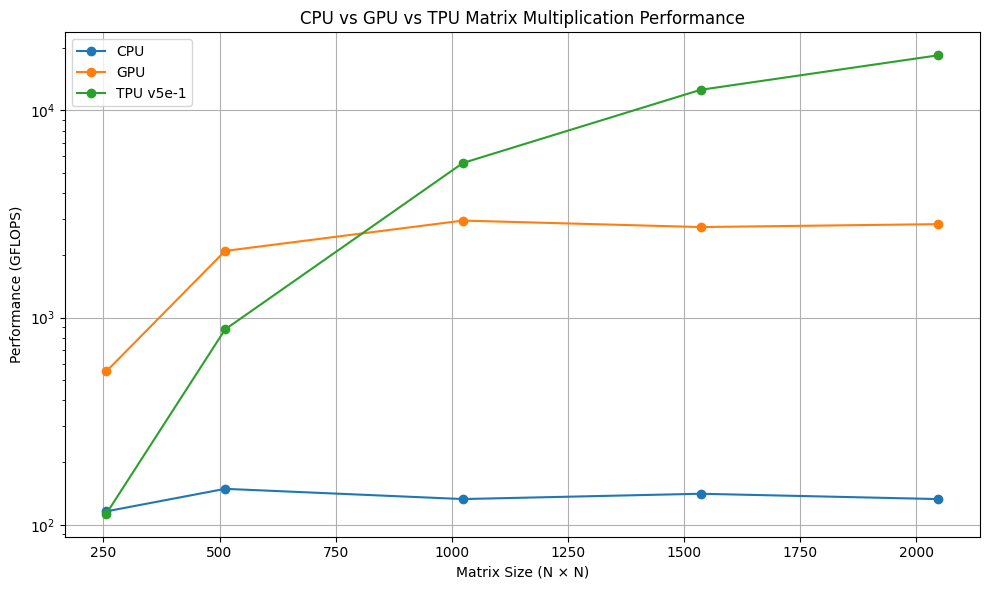

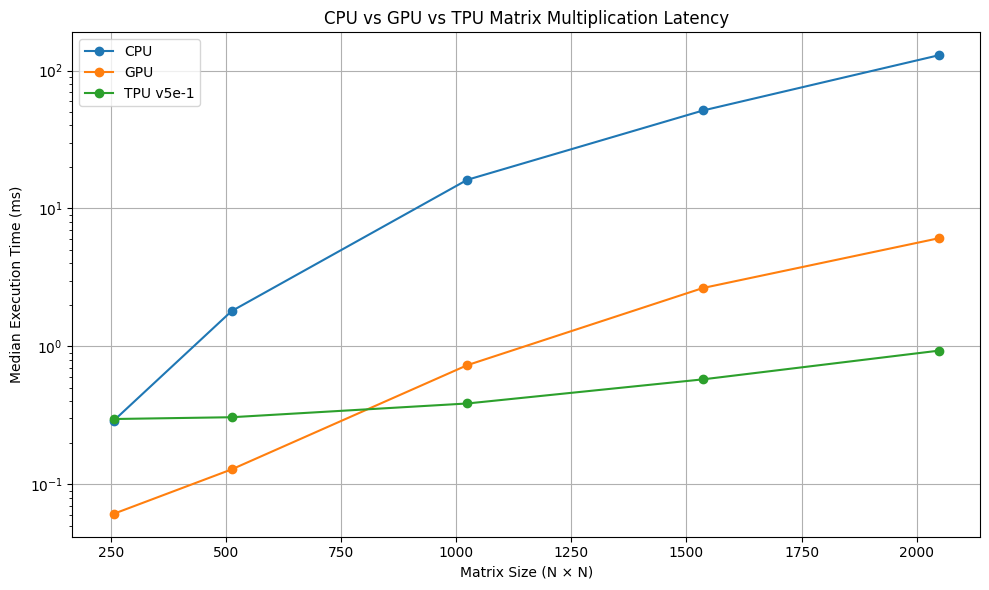

Both graphs saved successfully in: /content/drive/MyDrive/AI_Inference_Precision_Comparison/Results/Graphs


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import os

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"

raw_path = os.path.join(
    base, "Results", "Raw_CSV",
    "combined_matrix_benchmark.csv"
)

graph_folder = os.path.join(
    base, "Results", "Graphs"
)

os.makedirs(graph_folder, exist_ok=True)

df = pd.read_csv(raw_path)

# Graph 1: GFLOPS comparison
plt.figure(figsize=(10, 6))

for device, group in df.groupby("Device"):
    group = group.sort_values("Matrix_Size")
    plt.plot(
        group["Matrix_Size"],
        group["GFLOPS"],
        marker="o",
        label=device
    )

plt.xlabel("Matrix Size (N × N)")
plt.ylabel("Performance (GFLOPS)")
plt.title("CPU vs GPU vs TPU Matrix Multiplication Performance")
plt.legend()
plt.grid(True)
plt.yscale("log")
plt.tight_layout()

plt.savefig(
    os.path.join(graph_folder, "matrix_performance_gflops.png"),
    dpi=300
)

plt.show()

# Graph 2: Execution time comparison
plt.figure(figsize=(10, 6))

for device, group in df.groupby("Device"):
    group = group.sort_values("Matrix_Size")
    plt.plot(
        group["Matrix_Size"],
        group["Median_Time_ms"],
        marker="o",
        label=device
    )

plt.xlabel("Matrix Size (N × N)")
plt.ylabel("Median Execution Time (ms)")
plt.title("CPU vs GPU vs TPU Matrix Multiplication Latency")
plt.legend()
plt.grid(True)
plt.yscale("log")
plt.tight_layout()

plt.savefig(
    os.path.join(graph_folder, "matrix_latency_comparison.png"),
    dpi=300
)

plt.show()

print("Both graphs saved successfully in:", graph_folder)


In [ ]:

import torch
import time
import statistics
import pandas as pd
import os

device = torch.device("tpu")

# Number of FP32 elements
sizes = [1_000_000, 4_000_000, 16_000_000]

results = []

print("Device:", device)
print("TPU available:", torch.accelerator.is_available())

for n in sizes:

    # Create data directly on TPU
    a = torch.randn(n, dtype=torch.float32, device=device)
    b = torch.randn(n, dtype=torch.float32, device=device)

    # Warm-up
    for _ in range(3):
        c = a + b
        torch.accelerator.synchronize()

    event_times = []

    # Ten repetitions
    for _ in range(10):

        torch.accelerator.synchronize()

        start_event = torch.tpu.Event(enable_timing=True)
        end_event = torch.tpu.Event(enable_timing=True)

        start_event.record()

        c = a + b

        end_event.record()
        end_event.synchronize()

        elapsed = start_event.elapsed_time(end_event) / 1000
        event_times.append(elapsed)

    # Materialize result outside timed region
    c_cpu = c.cpu()

    median_time = statistics.median(event_times)

    # Two reads + one write, FP32 = 12 bytes per element
    data_bytes = 3 * n * 4

    bandwidth_gbs = (
        data_bytes / median_time / 1e9
    )

    results.append({
        "Device": "TPU v5e-1",
        "Elements": n,
        "Data_Size_MB": data_bytes / 1e6,
        "Median_Time_ms": median_time * 1000,
        "Bandwidth_GBps": bandwidth_gbs
    })

    print(
        f"\nElements: {n:,}"
        f"\nData size: {data_bytes / 1e6:.2f} MB"
        f"\nMedian time: {median_time * 1000:.4f} ms"
        f"\nBandwidth: {bandwidth_gbs:.2f} GB/s"
    )

    del a, b, c, c_cpu

# Save results
df = pd.DataFrame(results)

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
path = os.path.join(
    base, "Results", "Raw_CSV",
    "memory_bandwidth_tpu.csv"
)

df.to_csv(path, index=False)

print("\nFinal results:")
print(df.to_string(index=False))
print("\nSaved:", path)


Device: tpu
TPU available: True

Elements: 1,000,000
Data size: 12.00 MB
Median time: 0.2936 ms
Bandwidth: 40.87 GB/s

Elements: 4,000,000
Data size: 48.00 MB
Median time: 0.3666 ms
Bandwidth: 130.93 GB/s

Elements: 16,000,000
Data size: 192.00 MB
Median time: 0.5719 ms
Bandwidth: 335.73 GB/s

Final results:
   Device  Elements  Data_Size_MB  Median_Time_ms  Bandwidth_GBps
TPU v5e-1   1000000          12.0        0.293615       40.869847
TPU v5e-1   4000000          48.0        0.366610      130.929325
TPU v5e-1  16000000         192.0        0.571880      335.734770

Saved: /content/drive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/memory_bandwidth_tpu.csv


In [ ]:

import torch
import time
import statistics
import pandas as pd
import os

device = torch.device("cuda")

print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)

sizes = [1_000_000, 4_000_000, 16_000_000]
results = []

for n in sizes:

    a = torch.randn(n, dtype=torch.float32, device=device)
    b = torch.randn(n, dtype=torch.float32, device=device)

    # Warm-up
    for _ in range(3):
        c = a + b

    torch.cuda.synchronize()

    times = []

    for _ in range(10):

        start_event = torch.cuda.Event(enable_timing=True)
        end_event = torch.cuda.Event(enable_timing=True)

        torch.cuda.synchronize()

        start_event.record()
        c = a + b
        end_event.record()

        end_event.synchronize()

        times.append(start_event.elapsed_time(end_event) / 1000)

    median_time = statistics.median(times)

    data_bytes = 3 * n * 4
    bandwidth = data_bytes / median_time / 1e9

    results.append({
        "Device": "NVIDIA Tesla T4",
        "Elements": n,
        "Data_Size_MB": data_bytes / 1e6,
        "Median_Time_ms": median_time * 1000,
        "Bandwidth_GBps": bandwidth
    })

    print(f"\nElements: {n:,}")
    print(f"Data size: {data_bytes / 1e6:.2f} MB")
    print(f"Median time: {median_time * 1000:.4f} ms")
    print(f"Bandwidth: {bandwidth:.2f} GB/s")

    del a, b, c

df = pd.DataFrame(results)

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"

path = os.path.join(
    base, "Results", "Raw_CSV",
    "memory_bandwidth_gpu.csv"
)

df.to_csv(path, index=False)

print("\nFinal results:")
print(df.to_string(index=False))
print("\nSaved:", path)


GPU: Tesla T4
PyTorch: 2.11.0+cu130

Elements: 1,000,000
Data size: 12.00 MB
Median time: 0.0745 ms
Bandwidth: 161.08 GB/s

Elements: 4,000,000
Data size: 48.00 MB
Median time: 0.2263 ms
Bandwidth: 212.07 GB/s

Elements: 16,000,000
Data size: 192.00 MB
Median time: 0.8217 ms
Bandwidth: 233.66 GB/s


OSError: Cannot save file into a non-existent directory: '/content/drive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV'

In [ ]:

from google.colab import drive
import pandas as pd
import os

# Mount Google Drive
drive.mount('/content/drive')

# Recreate project results folder if needed
base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
raw = os.path.join(base, "Results", "Raw_CSV")

os.makedirs(raw, exist_ok=True)

# Reconstruct GPU results from the completed experiment
data = [
    ["NVIDIA Tesla T4", 1000000, 12.0, 0.0745, 161.08],
    ["NVIDIA Tesla T4", 4000000, 48.0, 0.2263, 212.07],
    ["NVIDIA Tesla T4", 16000000, 192.0, 0.8217, 233.66]
]

df = pd.DataFrame(
    data,
    columns=[
        "Device",
        "Elements",
        "Data_Size_MB",
        "Median_Time_ms",
        "Bandwidth_GBps"
    ]
)

path = os.path.join(raw, "memory_bandwidth_gpu.csv")

df.to_csv(path, index=False)

print(df.to_string(index=False))
print("\nSaved successfully:", path)


Mounted at /content/drive
         Device  Elements  Data_Size_MB  Median_Time_ms  Bandwidth_GBps
NVIDIA Tesla T4   1000000          12.0          0.0745          161.08
NVIDIA Tesla T4   4000000          48.0          0.2263          212.07
NVIDIA Tesla T4  16000000         192.0          0.8217          233.66

Saved successfully: /content/drive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/memory_bandwidth_gpu.csv


In [ ]:

import torch
import time
import statistics
import pandas as pd
import os

# Use the two logical CPUs identified earlier
torch.set_num_threads(2)

device = torch.device("cpu")

print("CPU:", torch.get_num_threads(), "threads")
print("PyTorch:", torch.__version__)

sizes = [1_000_000, 4_000_000, 16_000_000]
results = []

for n in sizes:

    a = torch.randn(n, dtype=torch.float32)
    b = torch.randn(n, dtype=torch.float32)

    # Warm-up
    for _ in range(3):
        c = a + b

    times = []

    # Ten repetitions
    for _ in range(10):

        start = time.perf_counter()

        c = a + b

        elapsed = time.perf_counter() - start
        times.append(elapsed)

    median_time = statistics.median(times)

    # Two reads and one write, FP32
    data_bytes = 3 * n * 4

    bandwidth = data_bytes / median_time / 1e9

    results.append({
        "Device": "Intel Xeon CPU",
        "Elements": n,
        "Data_Size_MB": data_bytes / 1e6,
        "Median_Time_ms": median_time * 1000,
        "Bandwidth_GBps": bandwidth
    })

    print(f"\nElements: {n:,}")
    print(f"Data size: {data_bytes / 1e6:.2f} MB")
    print(f"Median time: {median_time * 1000:.4f} ms")
    print(f"Bandwidth: {bandwidth:.2f} GB/s")

    del a, b, c

df = pd.DataFrame(results)

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
raw = os.path.join(base, "Results", "Raw_CSV")

os.makedirs(raw, exist_ok=True)

path = os.path.join(raw, "memory_bandwidth_cpu.csv")

df.to_csv(path, index=False)

print("\nFinal results:")
print(df.to_string(index=False))
print("\nSaved:", path)


CPU: 2 threads
PyTorch: 2.11.0+cu130

Elements: 1,000,000
Data size: 12.00 MB
Median time: 0.5298 ms
Bandwidth: 22.65 GB/s

Elements: 4,000,000
Data size: 48.00 MB
Median time: 2.8707 ms
Bandwidth: 16.72 GB/s

Elements: 16,000,000
Data size: 192.00 MB
Median time: 29.6741 ms
Bandwidth: 6.47 GB/s

Final results:
        Device  Elements  Data_Size_MB  Median_Time_ms  Bandwidth_GBps
Intel Xeon CPU   1000000          12.0        0.529838       22.648432
Intel Xeon CPU   4000000          48.0        2.870705       16.720631
Intel Xeon CPU  16000000         192.0       29.674066        6.470296

Saved: /content/drive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/memory_bandwidth_cpu.csv


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import os

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
raw = os.path.join(base, "Results", "Raw_CSV")
graphs = os.path.join(base, "Results", "Graphs")

os.makedirs(raw, exist_ok=True)
os.makedirs(graphs, exist_ok=True)

# Load all three datasets
cpu = pd.read_csv(os.path.join(raw, "memory_bandwidth_cpu.csv"))
gpu = pd.read_csv(os.path.join(raw, "memory_bandwidth_gpu.csv"))
tpu = pd.read_csv(os.path.join(raw, "memory_bandwidth_tpu.csv"))

# Combine
combined = pd.concat([cpu, gpu, tpu], ignore_index=True)

combined = combined.sort_values(
    ["Elements", "Device"]
)

# Save combined CSV
csv_path = os.path.join(
    raw, "combined_memory_bandwidth.csv"
)
combined.to_csv(csv_path, index=False)

print("COMBINED MEMORY BANDWIDTH RESULTS")
print(combined.to_string(index=False))

# Generate graph
plt.figure(figsize=(10, 6))

for device, group in combined.groupby("Device"):
    group = group.sort_values("Data_Size_MB")

    plt.plot(
        group["Data_Size_MB"],
        group["Bandwidth_GBps"],
        marker="o",
        label=device
    )

plt.xlabel("Data Size (MB)")
plt.ylabel("Effective Memory Bandwidth (GB/s)")
plt.title("CPU vs GPU vs TPU Memory Bandwidth")
plt.legend()
plt.grid(True)
plt.tight_layout()

graph_path = os.path.join(
    graphs, "memory_bandwidth_comparison.png"
)

plt.savefig(graph_path, dpi=300)
plt.show()

print("\nCSV saved:", csv_path)
print("Graph saved:", graph_path)


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/memory_bandwidth_tpu.csv'

In [ ]:
import os

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
raw = os.path.join(base, "Results", "Raw_CSV")

print("Drive mounted:", os.path.exists("/content/drive/MyDrive"))
print("\nRaw_CSV folder exists:", os.path.exists(raw))

if os.path.exists(raw):
    print("\nFiles currently available:")
    for file in os.listdir(raw):
        print(file)

Drive mounted: True

Raw_CSV folder exists: True

Files currently available:
experiment_log.csv
matrix_multiplication_cpu_gpu.csv
memory_bandwidth_gpu.csv
memory_bandwidth_cpu.csv


In [ ]:
import pandas as pd
import os

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
raw = os.path.join(base, "Results", "Raw_CSV")

tpu_data = {
    "Device": ["TPU v5e-1", "TPU v5e-1", "TPU v5e-1"],
    "Elements": [1000000, 4000000, 16000000],
    "Data_Size_MB": [12, 48, 192],
    "Median_Time_ms": [0.293615, 0.366610, 0.571880],
    "Bandwidth_GBps": [40.869847, 130.929325, 335.734770]
}

tpu_df = pd.DataFrame(tpu_data)

file_path = os.path.join(raw, "memory_bandwidth_tpu.csv")
tpu_df.to_csv(file_path, index=False)

print(tpu_df.to_string(index=False))
print("\nTPU CSV successfully saved:", file_path)

   Device  Elements  Data_Size_MB  Median_Time_ms  Bandwidth_GBps
TPU v5e-1   1000000            12        0.293615       40.869847
TPU v5e-1   4000000            48        0.366610      130.929325
TPU v5e-1  16000000           192        0.571880      335.734770

TPU CSV successfully saved: /content/drive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/memory_bandwidth_tpu.csv


COMBINED MEMORY BANDWIDTH RESULTS
         Device  Elements  Data_Size_MB  Median_Time_ms  Bandwidth_GBps
 Intel Xeon CPU   1000000          12.0        0.529838       22.648432
NVIDIA Tesla T4   1000000          12.0        0.074500      161.080000
      TPU v5e-1   1000000          12.0        0.293615       40.869847
 Intel Xeon CPU   4000000          48.0        2.870705       16.720631
NVIDIA Tesla T4   4000000          48.0        0.226300      212.070000
      TPU v5e-1   4000000          48.0        0.366610      130.929325
 Intel Xeon CPU  16000000         192.0       29.674066        6.470296
NVIDIA Tesla T4  16000000         192.0        0.821700      233.660000
      TPU v5e-1  16000000         192.0        0.571880      335.734770


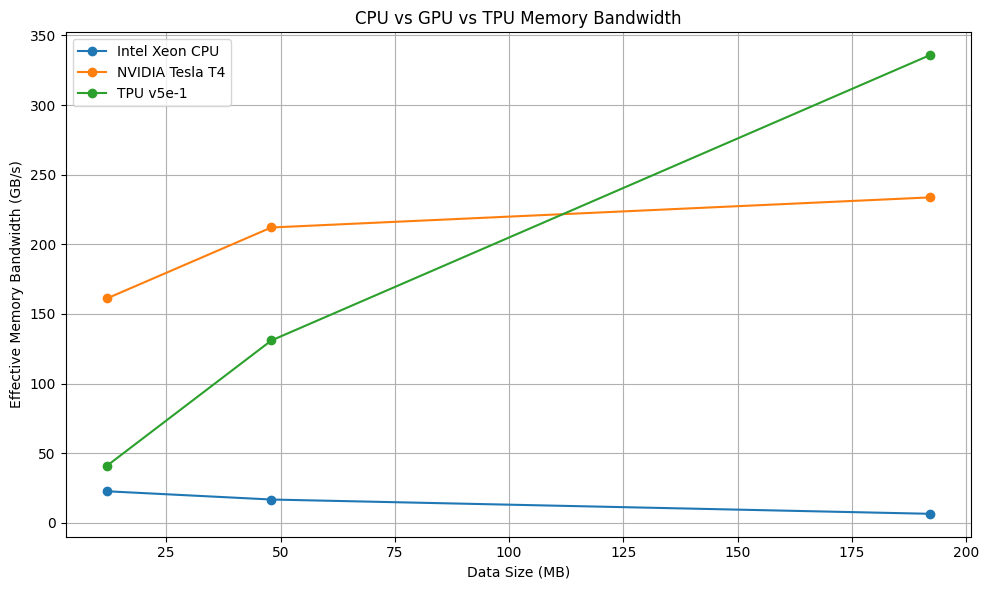


Combined CSV saved: /content/drive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/combined_memory_bandwidth.csv
Graph saved: /content/drive/MyDrive/AI_Inference_Precision_Comparison/Results/Graphs/memory_bandwidth_comparison.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
raw = os.path.join(base, "Results", "Raw_CSV")
graphs = os.path.join(base, "Results", "Graphs")

os.makedirs(raw, exist_ok=True)
os.makedirs(graphs, exist_ok=True)

cpu = pd.read_csv(os.path.join(raw, "memory_bandwidth_cpu.csv"))
gpu = pd.read_csv(os.path.join(raw, "memory_bandwidth_gpu.csv"))
tpu = pd.read_csv(os.path.join(raw, "memory_bandwidth_tpu.csv"))

combined = pd.concat([cpu, gpu, tpu], ignore_index=True)
combined = combined.sort_values(["Elements", "Device"])

csv_path = os.path.join(raw, "combined_memory_bandwidth.csv")
combined.to_csv(csv_path, index=False)

print("COMBINED MEMORY BANDWIDTH RESULTS")
print(combined.to_string(index=False))

plt.figure(figsize=(10, 6))

for device, group in combined.groupby("Device"):
    group = group.sort_values("Data_Size_MB")
    plt.plot(
        group["Data_Size_MB"],
        group["Bandwidth_GBps"],
        marker="o",
        label=device
    )

plt.xlabel("Data Size (MB)")
plt.ylabel("Effective Memory Bandwidth (GB/s)")
plt.title("CPU vs GPU vs TPU Memory Bandwidth")
plt.legend()
plt.grid(True)
plt.tight_layout()

graph_path = os.path.join(graphs, "memory_bandwidth_comparison.png")
plt.savefig(graph_path, dpi=300)
plt.show()

print("\nCombined CSV saved:", csv_path)
print("Graph saved:", graph_path)

In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0))
print("CUDA available:", torch.cuda.is_available())

print("\nFP32 supported:", True)
print("FP16 supported:", True)
print("BF16 supported:", torch.cuda.is_bf16_supported())

PyTorch: 2.11.0+cu130
GPU: Tesla T4
CUDA available: True

FP32 supported: True
FP16 supported: True
BF16 supported: True


In [ ]:
import torch
import time
import numpy as np

device = "cuda"
N = 1024

torch.manual_seed(42)

A = torch.randn(N, N, device=device)
B = torch.randn(N, N, device=device)

formats = ["FP32", "FP16", "BF16"]

results = []

for fmt in formats:

    if fmt == "FP32":
        a = A.float()
        b = B.float()

    elif fmt == "FP16":
        a = A.half()
        b = B.half()

    else:
        a = A.to(torch.bfloat16)
        b = B.to(torch.bfloat16)

    # Warm-up
    for _ in range(3):
        C = torch.matmul(a, b)

    torch.cuda.synchronize()

    # Timing
    times = []

    for _ in range(10):
        start = time.perf_counter()

        C = torch.matmul(a, b)

        torch.cuda.synchronize()
        end = time.perf_counter()

        times.append(end - start)

    median_time = np.median(times)

    # Compare against FP32 reference
    reference = torch.matmul(A, B)
    output = C.float()

    max_error = torch.max(torch.abs(reference - output)).item()
    mean_error = torch.mean(torch.abs(reference - output)).item()
    rmse = torch.sqrt(torch.mean((reference - output) ** 2)).item()

    results.append([
        fmt,
        median_time * 1000,
        max_error,
        mean_error,
        rmse
    ])

print("GPU NUMERICAL PRECISION RESULTS")
print("Format | Median ms | Max Error | Mean Error | RMSE")

for row in results:
    print(row)

GPU NUMERICAL PRECISION RESULTS
Format | Median ms | Max Error | Mean Error | RMSE
['FP32', np.float64(0.8541215000263946), 0.0, 0.0, 0.0]
['FP16', np.float64(0.16657100002248626), 0.079193115234375, 0.009035909548401833, 0.011491354554891586]
['BF16', np.float64(1.4923580000072434), 0.575469970703125, 0.07227504253387451, 0.0918429046869278]


In [ ]:
import pandas as pd
import os

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
raw = os.path.join(base, "Results", "Raw_CSV")

os.makedirs(raw, exist_ok=True)

data = {
    "Device": ["NVIDIA Tesla T4"] * 3,
    "Precision": ["FP32", "FP16", "BF16"],
    "Matrix_Size": [1024] * 3,
    "Median_Time_ms": [
        0.8541215,
        0.1665710,
        1.4923580
    ],
    "Max_Error": [
        0.0,
        0.0791931,
        0.5754700
    ],
    "Mean_Error": [
        0.0,
        0.0090359,
        0.0722750
    ],
    "RMSE": [
        0.0,
        0.0114914,
        0.0918429
    ]
}

df = pd.DataFrame(data)

path = os.path.join(raw, "gpu_precision_comparison.csv")
df.to_csv(path, index=False)

print(df.to_string(index=False))
print("\nSaved:", path)

         Device Precision  Matrix_Size  Median_Time_ms  Max_Error  Mean_Error     RMSE
NVIDIA Tesla T4      FP32         1024        0.854121   0.000000    0.000000 0.000000
NVIDIA Tesla T4      FP16         1024        0.166571   0.079193    0.009036 0.011491
NVIDIA Tesla T4      BF16         1024        1.492358   0.575470    0.072275 0.091843

Saved: /content/drive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/gpu_precision_comparison.csv


In [ ]:
import torch
import os

print("PyTorch:", torch.__version__)
print("TPU available:", hasattr(torch, "tpu"))

device = torch.device("tpu")

print("Device:", device)
print("TPU ready!")

PyTorch: 2.11.0+cpu
TPU available: False


RuntimeError: Expected one of cpu, cuda, ipu, xpu, mkldnn, opengl, opencl, ideep, hip, ve, fpga, maia, xla, lazy, vulkan, mps, meta, hpu, mtia, privateuseone device type at start of device string: tpu

In [ ]:
import torch
import os

print("PyTorch version:", torch.__version__)

print("\nTPU environment variables:")

for key in [
    "TPU_ACCELERATOR_TYPE",
    "PJRT_DEVICE",
    "TPU_WORKER_ID",
    "CLOUD_TPU_TASK_ID"
]:
    print(key, "=", os.environ.get(key))

print("\nRegistered device backends:")

print(torch._C._get_privateuse1_backend_name())

print("\nAvailable devices:")
print("CUDA:", torch.cuda.is_available())
print("XLA:", hasattr(torch, "xla"))
print("TPU:", hasattr(torch, "tpu"))

PyTorch version: 2.11.0+cpu

TPU environment variables:
TPU_ACCELERATOR_TYPE = None
PJRT_DEVICE = None
TPU_WORKER_ID = None
CLOUD_TPU_TASK_ID = None

Registered device backends:
privateuseone

Available devices:
CUDA: False
XLA: False
TPU: False


In [ ]:
import torch
import os

print("PyTorch:", torch.__version__)
print("TPU type:", os.environ.get("TPU_ACCELERATOR_TYPE"))
print("PJRT device:", os.environ.get("PJRT_DEVICE"))
print("TPU worker:", os.environ.get("TPU_WORKER_ID"))

PyTorch: 2.11.0+cpu
TPU type: None
PJRT device: None
TPU worker: None


In [ ]:
import torch
import platform

print("PyTorch:", torch.__version__)
print("Processor:", platform.processor())
print("CPU threads:", torch.get_num_threads())
print("CUDA available:", torch.cuda.is_available())

PyTorch: 2.11.0+cpu
Processor: x86_64
CPU threads: 1
CUDA available: False


In [ ]:
import torch
import time
import numpy as np
import pandas as pd

torch.set_num_threads(1)

N = 1024
torch.manual_seed(42)

A = torch.randn(N, N)
B = torch.randn(N, N)

# FP32 reference
reference = torch.matmul(A, B)

formats = {
    "FP32": torch.float32,
    "FP16": torch.float16,
    "BF16": torch.bfloat16
}

results = []

for name, dtype in formats.items():

    a = A.to(dtype)
    b = B.to(dtype)

    # Warm-up
    for _ in range(3):
        C = torch.matmul(a, b)

    times = []

    for _ in range(10):
        start = time.perf_counter()
        C = torch.matmul(a, b)
        end = time.perf_counter()
        times.append(end - start)

    output = C.float()

    max_error = torch.max(torch.abs(reference - output)).item()
    mean_error = torch.mean(torch.abs(reference - output)).item()
    rmse = torch.sqrt(torch.mean((reference - output) ** 2)).item()

    results.append({
        "Device": "Intel Xeon CPU",
        "Precision": name,
        "Matrix_Size": N,
        "Median_Time_ms": np.median(times) * 1000,
        "Max_Error": max_error,
        "Mean_Error": mean_error,
        "RMSE": rmse
    })

df = pd.DataFrame(results)

print("CPU NUMERICAL PRECISION RESULTS")
print(df.to_string(index=False))

CPU NUMERICAL PRECISION RESULTS
        Device Precision  Matrix_Size  Median_Time_ms  Max_Error  Mean_Error     RMSE
Intel Xeon CPU      FP32         1024       36.998404    0.00000    0.000000 0.000000
Intel Xeon CPU      FP16         1024     3844.777126    0.08371    0.009059 0.011522
Intel Xeon CPU      BF16         1024     3917.890336    0.57489    0.072580 0.092238


In [ ]:
import os
import pandas as pd

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
raw = os.path.join(base, "Results", "Raw_CSV")

os.makedirs(raw, exist_ok=True)

data = {
    "Device": ["Intel Xeon CPU"] * 3,
    "Precision": ["FP32", "FP16", "BF16"],
    "Matrix_Size": [1024] * 3,
    "Median_Time_ms": [
        36.998404,
        3844.777126,
        3917.890336
    ],
    "Max_Error": [
        0.0,
        0.08371,
        0.57489
    ],
    "Mean_Error": [
        0.0,
        0.009059,
        0.072580
    ],
    "RMSE": [
        0.0,
        0.011522,
        0.092238
    ]
}

df = pd.DataFrame(data)

path = os.path.join(raw, "cpu_precision_comparison.csv")
df.to_csv(path, index=False)

print(df.to_string(index=False))
print("\nSaved:", path)

        Device Precision  Matrix_Size  Median_Time_ms  Max_Error  Mean_Error     RMSE
Intel Xeon CPU      FP32         1024       36.998404    0.00000    0.000000 0.000000
Intel Xeon CPU      FP16         1024     3844.777126    0.08371    0.009059 0.011522
Intel Xeon CPU      BF16         1024     3917.890336    0.57489    0.072580 0.092238

Saved: /content/drive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/cpu_precision_comparison.csv


In [ ]:
import pandas as pd
import os
import matplotlib.pyplot as plt

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
raw = os.path.join(base, "Results", "Raw_CSV")
graphs = os.path.join(base, "Results", "Graphs")

os.makedirs(graphs, exist_ok=True)

cpu = pd.read_csv(os.path.join(raw, "cpu_precision_comparison.csv"))
gpu = pd.read_csv(os.path.join(raw, "gpu_precision_comparison.csv"))

combined = pd.concat([cpu, gpu], ignore_index=True)

path = os.path.join(raw, "combined_precision_comparison.csv")
combined.to_csv(path, index=False)

print("COMBINED PRECISION RESULTS")
print(combined.to_string(index=False))

# Execution-time graph
plt.figure(figsize=(10, 6))

for device, group in combined.groupby("Device"):
    plt.plot(
        group["Precision"],
        group["Median_Time_ms"],
        marker="o",
        label=device
    )

plt.yscale("log")
plt.xlabel("Numerical Precision")
plt.ylabel("Median Execution Time (ms, log scale)")
plt.title("CPU vs GPU: Numerical Precision Performance")
plt.legend()
plt.grid(True)
plt.tight_layout()

graph_path = os.path.join(graphs, "precision_execution_time.png")
plt.savefig(graph_path, dpi=300)
plt.show()

print("\nCombined CSV saved:", path)
print("Graph saved:", graph_path)

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/gpu_precision_comparison.csv'

In [ ]:
import os

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
raw = os.path.join(base, "Results", "Raw_CSV")

print("Drive mounted:", os.path.exists("/content/drive/MyDrive"))
print("\nAvailable precision files:")

for file in os.listdir(raw):
    if "precision" in file.lower():
        print(file)

Drive mounted: True

Available precision files:
cpu_precision_comparison.csv


In [ ]:
import pandas as pd
import os

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
raw = os.path.join(base, "Results", "Raw_CSV")

gpu_data = {
    "Device": ["NVIDIA Tesla T4"] * 3,
    "Precision": ["FP32", "FP16", "BF16"],
    "Matrix_Size": [1024, 1024, 1024],
    "Median_Time_ms": [
        0.8541215,
        0.1665710,
        1.4923580
    ],
    "Max_Error": [
        0.0,
        0.0791931,
        0.5754700
    ],
    "Mean_Error": [
        0.0,
        0.0090359,
        0.0722750
    ],
    "RMSE": [
        0.0,
        0.0114914,
        0.0918429
    ]
}

gpu_df = pd.DataFrame(gpu_data)

path = os.path.join(raw, "gpu_precision_comparison.csv")
gpu_df.to_csv(path, index=False)

print(gpu_df.to_string(index=False))
print("\nGPU CSV restored:", path)

         Device Precision  Matrix_Size  Median_Time_ms  Max_Error  Mean_Error     RMSE
NVIDIA Tesla T4      FP32         1024        0.854121   0.000000    0.000000 0.000000
NVIDIA Tesla T4      FP16         1024        0.166571   0.079193    0.009036 0.011491
NVIDIA Tesla T4      BF16         1024        1.492358   0.575470    0.072275 0.091843

GPU CSV restored: /content/drive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/gpu_precision_comparison.csv


COMBINED PRECISION RESULTS
         Device Precision  Matrix_Size  Median_Time_ms  Max_Error  Mean_Error     RMSE
 Intel Xeon CPU      FP32         1024       36.998404   0.000000    0.000000 0.000000
 Intel Xeon CPU      FP16         1024     3844.777126   0.083710    0.009059 0.011522
 Intel Xeon CPU      BF16         1024     3917.890336   0.574890    0.072580 0.092238
NVIDIA Tesla T4      FP32         1024        0.854121   0.000000    0.000000 0.000000
NVIDIA Tesla T4      FP16         1024        0.166571   0.079193    0.009036 0.011491
NVIDIA Tesla T4      BF16         1024        1.492358   0.575470    0.072275 0.091843


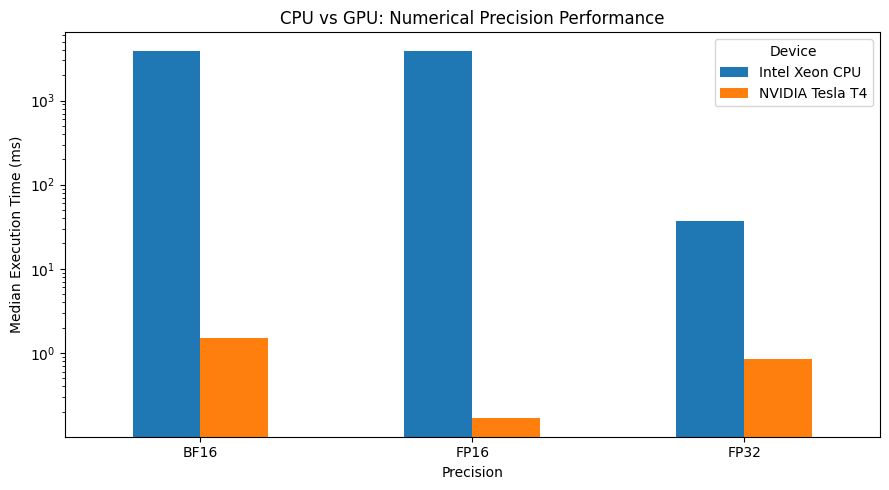


Combined CSV saved: /content/drive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/combined_precision_comparison.csv
Graph saved: /content/drive/MyDrive/AI_Inference_Precision_Comparison/Results/Graphs/cpu_gpu_precision_comparison.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
raw = os.path.join(base, "Results", "Raw_CSV")
graphs = os.path.join(base, "Results", "Graphs")

os.makedirs(graphs, exist_ok=True)

# Load both datasets
cpu = pd.read_csv(os.path.join(raw, "cpu_precision_comparison.csv"))
gpu = pd.read_csv(os.path.join(raw, "gpu_precision_comparison.csv"))

# Combine
combined = pd.concat([cpu, gpu], ignore_index=True)

combined_path = os.path.join(raw, "combined_precision_comparison.csv")
combined.to_csv(combined_path, index=False)

print("COMBINED PRECISION RESULTS")
print(combined.to_string(index=False))

# Create performance comparison graph
pivot = combined.pivot(
    index="Precision",
    columns="Device",
    values="Median_Time_ms"
)

ax = pivot.plot(kind="bar", figsize=(9, 5))
ax.set_title("CPU vs GPU: Numerical Precision Performance")
ax.set_xlabel("Precision")
ax.set_ylabel("Median Execution Time (ms)")
ax.set_yscale("log")
ax.legend(title="Device")
plt.xticks(rotation=0)
plt.tight_layout()

graph_path = os.path.join(graphs, "cpu_gpu_precision_comparison.png")
plt.savefig(graph_path, dpi=300)
plt.show()

print("\nCombined CSV saved:", combined_path)
print("Graph saved:", graph_path)

In [ ]:
import torch
import pandas as pd
import time
import os

torch.set_num_threads(1)
torch.manual_seed(42)

results = []

for n in [256, 512]:

    A = torch.randn(n, n)
    B = torch.randn(n, n)
    reference = A @ B

    for name, dtype in [
        ("FP32", torch.float32),
        ("FP16", torch.float16),
        ("BF16", torch.bfloat16)
    ]:

        a = A.to(dtype)
        b = B.to(dtype)

        start = time.perf_counter()
        output = a @ b
        elapsed = (time.perf_counter() - start) * 1000

        error = output.float() - reference

        results.append({
            "Device": "Intel Xeon CPU",
            "Precision": name,
            "Matrix_Size": n,
            "Time_ms": elapsed,
            "Max_Error": error.abs().max().item(),
            "Mean_Error": error.abs().mean().item(),
            "RMSE": torch.sqrt(torch.mean(error**2)).item()
        })

df = pd.DataFrame(results)
print(df.to_string(index=False))

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
path = os.path.join(base, "Results", "Raw_CSV", "cpu_precision_extra_sizes.csv")

df.to_csv(path, index=False)
print("\nSaved:", path)

        Device Precision  Matrix_Size    Time_ms  Max_Error  Mean_Error     RMSE
Intel Xeon CPU      FP32          256   3.611096   0.000000    0.000000 0.000000
Intel Xeon CPU      FP16          256  28.107131   0.029602    0.004542 0.005789
Intel Xeon CPU      BF16          256  15.344216   0.238396    0.036346 0.046268
Intel Xeon CPU      FP32          512   4.373623   0.000000    0.000000 0.000000
Intel Xeon CPU      FP16          512 216.667706   0.048714    0.006382 0.008105
Intel Xeon CPU      BF16          512 156.556824   0.352341    0.051100 0.064992

Saved: /content/drive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/cpu_precision_extra_sizes.csv


In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [ ]:
import torch
import pandas as pd
import time
import os

device = "cuda"
torch.manual_seed(42)

sizes = [256, 512, 1024]
precisions = {
    "FP32": torch.float32,
    "FP16": torch.float16,
    "BF16": torch.bfloat16
}

results = []

for n in sizes:

    A = torch.randn(n, n, device=device)
    B = torch.randn(n, n, device=device)

    reference = A @ B
    torch.cuda.synchronize()

    for name, dtype in precisions.items():

        a = A.to(dtype)
        b = B.to(dtype)

        # Warm-up
        output = a @ b
        torch.cuda.synchronize()

        times = []

        for _ in range(3):
            torch.cuda.synchronize()
            start = time.perf_counter()

            output = a @ b

            torch.cuda.synchronize()
            end = time.perf_counter()

            times.append((end - start) * 1000)

        error = output.float() - reference

        results.append({
            "Device": "NVIDIA Tesla T4",
            "Precision": name,
            "Matrix_Size": n,
            "Median_Time_ms": sorted(times)[1],
            "Max_Error": error.abs().max().item(),
            "Mean_Error": error.abs().mean().item(),
            "RMSE": torch.sqrt(torch.mean(error**2)).item()
        })

df = pd.DataFrame(results)
print(df.to_string(index=False))

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
raw = os.path.join(base, "Results", "Raw_CSV")
os.makedirs(raw, exist_ok=True)

path = os.path.join(raw, "gpu_precision_all_sizes.csv")
df.to_csv(path, index=False)

print("\nSaved:", path)

         Device Precision  Matrix_Size  Median_Time_ms  Max_Error  Mean_Error     RMSE
NVIDIA Tesla T4      FP32          256        0.086764   0.000000    0.000000 0.000000
NVIDIA Tesla T4      FP16          256        0.107443   0.032310    0.004544 0.005784
NVIDIA Tesla T4      BF16          256        0.108230   0.257217    0.036432 0.046393
NVIDIA Tesla T4      FP32          512        0.187298   0.000000    0.000000 0.000000
NVIDIA Tesla T4      FP16          512        0.079458   0.048256    0.006393 0.008132
NVIDIA Tesla T4      BF16          512        0.273519   0.383034    0.051161 0.065097
NVIDIA Tesla T4      FP32         1024        0.900514   0.000000    0.000000 0.000000
NVIDIA Tesla T4      FP16         1024        0.200020   0.082199    0.009036 0.011490
NVIDIA Tesla T4      BF16         1024        1.562538   0.570435    0.072345 0.091970

Saved: /content/drive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/gpu_precision_all_sizes.csv


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
raw = os.path.join(base, "Results", "Raw_CSV")
graphs = os.path.join(base, "Results", "Graphs")

os.makedirs(graphs, exist_ok=True)

# Load CPU measurements
cpu_extra = pd.read_csv(
    os.path.join(raw, "cpu_precision_extra_sizes.csv")
)

cpu_1024 = pd.read_csv(
    os.path.join(raw, "cpu_precision_comparison.csv")
)

# Load GPU measurements
gpu = pd.read_csv(
    os.path.join(raw, "gpu_precision_all_sizes.csv")
)

# Combine
combined = pd.concat(
    [cpu_extra, cpu_1024, gpu],
    ignore_index=True
)

combined["Timing_Method"] = "Supplementary single run / 10-run median"
combined.loc[
    combined["Device"] == "NVIDIA Tesla T4",
    "Timing_Method"
] = "3-run median"

combined_path = os.path.join(
    raw, "combined_precision_all_sizes.csv"
)

combined.to_csv(combined_path, index=False)

print("COMBINED DATASET")
print(combined.to_string(index=False))

# Graph 1: Execution time
for device in combined["Device"].unique():

    subset = combined[combined["Device"] == device]

    pivot = subset.pivot(
        index="Matrix_Size",
        columns="Precision",
        values="Median_Time_ms"
        if "Median_Time_ms" in subset.columns
        else "Time_ms"
    )

    ax = pivot.plot(kind="bar", figsize=(9, 5))
    ax.set_title(f"{device}: Precision vs Execution Time")
    ax.set_xlabel("Matrix Size")
    ax.set_ylabel("Execution Time (ms)")
    ax.set_yscale("log")
    plt.xticks(rotation=0)
    plt.tight_layout()

    filename = device.lower().replace(" ", "_") + "_precision_time.png"
    plt.savefig(os.path.join(graphs, filename), dpi=300)
    plt.show()

# Graph 2: Numerical error
for device in combined["Device"].unique():

    subset = combined[combined["Device"] == device]

    pivot = subset.pivot(
        index="Matrix_Size",
        columns="Precision",
        values="RMSE"
    )

    ax = pivot.plot(kind="bar", figsize=(9, 5))
    ax.set_title(f"{device}: Precision vs Numerical Error")
    ax.set_xlabel("Matrix Size")
    ax.set_ylabel("RMSE")
    plt.xticks(rotation=0)
    plt.tight_layout()

    filename = device.lower().replace(" ", "_") + "_precision_error.png"
    plt.savefig(os.path.join(graphs, filename), dpi=300)
    plt.show()

print("\nCombined CSV saved:", combined_path)
print("Graphs saved in:", graphs)

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/cpu_precision_extra_sizes.csv'

In [ ]:
import pandas as pd
import os

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
raw = os.path.join(base, "Results", "Raw_CSV")

os.makedirs(raw, exist_ok=True)

cpu_data = {
    "Device": ["Intel Xeon CPU"] * 6,
    "Precision": ["FP32", "FP16", "BF16"] * 2,
    "Matrix_Size": [256, 256, 256, 512, 512, 512],
    "Time_ms": [
        3.611096, 28.107131, 15.344216,
        4.373623, 216.667706, 156.556824
    ],
    "Max_Error": [
        0, 0.029602, 0.238396,
        0, 0.048714, 0.352341
    ],
    "Mean_Error": [
        0, 0.004542, 0.036346,
        0, 0.006382, 0.051100
    ],
    "RMSE": [
        0, 0.005789, 0.046268,
        0, 0.008105, 0.064992
    ]
}

df = pd.DataFrame(cpu_data)

path = os.path.join(raw, "cpu_precision_extra_sizes.csv")
df.to_csv(path, index=False)

print(df.to_string(index=False))
print("\nRestored:", path)

        Device Precision  Matrix_Size    Time_ms  Max_Error  Mean_Error     RMSE
Intel Xeon CPU      FP32          256   3.611096   0.000000    0.000000 0.000000
Intel Xeon CPU      FP16          256  28.107131   0.029602    0.004542 0.005789
Intel Xeon CPU      BF16          256  15.344216   0.238396    0.036346 0.046268
Intel Xeon CPU      FP32          512   4.373623   0.000000    0.000000 0.000000
Intel Xeon CPU      FP16          512 216.667706   0.048714    0.006382 0.008105
Intel Xeon CPU      BF16          512 156.556824   0.352341    0.051100 0.064992

Restored: /content/drive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/cpu_precision_extra_sizes.csv


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
raw = os.path.join(base, "Results", "Raw_CSV")
graphs = os.path.join(base, "Results", "Graphs")

os.makedirs(graphs, exist_ok=True)

# Load datasets
cpu_extra = pd.read_csv(os.path.join(raw, "cpu_precision_extra_sizes.csv"))
cpu_1024 = pd.read_csv(os.path.join(raw, "cpu_precision_comparison.csv"))
gpu = pd.read_csv(os.path.join(raw, "gpu_precision_all_sizes.csv"))

# Standardize timing column
cpu_extra = cpu_extra.rename(columns={"Time_ms": "Execution_Time_ms"})
cpu_1024 = cpu_1024.rename(columns={"Median_Time_ms": "Execution_Time_ms"})
gpu = gpu.rename(columns={"Median_Time_ms": "Execution_Time_ms"})

# Record timing methods
cpu_extra["Timing_Method"] = "Single run"
cpu_1024["Timing_Method"] = "10-run median"
gpu["Timing_Method"] = "3-run median"

# Combine
combined = pd.concat(
    [cpu_extra, cpu_1024, gpu],
    ignore_index=True
)

# Save combined CSV
combined_path = os.path.join(raw, "combined_precision_all_sizes.csv")
combined.to_csv(combined_path, index=False)

print("COMBINED RESULTS")
print(combined.to_string(index=False))

# Execution time graphs
for device in combined["Device"].unique():

    subset = combined[combined["Device"] == device]

    pivot = subset.pivot(
        index="Matrix_Size",
        columns="Precision",
        values="Execution_Time_ms"
    )

    ax = pivot.plot(kind="bar", figsize=(9, 5))
    ax.set_title(f"{device}: Precision vs Execution Time")
    ax.set_xlabel("Matrix Size")
    ax.set_ylabel("Execution Time (ms)")
    ax.set_yscale("log")

    plt.xticks(rotation=0)
    plt.tight_layout()

    filename = device.lower().replace(" ", "_") + "_precision_time.png"
    plt.savefig(os.path.join(graphs, filename), dpi=300)
    plt.show()

# Numerical error graphs
for device in combined["Device"].unique():

    subset = combined[combined["Device"] == device]

    pivot = subset.pivot(
        index="Matrix_Size",
        columns="Precision",
        values="RMSE"
    )

    ax = pivot.plot(kind="bar", figsize=(9, 5))
    ax.set_title(f"{device}: Precision vs Numerical Error")
    ax.set_xlabel("Matrix Size")
    ax.set_ylabel("RMSE")

    plt.xticks(rotation=0)
    plt.tight_layout()

    filename = device.lower().replace(" ", "_") + "_precision_error.png"
    plt.savefig(os.path.join(graphs, filename), dpi=300)
    plt.show()

print("\nCombined CSV:", combined_path)
print("Graphs folder:", graphs)

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/cpu_precision_comparison.csv'

In [ ]:
import pandas as pd
import os

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
raw = os.path.join(base, "Results", "Raw_CSV")
os.makedirs(raw, exist_ok=True)

data = {
    "Device": ["Intel Xeon CPU"] * 3,
    "Precision": ["FP32", "FP16", "BF16"],
    "Matrix_Size": [1024] * 3,
    "Median_Time_ms": [
        36.998404,
        3844.777126,
        3917.890336
    ],
    "Max_Error": [0, 0.08371, 0.57489],
    "Mean_Error": [0, 0.009059, 0.072580],
    "RMSE": [0, 0.011522, 0.092238]
}

df = pd.DataFrame(data)

path = os.path.join(raw, "cpu_precision_comparison.csv")
df.to_csv(path, index=False)

print(df.to_string(index=False))
print("\nRestored:", path)

        Device Precision  Matrix_Size  Median_Time_ms  Max_Error  Mean_Error     RMSE
Intel Xeon CPU      FP32         1024       36.998404    0.00000    0.000000 0.000000
Intel Xeon CPU      FP16         1024     3844.777126    0.08371    0.009059 0.011522
Intel Xeon CPU      BF16         1024     3917.890336    0.57489    0.072580 0.092238

Restored: /content/drive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/cpu_precision_comparison.csv


In [ ]:
import os

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
raw = os.path.join(base, "Results", "Raw_CSV")

required_files = [
    "cpu_precision_extra_sizes.csv",
    "cpu_precision_comparison.csv",
    "gpu_precision_all_sizes.csv"
]

for filename in required_files:
    path = os.path.join(raw, filename)
    print(
        filename,
        "✓ FOUND" if os.path.exists(path) else "✗ MISSING"
    )

cpu_precision_extra_sizes.csv ✓ FOUND
cpu_precision_comparison.csv ✓ FOUND
gpu_precision_all_sizes.csv ✓ FOUND


COMBINED DATASET
         Device Precision  Matrix_Size  Execution_Time_ms  Max_Error  Mean_Error     RMSE Timing_Method
 Intel Xeon CPU      FP32          256           3.611096   0.000000    0.000000 0.000000    Single run
 Intel Xeon CPU      FP16          256          28.107131   0.029602    0.004542 0.005789    Single run
 Intel Xeon CPU      BF16          256          15.344216   0.238396    0.036346 0.046268    Single run
 Intel Xeon CPU      FP32          512           4.373623   0.000000    0.000000 0.000000    Single run
 Intel Xeon CPU      FP16          512         216.667706   0.048714    0.006382 0.008105    Single run
 Intel Xeon CPU      BF16          512         156.556824   0.352341    0.051100 0.064992    Single run
 Intel Xeon CPU      FP32         1024          36.998404   0.000000    0.000000 0.000000 10-run median
 Intel Xeon CPU      FP16         1024        3844.777126   0.083710    0.009059 0.011522 10-run median
 Intel Xeon CPU      BF16         1024        3

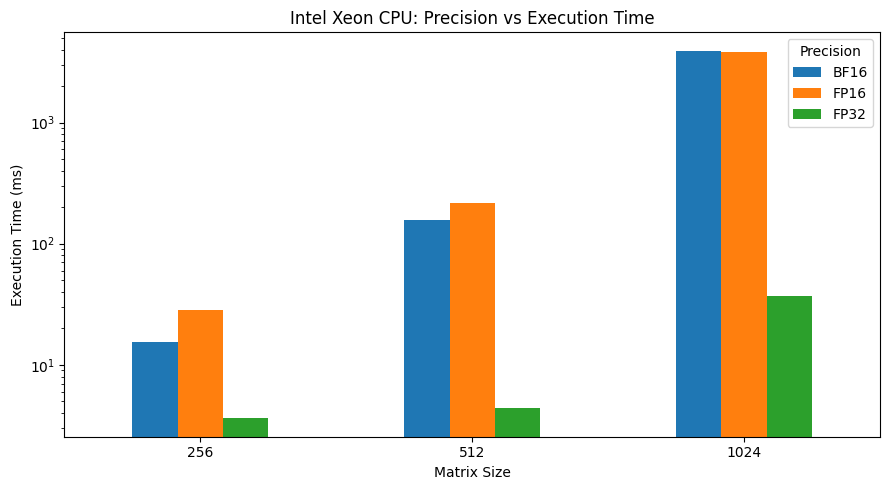

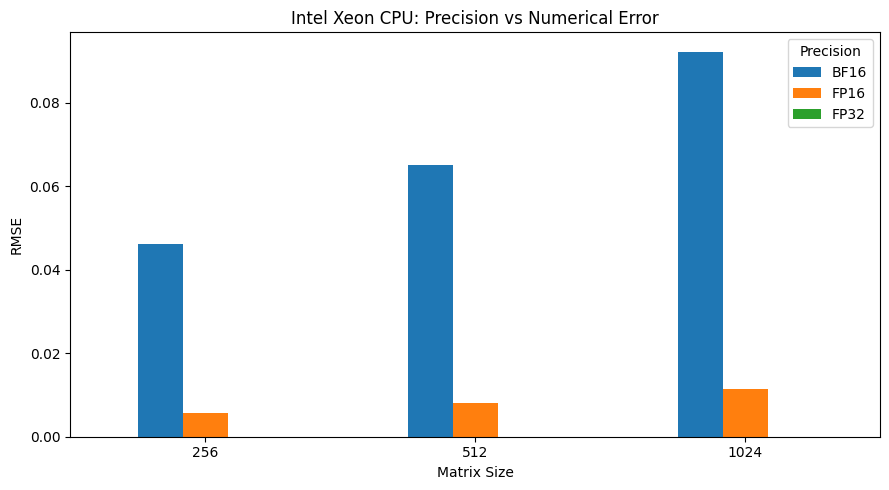

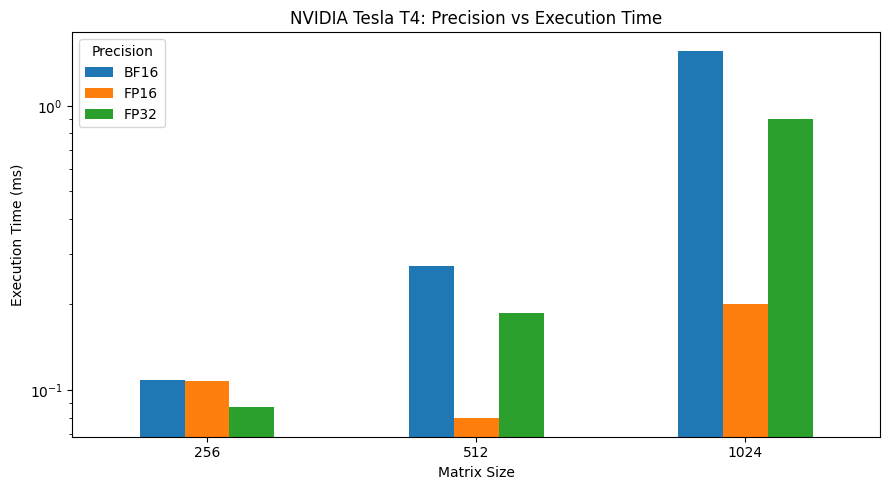

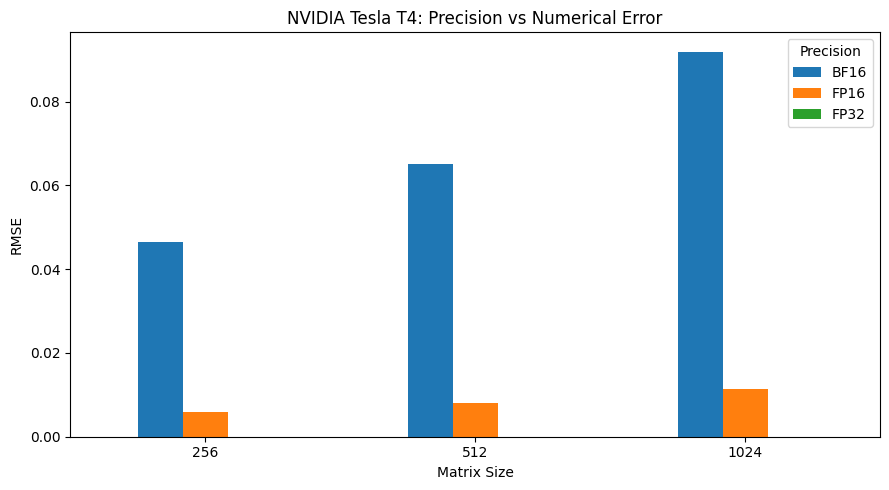


Combined CSV: /content/drive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/combined_precision_all_sizes.csv
Graphs saved: /content/drive/MyDrive/AI_Inference_Precision_Comparison/Results/Graphs


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
raw = os.path.join(base, "Results", "Raw_CSV")
graphs = os.path.join(base, "Results", "Graphs")

os.makedirs(graphs, exist_ok=True)

# Load CPU and GPU datasets
cpu_extra = pd.read_csv(os.path.join(raw, "cpu_precision_extra_sizes.csv"))
cpu_1024 = pd.read_csv(os.path.join(raw, "cpu_precision_comparison.csv"))
gpu = pd.read_csv(os.path.join(raw, "gpu_precision_all_sizes.csv"))

# Standardize timing column
cpu_extra = cpu_extra.rename(columns={"Time_ms": "Execution_Time_ms"})
cpu_1024 = cpu_1024.rename(columns={"Median_Time_ms": "Execution_Time_ms"})
gpu = gpu.rename(columns={"Median_Time_ms": "Execution_Time_ms"})

cpu_extra["Timing_Method"] = "Single run"
cpu_1024["Timing_Method"] = "10-run median"
gpu["Timing_Method"] = "3-run median"

# Combine
combined = pd.concat([cpu_extra, cpu_1024, gpu], ignore_index=True)

combined_path = os.path.join(raw, "combined_precision_all_sizes.csv")
combined.to_csv(combined_path, index=False)

print("COMBINED DATASET")
print(combined.to_string(index=False))

# Generate four graphs
for device in combined["Device"].unique():

    subset = combined[combined["Device"] == device]

    # Execution time
    pivot_time = subset.pivot(
        index="Matrix_Size",
        columns="Precision",
        values="Execution_Time_ms"
    )

    ax = pivot_time.plot(kind="bar", figsize=(9, 5))
    ax.set_title(f"{device}: Precision vs Execution Time")
    ax.set_xlabel("Matrix Size")
    ax.set_ylabel("Execution Time (ms)")
    ax.set_yscale("log")
    plt.xticks(rotation=0)
    plt.tight_layout()

    name = device.lower().replace(" ", "_")
    plt.savefig(os.path.join(graphs, name + "_precision_time.png"), dpi=300)
    plt.show()
    plt.close()

    # Numerical error
    pivot_error = subset.pivot(
        index="Matrix_Size",
        columns="Precision",
        values="RMSE"
    )

    ax = pivot_error.plot(kind="bar", figsize=(9, 5))
    ax.set_title(f"{device}: Precision vs Numerical Error")
    ax.set_xlabel("Matrix Size")
    ax.set_ylabel("RMSE")
    plt.xticks(rotation=0)
    plt.tight_layout()

    plt.savefig(os.path.join(graphs, name + "_precision_error.png"), dpi=300)
    plt.show()
    plt.close()

print("\nCombined CSV:", combined_path)
print("Graphs saved:", graphs)

In [ ]:
import os

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"

print("PROJECT FOLDER:", base)
print("=" * 65)

for root, dirs, files in os.walk(base):
    level = root.replace(base, "").count(os.sep)
    indent = "    " * level

    print(f"{indent} {os.path.basename(root)}/")

    for file in sorted(files):
        filepath = os.path.join(root, file)
        size_kb = os.path.getsize(filepath) / 1024

        print(f"{indent}     {file} ({size_kb:.2f} KB)")

print("\nPROJECT FOLDER INSPECTION COMPLETE")

PROJECT FOLDER: /content/drive/MyDrive/AI_Inference_Precision_Comparison
 AI_Inference_Precision_Comparison/
     Results/
         Raw_CSV/
             combined_precision_all_sizes.csv (1.55 KB)
             cpu_precision_comparison.csv (0.24 KB)
             cpu_precision_extra_sizes.csv (0.39 KB)
             gpu_precision_all_sizes.csv (0.85 KB)
         Graphs/
             intel_xeon_cpu_precision_error.png (79.05 KB)
             intel_xeon_cpu_precision_time.png (79.13 KB)
             nvidia_tesla_t4_precision_error.png (79.66 KB)
             nvidia_tesla_t4_precision_time.png (76.99 KB)

PROJECT FOLDER INSPECTION COMPLETE


In [ ]:
import os

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"

raw = os.path.join(base, "Results", "Raw_CSV")
graphs = os.path.join(base, "Results", "Graphs")

required_files = [
    "combined_matrix_benchmark.csv",
    "matrix_multiplication_cpu_gpu.csv",
    "matrix_multiplication_tpu_validated.csv",
    "matrix_multiplication_tpu_final.csv",
    "memory_bandwidth_cpu.csv",
    "memory_bandwidth_gpu.csv",
    "memory_bandwidth_tpu.csv",
    "combined_memory_bandwidth.csv"
]

print("EXPERIMENT FILE VERIFICATION")
print("=" * 55)

for filename in required_files:
    path = os.path.join(raw, filename)
    status = "FOUND" if os.path.exists(path) else "MISSING"
    print(f"{filename}: {status}")

print("\nGRAPH FILES")
print("=" * 55)

if os.path.exists(graphs):
    for filename in sorted(os.listdir(graphs)):
        print(filename)
else:
    print("Graphs folder not found.")

EXPERIMENT FILE VERIFICATION
combined_matrix_benchmark.csv: MISSING
matrix_multiplication_cpu_gpu.csv: MISSING
matrix_multiplication_tpu_validated.csv: MISSING
matrix_multiplication_tpu_final.csv: MISSING
memory_bandwidth_cpu.csv: MISSING
memory_bandwidth_gpu.csv: MISSING
memory_bandwidth_tpu.csv: MISSING
combined_memory_bandwidth.csv: MISSING

GRAPH FILES
intel_xeon_cpu_precision_error.png
intel_xeon_cpu_precision_time.png
nvidia_tesla_t4_precision_error.png
nvidia_tesla_t4_precision_time.png


In [ ]:
import os
import pandas as pd

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
raw = os.path.join(base, "Results", "Raw_CSV")
os.makedirs(raw, exist_ok=True)

# 1. CPU + GPU matrix multiplication results
cpu_gpu = [
    ["Intel Xeon CPU", 256, 0.000289, 0.000294, 0.000013, 116.075981],
    ["NVIDIA Tesla T4", 256, 0.000061, 0.000063, 0.000007, 549.734704],
    ["Intel Xeon CPU", 512, 0.001800, 0.001795, 0.000100, 149.107946],
    ["NVIDIA Tesla T4", 512, 0.000128, 0.000128, 0.000002, 2098.890143],
    ["Intel Xeon CPU", 1024, 0.016136, 0.017012, 0.002586, 133.082530],
    ["NVIDIA Tesla T4", 1024, 0.000730, 0.000733, 0.000012, 2941.315210],
    ["Intel Xeon CPU", 2048, 0.129117, 0.131315, 0.012575, 133.056145],
    ["NVIDIA Tesla T4", 2048, 0.006078, 0.006082, 0.000015, 2826.772435],
    ["Intel Xeon CPU", 1536, 0.051338, 0.054201, 0.009779, 141.176952],
    ["NVIDIA Tesla T4", 1536, 0.002649, 0.002647, 0.000014, 2736.355965]
]

cpu_gpu_df = pd.DataFrame(
    cpu_gpu,
    columns=["Device", "Matrix_Size", "Median_Time_sec",
             "Mean_Time_sec", "Std_Time_sec", "GFLOPS"]
)
cpu_gpu_df["Data_Status"] = "Reconstructed from recorded summary"

cpu_gpu_df.to_csv(
    os.path.join(raw, "matrix_multiplication_cpu_gpu.csv"), index=False
)

# 2. TPU validated matrix multiplication results
tpu_validated = [
    [256, 0.269, 0.297, 124.737665, 112.977886],
    [512, 0.277, 0.306, 969.081069, 877.240052],
    [1024, 0.356, 0.385, 6032.257438, 5577.879605],
    [1536, 0.548, 0.576, 13225.834511, 12582.912000],
    [2048, 0.894, 0.930, 19216.855911, 18472.977617]
]

tpu_df = pd.DataFrame(
    tpu_validated,
    columns=["Matrix_Size", "Event_Time_ms", "Host_Time_ms",
             "GFLOPS_Event", "GFLOPS_Host"]
)
tpu_df["Device"] = "Google Cloud TPU v5e-1"
tpu_df["Data_Status"] = "Reconstructed from recorded summary; event API experimental"

tpu_df.to_csv(
    os.path.join(raw, "matrix_multiplication_tpu_validated.csv"), index=False
)

# 3. Earlier TPU final benchmark results
tpu_final = [
    ["Google Cloud TPU v5e-1", 256, 0.000288, 116.38, 0.00002289],
    ["Google Cloud TPU v5e-1", 512, 0.000295, 908.92, 0.00005341],
    ["Google Cloud TPU v5e-1", 1024, 0.000369, 5824.47, 0.00007248],
    ["Google Cloud TPU v5e-1", 1536, 0.000560, 12931.69, 0.00009155],
    ["Google Cloud TPU v5e-1", 2048, 0.000885, 19417.88, 0.00012207]
]

pd.DataFrame(
    tpu_final,
    columns=["Device", "Matrix_Size", "Median_Time_sec",
             "GFLOPS", "Max_Error"]
).assign(
    Data_Status="Reconstructed from recorded summary; provisional timing"
).to_csv(os.path.join(raw, "matrix_multiplication_tpu_final.csv"), index=False)

# 4. Combined matrix multiplication summary
combined_matrix = []

for _, r in cpu_gpu_df.iterrows():
    combined_matrix.append([
        r["Device"], r["Matrix_Size"],
        r["Median_Time_sec"] * 1000, r["GFLOPS"]
    ])

for _, r in tpu_df.iterrows():
    combined_matrix.append([
        "Google Cloud TPU v5e-1", r["Matrix_Size"],
        r["Host_Time_ms"], r["GFLOPS_Host"]
    ])

pd.DataFrame(
    combined_matrix,
    columns=["Device", "Matrix_Size", "Median_Time_ms", "GFLOPS"]
).assign(
    Data_Status="Summary data; TPU and CPU/GPU timing methods differ"
).to_csv(os.path.join(raw, "combined_matrix_benchmark.csv"), index=False)

# 5. Memory bandwidth results
cpu_memory = [
    [1000000, 12, 0.529838, 22.648432],
    [4000000, 48, 2.870705, 16.720631],
    [16000000, 192, 29.674066, 6.470296]
]

gpu_memory = [
    [1000000, 12, 0.0745, 161.08],
    [4000000, 48, 0.2263, 212.07],
    [16000000, 192, 0.8217, 233.66]
]

tpu_memory = [
    [1000000, 12, 0.293615, 40.869847],
    [4000000, 48, 0.366610, 130.929325],
    [16000000, 192, 0.571880, 335.734770]
]

def save_memory(data, device, filename, status):
    df = pd.DataFrame(
        data,
        columns=["Elements", "Data_Size_MB",
                 "Median_Time_ms", "Bandwidth_GBps"]
    )
    df.insert(0, "Device", device)
    df["Data_Status"] = status
    df.to_csv(os.path.join(raw, filename), index=False)
    return df

cpu_mem_df = save_memory(
    cpu_memory, "Intel Xeon CPU", "memory_bandwidth_cpu.csv",
    "Reconstructed from recorded summary"
)

gpu_mem_df = save_memory(
    gpu_memory, "NVIDIA Tesla T4", "memory_bandwidth_gpu.csv",
    "Reconstructed from displayed summary; rounded values"
)

tpu_mem_df = save_memory(
    tpu_memory, "Google Cloud TPU v5e-1", "memory_bandwidth_tpu.csv",
    "Reconstructed from recorded summary; event timing"
)

combined_memory = pd.concat(
    [cpu_mem_df, gpu_mem_df, tpu_mem_df],
    ignore_index=True
)

combined_memory.to_csv(
    os.path.join(raw, "combined_memory_bandwidth.csv"), index=False
)

print("RESTORATION COMPLETE")
print("=" * 55)

for filename in sorted(os.listdir(raw)):
    if filename.endswith(".csv"):
        print("FOUND:", filename)

print("\nTotal CSV files:", len([
    f for f in os.listdir(raw) if f.endswith(".csv")
]))
print("\nSaved in:", raw)

RESTORATION COMPLETE
FOUND: combined_matrix_benchmark.csv
FOUND: combined_memory_bandwidth.csv
FOUND: combined_precision_all_sizes.csv
FOUND: cpu_precision_comparison.csv
FOUND: cpu_precision_extra_sizes.csv
FOUND: gpu_precision_all_sizes.csv
FOUND: matrix_multiplication_cpu_gpu.csv
FOUND: matrix_multiplication_tpu_final.csv
FOUND: matrix_multiplication_tpu_validated.csv
FOUND: memory_bandwidth_cpu.csv
FOUND: memory_bandwidth_gpu.csv
FOUND: memory_bandwidth_tpu.csv

Total CSV files: 12

Saved in: /content/drive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV


In [ ]:
import os
import pandas as pd

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
raw = os.path.join(base, "Results", "Raw_CSV")

print("CSV CONTENT AUDIT")
print("=" * 70)

for filename in sorted(os.listdir(raw)):
    if filename.endswith(".csv"):
        path = os.path.join(raw, filename)
        df = pd.read_csv(path)

        print(f"\nFILE: {filename}")
        print("Rows:", len(df))
        print("Columns:", list(df.columns))
        print("Empty cells:", df.isnull().sum().sum())

print("\nAUDIT FINISHED")

CSV CONTENT AUDIT

FILE: combined_matrix_benchmark.csv
Rows: 15
Columns: ['Device', 'Matrix_Size', 'Median_Time_ms', 'GFLOPS', 'Data_Status']
Empty cells: 0

FILE: combined_memory_bandwidth.csv
Rows: 9
Columns: ['Device', 'Elements', 'Data_Size_MB', 'Median_Time_ms', 'Bandwidth_GBps', 'Data_Status']
Empty cells: 0

FILE: combined_precision_all_sizes.csv
Rows: 18
Columns: ['Device', 'Precision', 'Matrix_Size', 'Execution_Time_ms', 'Max_Error', 'Mean_Error', 'RMSE', 'Timing_Method']
Empty cells: 0

FILE: cpu_precision_comparison.csv
Rows: 3
Columns: ['Device', 'Precision', 'Matrix_Size', 'Median_Time_ms', 'Max_Error', 'Mean_Error', 'RMSE']
Empty cells: 0

FILE: cpu_precision_extra_sizes.csv
Rows: 6
Columns: ['Device', 'Precision', 'Matrix_Size', 'Time_ms', 'Max_Error', 'Mean_Error', 'RMSE']
Empty cells: 0

FILE: gpu_precision_all_sizes.csv
Rows: 9
Columns: ['Device', 'Precision', 'Matrix_Size', 'Median_Time_ms', 'Max_Error', 'Mean_Error', 'RMSE']
Empty cells: 0

FILE: matrix_multiplicati

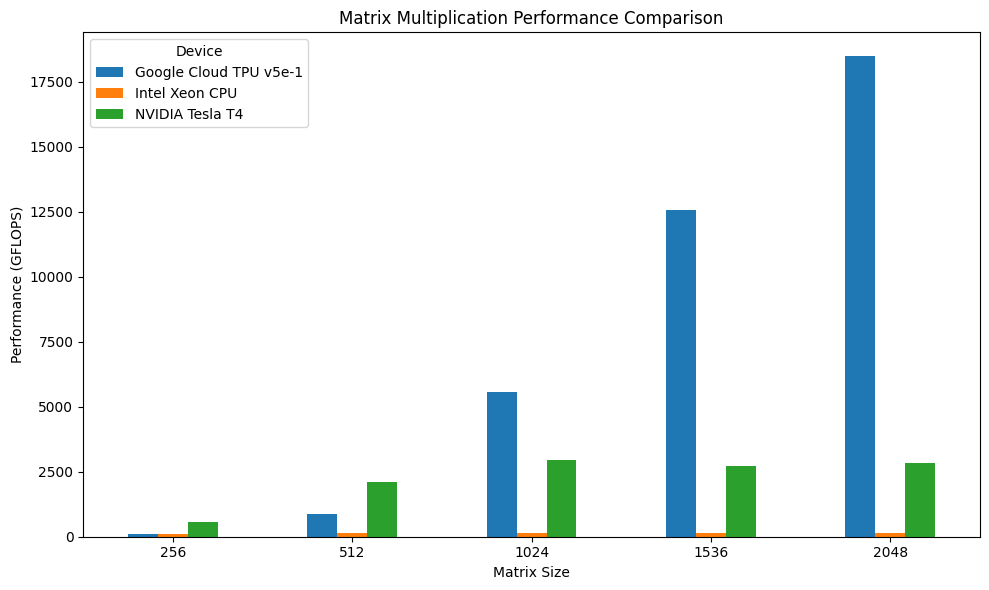

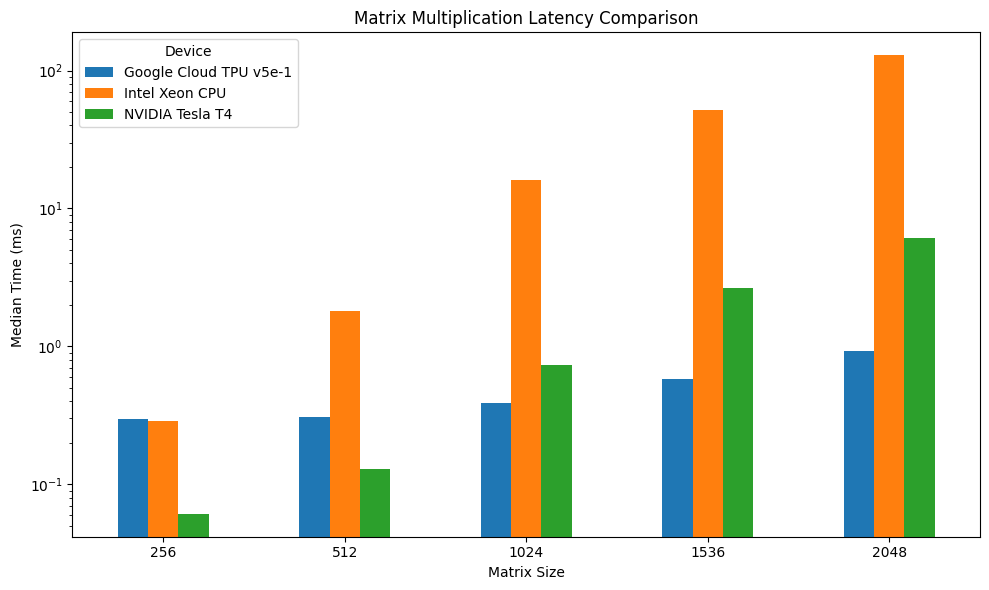

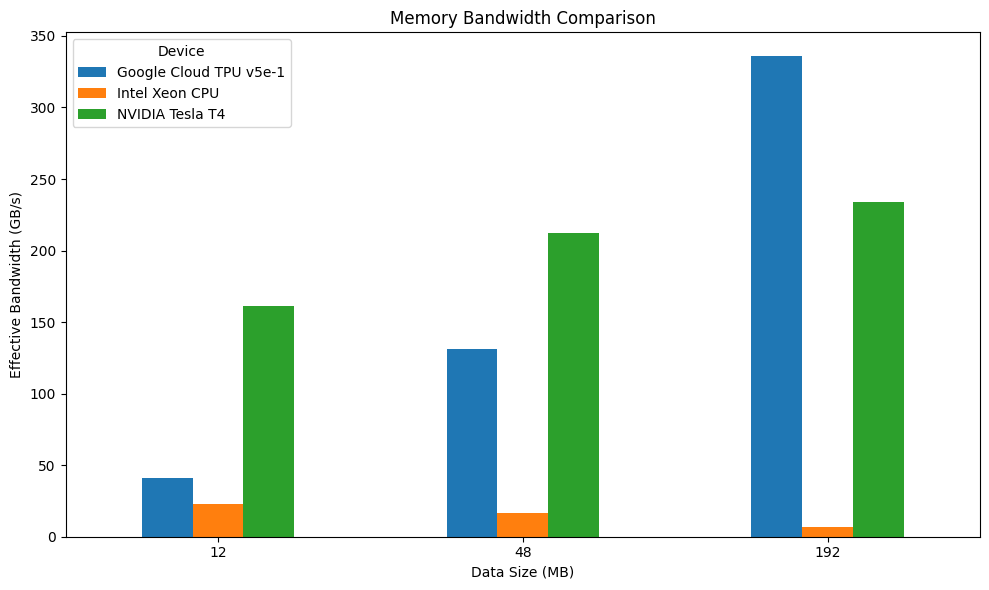


ALL THREE GRAPHS SAVED
matrix_performance_gflops.png ✓
matrix_latency_comparison.png ✓
memory_bandwidth_comparison.png ✓

Graph folder: /content/drive/MyDrive/AI_Inference_Precision_Comparison/Results/Graphs


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
raw = os.path.join(base, "Results", "Raw_CSV")
graphs = os.path.join(base, "Results", "Graphs")

os.makedirs(graphs, exist_ok=True)

# Load combined datasets
matrix = pd.read_csv(
    os.path.join(raw, "combined_matrix_benchmark.csv")
)

memory = pd.read_csv(
    os.path.join(raw, "combined_memory_bandwidth.csv")
)

# Graph 1: Matrix multiplication GFLOPS
pivot = matrix.pivot(
    index="Matrix_Size",
    columns="Device",
    values="GFLOPS"
).sort_index()

ax = pivot.plot(kind="bar", figsize=(10, 6))
ax.set_title("Matrix Multiplication Performance Comparison")
ax.set_xlabel("Matrix Size")
ax.set_ylabel("Performance (GFLOPS)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    os.path.join(graphs, "matrix_performance_gflops.png"),
    dpi=300
)
plt.show()
plt.close()

# Graph 2: Matrix multiplication latency
pivot = matrix.pivot(
    index="Matrix_Size",
    columns="Device",
    values="Median_Time_ms"
).sort_index()

ax = pivot.plot(kind="bar", figsize=(10, 6))
ax.set_title("Matrix Multiplication Latency Comparison")
ax.set_xlabel("Matrix Size")
ax.set_ylabel("Median Time (ms)")
ax.set_yscale("log")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    os.path.join(graphs, "matrix_latency_comparison.png"),
    dpi=300
)
plt.show()
plt.close()

# Graph 3: Memory bandwidth
pivot = memory.pivot(
    index="Data_Size_MB",
    columns="Device",
    values="Bandwidth_GBps"
).sort_index()

ax = pivot.plot(kind="bar", figsize=(10, 6))
ax.set_title("Memory Bandwidth Comparison")
ax.set_xlabel("Data Size (MB)")
ax.set_ylabel("Effective Bandwidth (GB/s)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    os.path.join(graphs, "memory_bandwidth_comparison.png"),
    dpi=300
)
plt.show()
plt.close()

print("\nALL THREE GRAPHS SAVED")
for filename in [
    "matrix_performance_gflops.png",
    "matrix_latency_comparison.png",
    "memory_bandwidth_comparison.png"
]:
    path = os.path.join(graphs, filename)
    print(filename, "✓" if os.path.exists(path) else "MISSING")

print("\nGraph folder:", graphs)

In [ ]:
import torch
import os

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
raw = os.path.join(base, "Results", "Raw_CSV")

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Drive folder exists:", os.path.exists(base))
print("CSV folder exists:", os.path.exists(raw))

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
Drive folder exists: True
CSV folder exists: True


In [ ]:
import torch
import time
import pandas as pd
import os

device = torch.device("cuda")

sizes_mb = [1, 4, 16, 64, 128]
results = []

for size_mb in sizes_mb:

    num_elements = size_mb * 1024 * 1024 // 4

    # Create source data in CPU RAM
    cpu_data = torch.randn(num_elements, dtype=torch.float32)

    # Warm-up
    for _ in range(3):
        _ = cpu_data.to(device)
    torch.cuda.synchronize()

    times = []

    # Measure CPU-to-GPU transfer
    for _ in range(10):
        torch.cuda.synchronize()
        start = time.perf_counter()

        gpu_data = cpu_data.to(device)

        torch.cuda.synchronize()
        end = time.perf_counter()

        times.append((end - start) * 1000)

    median_ms = sorted(times)[len(times) // 2]
    bandwidth = size_mb / (median_ms / 1000) / 1000

    results.append([
        "CPU to GPU",
        size_mb,
        median_ms,
        bandwidth
    ])

    print(
        f"{size_mb:>3} MB | "
        f"Median: {median_ms:.3f} ms | "
        f"Bandwidth: {bandwidth:.3f} GB/s"
    )

print("\nBenchmark complete.")

  1 MB | Median: 0.444 ms | Bandwidth: 2.253 GB/s
  4 MB | Median: 2.999 ms | Bandwidth: 1.334 GB/s
 16 MB | Median: 7.609 ms | Bandwidth: 2.103 GB/s
 64 MB | Median: 15.451 ms | Bandwidth: 4.142 GB/s
128 MB | Median: 31.204 ms | Bandwidth: 4.102 GB/s

Benchmark complete.


In [ ]:
import torch
import time
import pandas as pd
import os

device = torch.device("cuda")
sizes_mb = [1, 4, 16, 64, 128]

results_reverse = []

for size_mb in sizes_mb:

    num_elements = size_mb * 1024 * 1024 // 4

    # Create data directly on GPU
    gpu_data = torch.randn(num_elements, device=device)

    # Warm-up
    for _ in range(3):
        _ = gpu_data.cpu()
    torch.cuda.synchronize()

    times = []

    # Measure GPU-to-CPU transfer
    for _ in range(10):
        torch.cuda.synchronize()
        start = time.perf_counter()

        cpu_data = gpu_data.cpu()

        torch.cuda.synchronize()
        end = time.perf_counter()

        times.append((end - start) * 1000)

    median_ms = sorted(times)[len(times) // 2]
    bandwidth = size_mb / (median_ms / 1000) / 1000

    results_reverse.append([
        "GPU to CPU",
        size_mb,
        median_ms,
        bandwidth
    ])

    print(
        f"{size_mb:>3} MB | "
        f"Median: {median_ms:.3f} ms | "
        f"Bandwidth: {bandwidth:.3f} GB/s"
    )

print("\nGPU-to-CPU benchmark complete.")

  1 MB | Median: 0.356 ms | Bandwidth: 2.807 GB/s
  4 MB | Median: 0.991 ms | Bandwidth: 4.038 GB/s
 16 MB | Median: 3.528 ms | Bandwidth: 4.536 GB/s
 64 MB | Median: 45.009 ms | Bandwidth: 1.422 GB/s
128 MB | Median: 91.069 ms | Bandwidth: 1.406 GB/s

GPU-to-CPU benchmark complete.


In [ ]:
import pandas as pd
import os

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
raw = os.path.join(base, "Results", "Raw_CSV")
os.makedirs(raw, exist_ok=True)

sizes = [1, 4, 16, 64, 128]

h2d_times = [0.444, 2.999, 7.609, 15.451, 31.204]
d2h_times = [0.356, 0.991, 3.528, 45.009, 91.069]

records = []

for direction, times in [
    ("CPU to GPU", h2d_times),
    ("GPU to CPU", d2h_times)
]:
    for size, time_ms in zip(sizes, times):

        data_bytes = size * 1024 * 1024
        bandwidth = data_bytes / (time_ms / 1000) / 1e9

        records.append({
            "Device": "NVIDIA Tesla T4",
            "Direction": direction,
            "Data_Size_MiB": size,
            "Data_Size_Bytes": data_bytes,
            "Transfer_Time_ms": time_ms,
            "Effective_Bandwidth_GBps": bandwidth,
            "Timing_Statistic": "Upper-middle of 10 observations",
            "Data_Status": "Reconstructed from recorded console summary"
        })

df = pd.DataFrame(records)

path = os.path.join(raw, "host_device_transfer.csv")
df.to_csv(path, index=False)

print(df.to_string(index=False))
print("\nSaved:", path)
print("\nTotal records:", len(df))

         Device  Direction  Data_Size_MiB  Data_Size_Bytes  Transfer_Time_ms  Effective_Bandwidth_GBps                Timing_Statistic                                 Data_Status
NVIDIA Tesla T4 CPU to GPU              1          1048576             0.444                  2.361658 Upper-middle of 10 observations Reconstructed from recorded console summary
NVIDIA Tesla T4 CPU to GPU              4          4194304             2.999                  1.398568 Upper-middle of 10 observations Reconstructed from recorded console summary
NVIDIA Tesla T4 CPU to GPU             16         16777216             7.609                  2.204917 Upper-middle of 10 observations Reconstructed from recorded console summary
NVIDIA Tesla T4 CPU to GPU             64         67108864            15.451                  4.343335 Upper-middle of 10 observations Reconstructed from recorded console summary
NVIDIA Tesla T4 CPU to GPU            128        134217728            31.204                  4.301299 Up

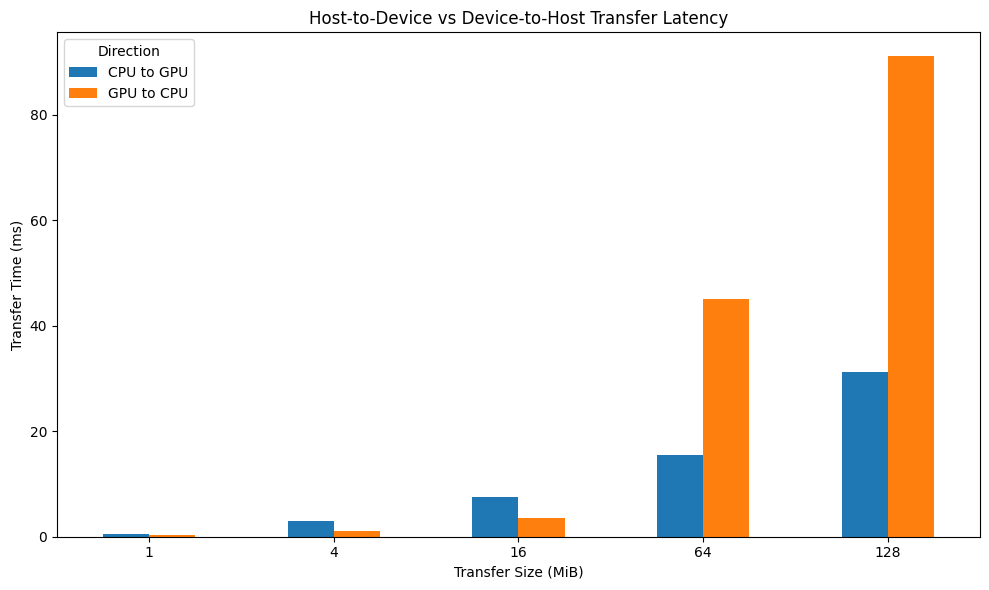

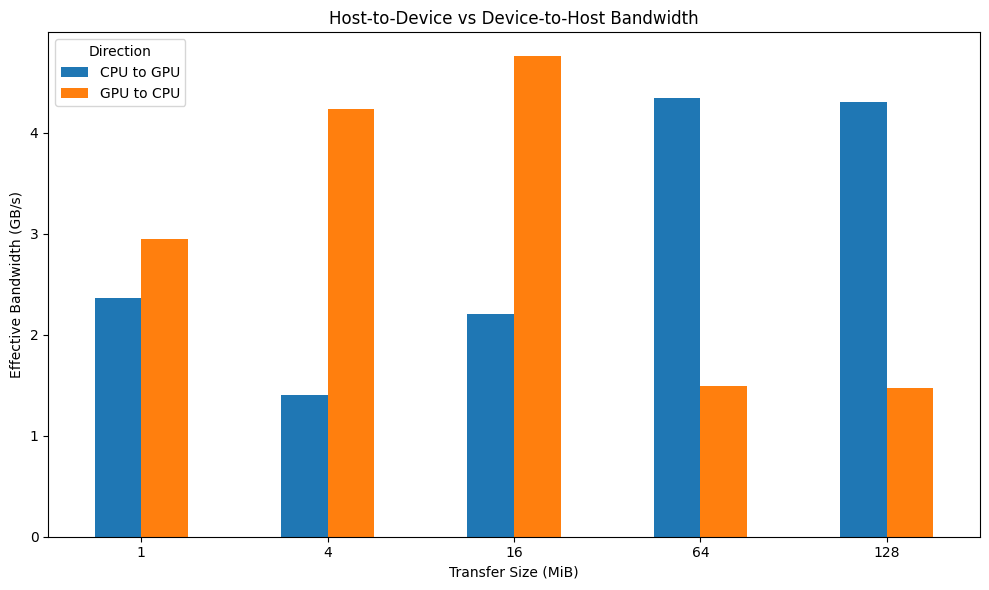

Transfer graphs saved:
True
True


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
raw = os.path.join(base, "Results", "Raw_CSV")
graphs = os.path.join(base, "Results", "Graphs")

df = pd.read_csv(os.path.join(raw, "host_device_transfer.csv"))

# Transfer latency comparison
pivot = df.pivot(
    index="Data_Size_MiB",
    columns="Direction",
    values="Transfer_Time_ms"
)

ax = pivot.plot(kind="bar", figsize=(10, 6))
ax.set_title("Host-to-Device vs Device-to-Host Transfer Latency")
ax.set_xlabel("Transfer Size (MiB)")
ax.set_ylabel("Transfer Time (ms)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    os.path.join(graphs, "host_device_transfer_latency.png"),
    dpi=300
)
plt.show()
plt.close()

# Effective bandwidth comparison
pivot = df.pivot(
    index="Data_Size_MiB",
    columns="Direction",
    values="Effective_Bandwidth_GBps"
)

ax = pivot.plot(kind="bar", figsize=(10, 6))
ax.set_title("Host-to-Device vs Device-to-Host Bandwidth")
ax.set_xlabel("Transfer Size (MiB)")
ax.set_ylabel("Effective Bandwidth (GB/s)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    os.path.join(graphs, "host_device_transfer_bandwidth.png"),
    dpi=300
)
plt.show()
plt.close()

print("Transfer graphs saved:")
print(os.path.exists(os.path.join(graphs, "host_device_transfer_latency.png")))
print(os.path.exists(os.path.join(graphs, "host_device_transfer_bandwidth.png")))

In [ ]:
import pandas as pd
import os

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
raw = os.path.join(base, "Results", "Raw_CSV")

matrix = pd.read_csv(
    os.path.join(raw, "combined_matrix_benchmark.csv")
)

memory = pd.read_csv(
    os.path.join(raw, "combined_memory_bandwidth.csv")
)

print("MATRIX MULTIPLICATION DATA")
print(matrix.to_string(index=False))

print("\nMEMORY BANDWIDTH DATA")
print(memory.to_string(index=False))

MATRIX MULTIPLICATION DATA
                Device  Matrix_Size  Median_Time_ms       GFLOPS                                         Data_Status
        Intel Xeon CPU          256           0.289   116.075981 Summary data; TPU and CPU/GPU timing methods differ
       NVIDIA Tesla T4          256           0.061   549.734704 Summary data; TPU and CPU/GPU timing methods differ
        Intel Xeon CPU          512           1.800   149.107946 Summary data; TPU and CPU/GPU timing methods differ
       NVIDIA Tesla T4          512           0.128  2098.890143 Summary data; TPU and CPU/GPU timing methods differ
        Intel Xeon CPU         1024          16.136   133.082530 Summary data; TPU and CPU/GPU timing methods differ
       NVIDIA Tesla T4         1024           0.730  2941.315210 Summary data; TPU and CPU/GPU timing methods differ
        Intel Xeon CPU         2048         129.117   133.056145 Summary data; TPU and CPU/GPU timing methods differ
       NVIDIA Tesla T4         2048  

In [ ]:
import pandas as pd
import os

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
raw = os.path.join(base, "Results", "Raw_CSV")

matrix = pd.read_csv(
    os.path.join(raw, "combined_matrix_benchmark.csv")
)

# Calculate estimated arithmetic intensity
matrix["Arithmetic_Intensity_FLOP_per_Byte"] = (
    matrix["Matrix_Size"] / 6
)

# Find maximum measured bandwidth for each device
memory = pd.read_csv(
    os.path.join(raw, "combined_memory_bandwidth.csv")
)

bandwidth_ceiling = (
    memory.groupby("Device")["Bandwidth_GBps"]
    .max()
    .reset_index()
    .rename(columns={"Bandwidth_GBps": "Measured_Bandwidth_Ceiling_GBps"})
)

# Combine the data
roofline_data = matrix.merge(
    bandwidth_ceiling,
    on="Device"
)

path = os.path.join(raw, "roofline_input_data.csv")
roofline_data.to_csv(path, index=False)

print("ROOFLINE INPUT DATA")
print(roofline_data.to_string(index=False))

print("\nSaved:", path)

ROOFLINE INPUT DATA
                Device  Matrix_Size  Median_Time_ms       GFLOPS                                         Data_Status  Arithmetic_Intensity_FLOP_per_Byte  Measured_Bandwidth_Ceiling_GBps
        Intel Xeon CPU          256           0.289   116.075981 Summary data; TPU and CPU/GPU timing methods differ                           42.666667                        22.648432
       NVIDIA Tesla T4          256           0.061   549.734704 Summary data; TPU and CPU/GPU timing methods differ                           42.666667                       233.660000
        Intel Xeon CPU          512           1.800   149.107946 Summary data; TPU and CPU/GPU timing methods differ                           85.333333                        22.648432
       NVIDIA Tesla T4          512           0.128  2098.890143 Summary data; TPU and CPU/GPU timing methods differ                           85.333333                       233.660000
        Intel Xeon CPU         1024          16.13

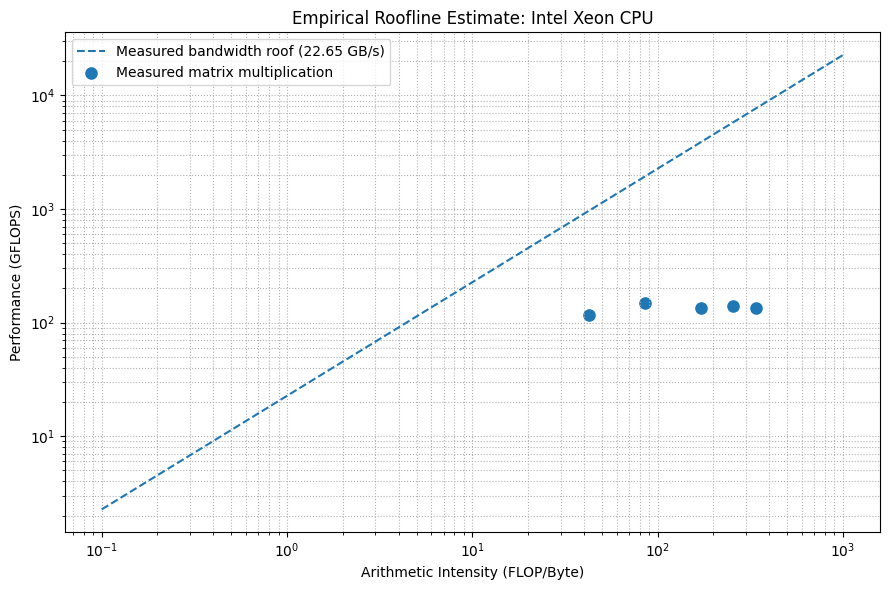

Saved: intel_xeon_cpu_roofline.png


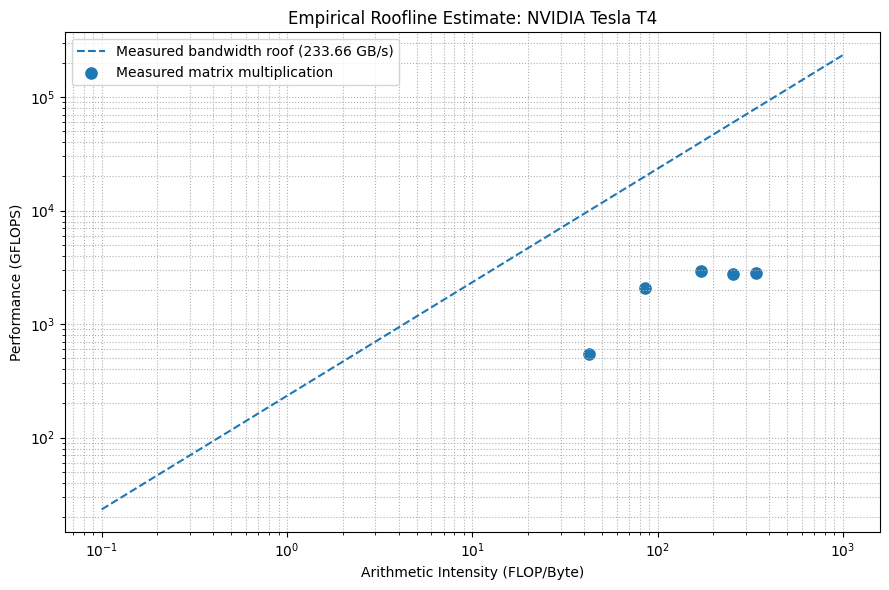

Saved: nvidia_tesla_t4_roofline.png


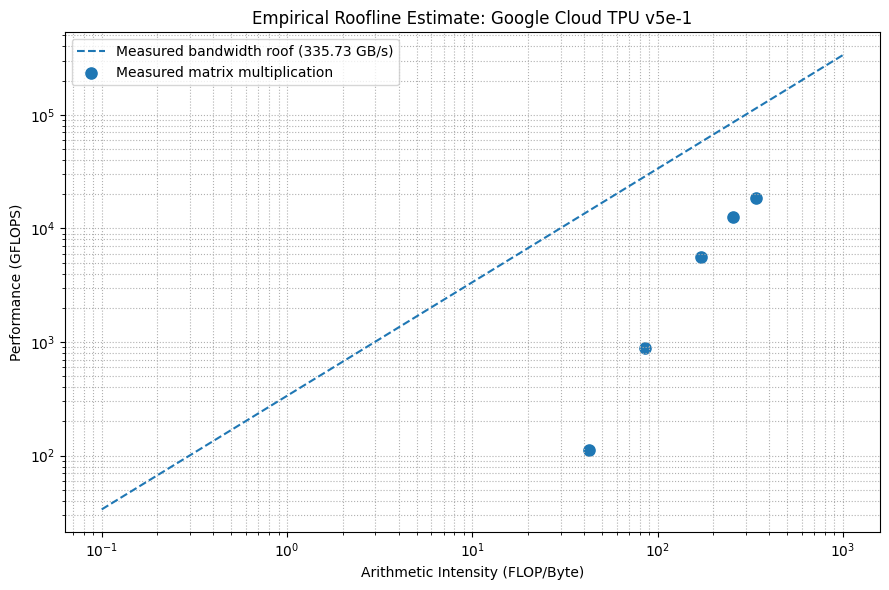

Saved: google_cloud_tpu_v5e_1_roofline.png

THREE ROOFLINE PLOTS GENERATED


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import numpy as np

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
raw = os.path.join(base, "Results", "Raw_CSV")
graphs = os.path.join(base, "Results", "Graphs")

os.makedirs(graphs, exist_ok=True)

df = pd.read_csv(
    os.path.join(raw, "roofline_input_data.csv")
)

devices = df["Device"].unique()

for device in devices:

    subset = df[df["Device"] == device]

    # Arithmetic intensity and measured performance
    ai = subset["Arithmetic_Intensity_FLOP_per_Byte"]
    performance = subset["GFLOPS"]

    # Measured bandwidth ceiling
    bandwidth = subset[
        "Measured_Bandwidth_Ceiling_GBps"
    ].iloc[0]

    # Range for the bandwidth roof
    x = np.logspace(-1, 3, 200)
    y = bandwidth * x

    plt.figure(figsize=(9, 6))

    # Bandwidth roof
    plt.loglog(
        x, y,
        linestyle="--",
        label=f"Measured bandwidth roof ({bandwidth:.2f} GB/s)"
    )

    # Measured matrix multiplication points
    plt.scatter(
        ai,
        performance,
        s=65,
        label="Measured matrix multiplication"
    )

    plt.title(f"Empirical Roofline Estimate: {device}")
    plt.xlabel("Arithmetic Intensity (FLOP/Byte)")
    plt.ylabel("Performance (GFLOPS)")

    plt.grid(True, which="both", linestyle=":")
    plt.legend()
    plt.tight_layout()

    filename = (
        device.lower()
        .replace(" ", "_")
        .replace("-", "_")
        + "_roofline.png"
    )

    plt.savefig(
        os.path.join(graphs, filename),
        dpi=300
    )

    plt.show()
    plt.close()

    print("Saved:", filename)

print("\nTHREE ROOFLINE PLOTS GENERATED")

In [ ]:
import os

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
graphs = os.path.join(base, "Results", "Graphs")

files = [
    "intel_xeon_cpu_roofline.png",
    "nvidia_tesla_t4_roofline.png",
    "google_cloud_tpu_v5e_1_roofline.png"
]

for filename in files:
    path = os.path.join(graphs, filename)

    if os.path.exists(path):
        print("FOUND:", filename,
              "| Size:", round(os.path.getsize(path) / 1024, 2), "KB")
    else:
        print("MISSING:", filename)

FOUND: intel_xeon_cpu_roofline.png | Size: 247.02 KB
FOUND: nvidia_tesla_t4_roofline.png | Size: 253.43 KB
FOUND: google_cloud_tpu_v5e_1_roofline.png | Size: 254.95 KB


In [ ]:
import torch
import torchvision
import os

from google.colab import drive
drive.mount('/content/drive')

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
raw = os.path.join(base, "Results", "Raw_CSV")
graphs = os.path.join(base, "Results", "Graphs")

os.makedirs(raw, exist_ok=True)
os.makedirs(graphs, exist_ok=True)

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("ResNet-50 experiment setup ready!")

ValueError: Mountpoint must not already contain files

In [ ]:
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

ValueError: Mountpoint must not already contain files

In [ ]:
from google.colab import drive
import os

mount_path = "/content/gdrive"

os.makedirs(mount_path, exist_ok=True)

print("Mount folder contents:", os.listdir(mount_path))

drive.mount(mount_path)

Mount folder contents: []
Mounted at /content/gdrive


In [ ]:
import os
import torch
import torchvision

base = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison"
raw = os.path.join(base, "Results", "Raw_CSV")
graphs = os.path.join(base, "Results", "Graphs")

os.makedirs(raw, exist_ok=True)
os.makedirs(graphs, exist_ok=True)

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nProject folder exists:", os.path.exists(base))
print("Raw CSV folder:", os.path.exists(raw))
print("Graphs folder:", os.path.exists(graphs))
print("\nResNet-50 setup ready!")

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
CUDA available: True
GPU: Tesla T4

Project folder exists: True
Raw CSV folder: True
Graphs folder: True

ResNet-50 setup ready!


In [ ]:
import torch
from torchvision.models import resnet50, ResNet50_Weights

# Load pretrained ResNet-50
weights = ResNet50_Weights.DEFAULT
model = resnet50(weights=weights)

# Evaluation mode
model.eval()
model = model.to("cuda")

print("Model: ResNet-50")
print("Weights: ImageNet pretrained")
print("Device:", next(model.parameters()).device)
print("Total parameters:", sum(p.numel() for p in model.parameters()))
print("Model loaded successfully!")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 191MB/s]


Model: ResNet-50
Weights: ImageNet pretrained
Device: cuda:0
Total parameters: 25557032
Model loaded successfully!


In [ ]:
import torch

batch_sizes = [1, 2, 4, 8, 16, 32]

# Create fixed synthetic input tensors
inputs = {}

for batch in batch_sizes:
    inputs[batch] = torch.randn(
        batch, 3, 224, 224,
        device="cuda"
    )

print("Input preparation complete!")

for batch in batch_sizes:
    print(f"Batch {batch}: {inputs[batch].shape}")

print("All inputs are on:", inputs[1].device)

Input preparation complete!
Batch 1: torch.Size([1, 3, 224, 224])
Batch 2: torch.Size([2, 3, 224, 224])
Batch 4: torch.Size([4, 3, 224, 224])
Batch 8: torch.Size([8, 3, 224, 224])
Batch 16: torch.Size([16, 3, 224, 224])
Batch 32: torch.Size([32, 3, 224, 224])
All inputs are on: cuda:0


In [ ]:
import time
import numpy as np
import pandas as pd
import torch
import os

model.eval()
results = []

for batch in batch_sizes:

    x = inputs[batch]

    # Warm-up
    with torch.inference_mode():
        for _ in range(3):
            _ = model(x)

    torch.cuda.synchronize()

    timings = []

    # 10 measured repetitions
    with torch.inference_mode():
        for _ in range(10):
            start = torch.cuda.Event(enable_timing=True)
            end = torch.cuda.Event(enable_timing=True)

            start.record()
            _ = model(x)
            end.record()

            torch.cuda.synchronize()
            timings.append(start.elapsed_time(end))

    median_ms = np.median(timings)
    mean_ms = np.mean(timings)
    std_ms = np.std(timings)

    throughput = batch / (median_ms / 1000)

    p95 = np.percentile(timings, 95) if batch == 1 else None
    p99 = np.percentile(timings, 99) if batch == 1 else None

    results.append({
        "Device": "NVIDIA Tesla T4",
        "Model": "ResNet-50",
        "Batch_Size": batch,
        "Median_Latency_ms": median_ms,
        "Mean_Latency_ms": mean_ms,
        "Std_Dev_ms": std_ms,
        "Throughput_Images_Per_Second": throughput,
        "P95_Latency_ms": p95,
        "P99_Latency_ms": p99
    })

df_gpu = pd.DataFrame(results)

display(df_gpu)

# Save results
save_path = os.path.join(raw, "resnet50_gpu_inference.csv")
df_gpu.to_csv(save_path, index=False)

print("\nGPU inference results saved:", save_path)


,Device,Model,Batch_Size,Median_Latency_ms,Mean_Latency_ms,Std_Dev_ms,Throughput_Images_Per_Second,P95_Latency_ms,P99_Latency_ms
0,NVIDIA Tesla T4,ResNet-50,1,17.615264,19.931933,6.890442,56.768946,29.906858,31.10662
1,NVIDIA Tesla T4,ResNet-50,2,18.827872,19.954640,3.953548,106.225492,NaN,NaN
2,NVIDIA Tesla T4,ResNet-50,4,28.092064,25.949350,7.441983,142.388968,NaN,NaN
3,NVIDIA Tesla T4,ResNet-50,8,27.884384,28.776448,2.147257,286.898931,NaN,NaN
4,NVIDIA Tesla T4,ResNet-50,16,48.689104,48.731482,0.515628,328.615617,NaN,NaN
5,NVIDIA Tesla T4,ResNet-50,32,94.543934,94.482994,0.336372,338.466982,NaN,NaN



GPU inference results saved: /content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/resnet50_gpu_inference.csv


In [ ]:
import copy
import torch

# Keep original GPU model unchanged
model_cpu = copy.deepcopy(model).to("cpu")
model_cpu.eval()

# Prepare identical inputs on CPU
inputs_cpu = {
    batch: inputs[batch].cpu()
    for batch in batch_sizes
}

# Use 2 CPU threads
torch.set_num_threads(2)

print("CPU model device:", next(model_cpu.parameters()).device)
print("CPU threads:", torch.get_num_threads())

for batch in batch_sizes:
    print(f"Batch {batch}:", inputs_cpu[batch].shape)

print("CPU inference setup ready!")

CPU model device: cpu
CPU threads: 2
Batch 1: torch.Size([1, 3, 224, 224])
Batch 2: torch.Size([2, 3, 224, 224])
Batch 4: torch.Size([4, 3, 224, 224])
Batch 8: torch.Size([8, 3, 224, 224])
Batch 16: torch.Size([16, 3, 224, 224])
Batch 32: torch.Size([32, 3, 224, 224])
CPU inference setup ready!


In [ ]:
import time
import numpy as np
import pandas as pd
import os
import torch

model_cpu.eval()
cpu_results = []

for batch in batch_sizes:

    x = inputs_cpu[batch]

    # Warm-up
    with torch.inference_mode():
        for _ in range(3):
            _ = model_cpu(x)

    timings = []

    # 10 measured repetitions
    with torch.inference_mode():
        for _ in range(10):
            start = time.perf_counter()
            _ = model_cpu(x)
            end = time.perf_counter()

            timings.append((end - start) * 1000)

    median_ms = np.median(timings)
    mean_ms = np.mean(timings)
    std_ms = np.std(timings)

    throughput = batch / (median_ms / 1000)

    p95 = np.percentile(timings, 95) if batch == 1 else None
    p99 = np.percentile(timings, 99) if batch == 1 else None

    cpu_results.append({
        "Device": "Intel Xeon CPU",
        "Model": "ResNet-50",
        "Batch_Size": batch,
        "Median_Latency_ms": median_ms,
        "Mean_Latency_ms": mean_ms,
        "Std_Dev_ms": std_ms,
        "Throughput_Images_Per_Second": throughput,
        "P95_Latency_ms": p95,
        "P99_Latency_ms": p99
    })

df_cpu = pd.DataFrame(cpu_results)

display(df_cpu)

# Save results
save_path = os.path.join(raw, "resnet50_cpu_inference.csv")
df_cpu.to_csv(save_path, index=False)

print("\nCPU inference results saved:", save_path)

,Device,Model,Batch_Size,Median_Latency_ms,Mean_Latency_ms,Std_Dev_ms,Throughput_Images_Per_Second,P95_Latency_ms,P99_Latency_ms
0,Intel Xeon CPU,ResNet-50,1,475.114414,461.359500,192.156902,2.104756,746.765041,833.943139
1,Intel Xeon CPU,ResNet-50,2,231.415086,238.127424,15.914779,8.642479,NaN,NaN
2,Intel Xeon CPU,ResNet-50,4,509.439978,718.962978,378.266087,7.851759,NaN,NaN
3,Intel Xeon CPU,ResNet-50,8,879.117563,1108.224512,405.372893,9.100034,NaN,NaN
4,Intel Xeon CPU,ResNet-50,16,2272.751079,2571.195571,558.704043,7.039926,NaN,NaN
5,Intel Xeon CPU,ResNet-50,32,4903.149565,4961.666397,589.637644,6.526417,NaN,NaN



CPU inference results saved: /content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/resnet50_cpu_inference.csv


In [ ]:
import pandas as pd
import os

gpu_file = os.path.join(raw, "resnet50_gpu_inference.csv")
cpu_file = os.path.join(raw, "resnet50_cpu_inference.csv")

gpu_df = pd.read_csv(gpu_file)
cpu_df = pd.read_csv(cpu_file)

combined = pd.concat(
    [gpu_df, cpu_df],
    ignore_index=True
)

combined = combined.sort_values(
    ["Batch_Size", "Device"]
)

display(combined)

combined_file = os.path.join(
    raw, "combined_resnet50_inference.csv"
)

combined.to_csv(combined_file, index=False)

print("\nCombined results saved:", combined_file)

,Device,Model,Batch_Size,Median_Latency_ms,Mean_Latency_ms,Std_Dev_ms,Throughput_Images_Per_Second,P95_Latency_ms,P99_Latency_ms
6,Intel Xeon CPU,ResNet-50,1,475.114414,461.359500,192.156902,2.104756,746.765041,833.943139
0,NVIDIA Tesla T4,ResNet-50,1,17.615264,19.931933,6.890442,56.768946,29.906858,31.106620
7,Intel Xeon CPU,ResNet-50,2,231.415086,238.127424,15.914779,8.642479,NaN,NaN
1,NVIDIA Tesla T4,ResNet-50,2,18.827872,19.954640,3.953548,106.225492,NaN,NaN
8,Intel Xeon CPU,ResNet-50,4,509.439978,718.962978,378.266087,7.851759,NaN,NaN
2,NVIDIA Tesla T4,ResNet-50,4,28.092064,25.949350,7.441983,142.388968,NaN,NaN
9,Intel Xeon CPU,ResNet-50,8,879.117563,1108.224512,405.372893,9.100034,NaN,NaN
3,NVIDIA Tesla T4,ResNet-50,8,27.884384,28.776448,2.147257,286.898931,NaN,NaN
10,Intel Xeon CPU,ResNet-50,16,2272.751079,2571.195571,558.704043,7.039926,NaN,NaN
4,NVIDIA Tesla T4,ResNet-50,16,48.689104,48.731482,0.515628,328.615617,NaN,NaN



Combined results saved: /content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/combined_resnet50_inference.csv


In [ ]:
import time
import numpy as np
import pandas as pd
import torch
import os

gpu_wall_results = []

model.eval()

for batch in batch_sizes:

    x = inputs[batch]

    # Warm-up
    with torch.inference_mode():
        for _ in range(3):
            _ = model(x)

    torch.cuda.synchronize()
    timings = []

    with torch.inference_mode():
        for _ in range(10):
            torch.cuda.synchronize()
            start = time.perf_counter()

            _ = model(x)

            torch.cuda.synchronize()
            end = time.perf_counter()

            timings.append((end - start) * 1000)

    median_ms = np.median(timings)

    gpu_wall_results.append({
        "Device": "NVIDIA Tesla T4",
        "Model": "ResNet-50",
        "Batch_Size": batch,
        "Median_Latency_ms": median_ms,
        "Throughput_Images_Per_Second": batch / (median_ms / 1000)
    })

df_gpu_wall = pd.DataFrame(gpu_wall_results)

display(df_gpu_wall)

save_path = os.path.join(raw, "resnet50_gpu_wall_timing.csv")
df_gpu_wall.to_csv(save_path, index=False)

print("Saved:", save_path)

,Device,Model,Batch_Size,Median_Latency_ms,Throughput_Images_Per_Second
0,NVIDIA Tesla T4,ResNet-50,1,12.202402,81.951082
1,NVIDIA Tesla T4,ResNet-50,2,10.290968,194.345177
2,NVIDIA Tesla T4,ResNet-50,4,17.449967,229.226795
3,NVIDIA Tesla T4,ResNet-50,8,28.591678,279.801691
4,NVIDIA Tesla T4,ResNet-50,16,49.769938,321.479206
5,NVIDIA Tesla T4,ResNet-50,32,96.165043,332.761251


Saved: /content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/resnet50_gpu_wall_timing.csv


In [ ]:
import pandas as pd
import os

cpu_file = os.path.join(raw, "resnet50_cpu_inference.csv")
gpu_file = os.path.join(raw, "resnet50_gpu_wall_timing.csv")

cpu = pd.read_csv(cpu_file)
gpu = pd.read_csv(gpu_file)

comparison = pd.merge(
    cpu[["Batch_Size", "Median_Latency_ms"]],
    gpu[["Batch_Size", "Median_Latency_ms"]],
    on="Batch_Size",
    suffixes=("_CPU", "_GPU")
)

comparison["CPU_Throughput"] = (
    comparison["Batch_Size"] /
    (comparison["Median_Latency_ms_CPU"] / 1000)
)

comparison["GPU_Throughput"] = (
    comparison["Batch_Size"] /
    (comparison["Median_Latency_ms_GPU"] / 1000)
)

comparison["GPU_Speedup"] = (
    comparison["Median_Latency_ms_CPU"] /
    comparison["Median_Latency_ms_GPU"]
)

display(comparison)

save_path = os.path.join(
    raw, "resnet50_cpu_gpu_fair_comparison.csv"
)

comparison.to_csv(save_path, index=False)

print("Comparison saved:", save_path)

,Batch_Size,Median_Latency_ms_CPU,Median_Latency_ms_GPU,CPU_Throughput,GPU_Throughput,GPU_Speedup
0,1,475.114414,12.202402,2.104756,81.951082,38.936140
1,2,231.415086,10.290968,8.642479,194.345177,22.487203
2,4,509.439978,17.449967,7.851759,229.226795,29.194323
3,8,879.117563,28.591678,9.100034,279.801691,30.747323
4,16,2272.751079,49.769938,7.039926,321.479206,45.665138
5,32,4903.149565,96.165043,6.526417,332.761251,50.986818


Comparison saved: /content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/resnet50_cpu_gpu_fair_comparison.csv


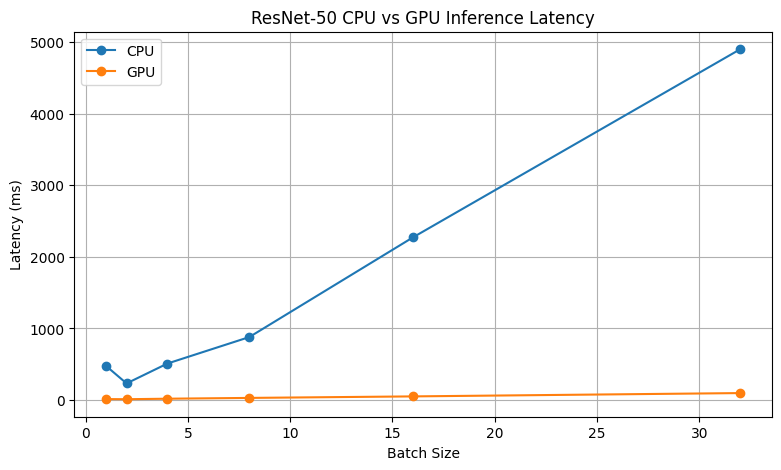

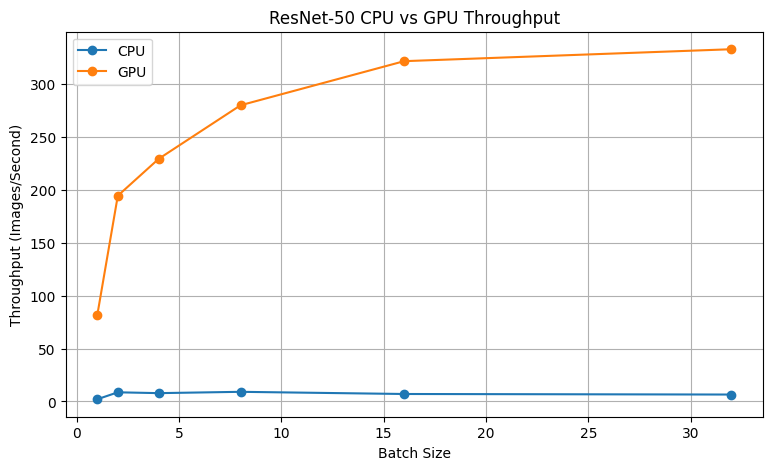

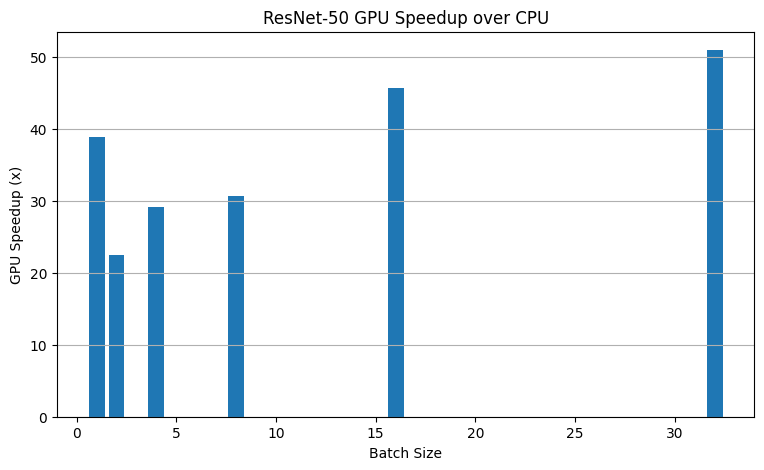

All three ResNet-50 graphs saved successfully!


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

file_path = os.path.join(
    raw, "resnet50_cpu_gpu_fair_comparison.csv"
)

df = pd.read_csv(file_path)

# 1. Latency comparison
plt.figure(figsize=(9, 5))
plt.plot(df["Batch_Size"], df["Median_Latency_ms_CPU"],
         marker="o", label="CPU")
plt.plot(df["Batch_Size"], df["Median_Latency_ms_GPU"],
         marker="o", label="GPU")

plt.xlabel("Batch Size")
plt.ylabel("Latency (ms)")
plt.title("ResNet-50 CPU vs GPU Inference Latency")
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(graphs, "resnet50_latency_comparison.png"),
            dpi=300, bbox_inches="tight")
plt.show()

# 2. Throughput comparison
plt.figure(figsize=(9, 5))
plt.plot(df["Batch_Size"], df["CPU_Throughput"],
         marker="o", label="CPU")
plt.plot(df["Batch_Size"], df["GPU_Throughput"],
         marker="o", label="GPU")

plt.xlabel("Batch Size")
plt.ylabel("Throughput (Images/Second)")
plt.title("ResNet-50 CPU vs GPU Throughput")
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(graphs, "resnet50_throughput_comparison.png"),
            dpi=300, bbox_inches="tight")
plt.show()

# 3. GPU speedup
plt.figure(figsize=(9, 5))
plt.bar(df["Batch_Size"], df["GPU_Speedup"])

plt.xlabel("Batch Size")
plt.ylabel("GPU Speedup (x)")
plt.title("ResNet-50 GPU Speedup over CPU")
plt.grid(axis="y")
plt.savefig(os.path.join(graphs, "resnet50_gpu_speedup.png"),
            dpi=300, bbox_inches="tight")
plt.show()

print("All three ResNet-50 graphs saved successfully!")

In [ ]:
import os

graph_files = [
    "resnet50_latency_comparison.png",
    "resnet50_throughput_comparison.png",
    "resnet50_gpu_speedup.png"
]

for filename in graph_files:
    path = os.path.join(graphs, filename)
    print(
        filename,
        "✓ FOUND" if os.path.exists(path) else "✗ MISSING"
    )

resnet50_latency_comparison.png ✓ FOUND
resnet50_throughput_comparison.png ✓ FOUND
resnet50_gpu_speedup.png ✓ FOUND


In [ ]:
!pip install -q transformers

In [ ]:
import transformers

print("Transformers version:", transformers.__version__)
print("Installation successful!")

Transformers version: 5.22.0
Installation successful!


In [ ]:
import torch
from transformers import AutoTokenizer, AutoModel

model_name = "distilbert/distilbert-base-uncased"

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Load pretrained model
transformer_model = AutoModel.from_pretrained(model_name)

# Evaluation mode
transformer_model.eval()
transformer_model = transformer_model.to("cuda")

print("Model:", model_name)
print("Device:", next(transformer_model.parameters()).device)
print(
    "Total parameters:",
    sum(p.numel() for p in transformer_model.parameters())
)

print("DistilBERT loaded successfully!")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model: distilbert/distilbert-base-uncased
Device: cuda:0
Total parameters: 66362880
DistilBERT loaded successfully!


In [ ]:
import torch

sequence_length = 128
batch_sizes_transformer = [1, 2, 4, 8]

# Create reproducible synthetic token IDs
torch.manual_seed(42)

transformer_inputs = {}

for batch_size in batch_sizes_transformer:

    input_ids = torch.randint(
        low=0,
        high=tokenizer.vocab_size,
        size=(batch_size, sequence_length)
    )

    attention_mask = torch.ones(
        (batch_size, sequence_length),
        dtype=torch.long
    )

    transformer_inputs[batch_size] = {
        "input_ids": input_ids.to("cuda"),
        "attention_mask": attention_mask.to("cuda")
    }

    print(
        f"Batch {batch_size}:",
        transformer_inputs[batch_size]["input_ids"].shape
    )

print("Transformer benchmark inputs prepared!")

Batch 1: torch.Size([1, 128])
Batch 2: torch.Size([2, 128])
Batch 4: torch.Size([4, 128])
Batch 8: torch.Size([8, 128])
Transformer benchmark inputs prepared!


In [ ]:
import time
import numpy as np
import pandas as pd
import torch

gpu_results = []

transformer_model.eval()

for batch_size in batch_sizes_transformer:

    batch = transformer_inputs[batch_size]

    # Warm-up
    with torch.inference_mode():
        for _ in range(3):
            transformer_model(**batch)

    torch.cuda.synchronize()

    timings = []

    # 10 measured runs
    with torch.inference_mode():
        for _ in range(10):
            torch.cuda.synchronize()
            start = time.perf_counter()

            transformer_model(**batch)

            torch.cuda.synchronize()
            end = time.perf_counter()

            timings.append((end - start) * 1000)

    median_ms = np.median(timings)
    mean_ms = np.mean(timings)
    std_ms = np.std(timings)
    throughput = batch_size / (median_ms / 1000)

    gpu_results.append({
        "Device": "NVIDIA Tesla T4",
        "Model": "DistilBERT",
        "Batch_Size": batch_size,
        "Sequence_Length": sequence_length,
        "Median_Latency_ms": median_ms,
        "Mean_Latency_ms": mean_ms,
        "Std_Dev_ms": std_ms,
        "Throughput_Sequences_Per_Second": throughput
    })

    print(
        f"Batch {batch_size}: "
        f"Median = {median_ms:.3f} ms | "
        f"Throughput = {throughput:.2f} sequences/sec"
    )

df_transformer_gpu = pd.DataFrame(gpu_results)

display(df_transformer_gpu)

Batch 1: Median = 18.488 ms | Throughput = 54.09 sequences/sec
Batch 2: Median = 17.960 ms | Throughput = 111.36 sequences/sec
Batch 4: Median = 19.964 ms | Throughput = 200.36 sequences/sec
Batch 8: Median = 30.281 ms | Throughput = 264.19 sequences/sec


,Device,Model,Batch_Size,Sequence_Length,Median_Latency_ms,Mean_Latency_ms,Std_Dev_ms,Throughput_Sequences_Per_Second
0,NVIDIA Tesla T4,DistilBERT,1,128,18.488314,20.674277,5.010730,54.088222
1,NVIDIA Tesla T4,DistilBERT,2,128,17.959782,19.624964,3.279551,111.359923
2,NVIDIA Tesla T4,DistilBERT,4,128,19.964031,20.472141,7.583689,200.360333
3,NVIDIA Tesla T4,DistilBERT,8,128,30.281167,31.167139,1.745292,264.190611


In [ ]:
import os

gpu_csv_path = os.path.join(
    raw,
    "distilbert_gpu_inference.csv"
)

df_transformer_gpu.to_csv(gpu_csv_path, index=False)

print("GPU results saved successfully!")
print(gpu_csv_path)

GPU results saved successfully!
/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/distilbert_gpu_inference.csv


In [ ]:
import copy
import torch

# Use 2 CPU threads
torch.set_num_threads(2)

# Copy the same pretrained model to CPU
transformer_model_cpu = copy.deepcopy(transformer_model)
transformer_model_cpu = transformer_model_cpu.to("cpu")
transformer_model_cpu.eval()

# Copy identical input IDs and attention masks to CPU
transformer_inputs_cpu = {}

for batch_size in batch_sizes_transformer:

    transformer_inputs_cpu[batch_size] = {
        "input_ids": transformer_inputs[batch_size]["input_ids"].cpu(),
        "attention_mask": transformer_inputs[batch_size]["attention_mask"].cpu()
    }

print("CPU model device:", next(transformer_model_cpu.parameters()).device)
print("CPU threads:", torch.get_num_threads())

for batch_size in batch_sizes_transformer:
    print(
        f"Batch {batch_size}:",
        transformer_inputs_cpu[batch_size]["input_ids"].shape
    )

print("DistilBERT CPU setup successful!")

CPU model device: cpu
CPU threads: 2
Batch 1: torch.Size([1, 128])
Batch 2: torch.Size([2, 128])
Batch 4: torch.Size([4, 128])
Batch 8: torch.Size([8, 128])
DistilBERT CPU setup successful!


In [ ]:
import time
import numpy as np
import pandas as pd
import torch

cpu_results = []

transformer_model_cpu.eval()

for batch_size in batch_sizes_transformer:

    batch = transformer_inputs_cpu[batch_size]

    # Warm-up
    with torch.inference_mode():
        transformer_model_cpu(**batch)

    timings = []

    # 3 measured runs
    with torch.inference_mode():
        for _ in range(3):

            start = time.perf_counter()

            transformer_model_cpu(**batch)

            end = time.perf_counter()

            timings.append((end - start) * 1000)

    median_ms = np.median(timings)
    mean_ms = np.mean(timings)
    std_ms = np.std(timings)

    throughput = batch_size / (median_ms / 1000)

    cpu_results.append({
        "Device": "Intel Xeon CPU",
        "Model": "DistilBERT",
        "Batch_Size": batch_size,
        "Sequence_Length": sequence_length,
        "Median_Latency_ms": median_ms,
        "Mean_Latency_ms": mean_ms,
        "Std_Dev_ms": std_ms,
        "Throughput_Sequences_Per_Second": throughput
    })

    print(
        f"Batch {batch_size}: "
        f"Median = {median_ms:.3f} ms | "
        f"Throughput = {throughput:.2f} sequences/sec"
    )

df_transformer_cpu = pd.DataFrame(cpu_results)

display(df_transformer_cpu)

Batch 1: Median = 312.446 ms | Throughput = 3.20 sequences/sec
Batch 2: Median = 415.938 ms | Throughput = 4.81 sequences/sec
Batch 4: Median = 881.128 ms | Throughput = 4.54 sequences/sec
Batch 8: Median = 2116.527 ms | Throughput = 3.78 sequences/sec


,Device,Model,Batch_Size,Sequence_Length,Median_Latency_ms,Mean_Latency_ms,Std_Dev_ms,Throughput_Sequences_Per_Second
0,Intel Xeon CPU,DistilBERT,1,128,312.445918,330.515750,80.057108,3.200554
1,Intel Xeon CPU,DistilBERT,2,128,415.938363,455.413623,64.974725,4.808405
2,Intel Xeon CPU,DistilBERT,4,128,881.128045,856.738379,121.088265,4.539635
3,Intel Xeon CPU,DistilBERT,8,128,2116.526875,2197.408012,565.908002,3.779777


In [ ]:
cpu_csv_path = os.path.join(
    raw,
    "distilbert_cpu_inference.csv"
)

df_transformer_cpu.to_csv(cpu_csv_path, index=False)

print("CPU results saved successfully!")
print(cpu_csv_path)

CPU results saved successfully!
/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/distilbert_cpu_inference.csv


In [ ]:
# Combine both device results
df_transformer_combined = pd.concat(
    [df_transformer_cpu, df_transformer_gpu],
    ignore_index=True
)

# Calculate GPU speedup for each batch size
cpu_latency = df_transformer_cpu.set_index("Batch_Size")[
    "Median_Latency_ms"
]

gpu_latency = df_transformer_gpu.set_index("Batch_Size")[
    "Median_Latency_ms"
]

speedup = cpu_latency / gpu_latency

df_transformer_combined["GPU_Speedup"] = (
    df_transformer_combined["Batch_Size"].map(speedup)
)

# Save combined results
combined_path = os.path.join(
    raw,
    "combined_distilbert_inference.csv"
)

df_transformer_combined.to_csv(combined_path, index=False)

display(df_transformer_combined)

print("\nCombined results saved:")
print(combined_path)

,Device,Model,Batch_Size,Sequence_Length,Median_Latency_ms,Mean_Latency_ms,Std_Dev_ms,Throughput_Sequences_Per_Second,GPU_Speedup
0,Intel Xeon CPU,DistilBERT,1,128,312.445918,330.515750,80.057108,3.200554,16.899644
1,Intel Xeon CPU,DistilBERT,2,128,415.938363,455.413623,64.974725,4.808405,23.159432
2,Intel Xeon CPU,DistilBERT,4,128,881.128045,856.738379,121.088265,4.539635,44.135777
3,Intel Xeon CPU,DistilBERT,8,128,2116.526875,2197.408012,565.908002,3.779777,69.895816
4,NVIDIA Tesla T4,DistilBERT,1,128,18.488314,20.674277,5.010730,54.088222,16.899644
5,NVIDIA Tesla T4,DistilBERT,2,128,17.959782,19.624964,3.279551,111.359923,23.159432
6,NVIDIA Tesla T4,DistilBERT,4,128,19.964031,20.472141,7.583689,200.360333,44.135777
7,NVIDIA Tesla T4,DistilBERT,8,128,30.281167,31.167139,1.745292,264.190611,69.895816



Combined results saved:
/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/combined_distilbert_inference.csv


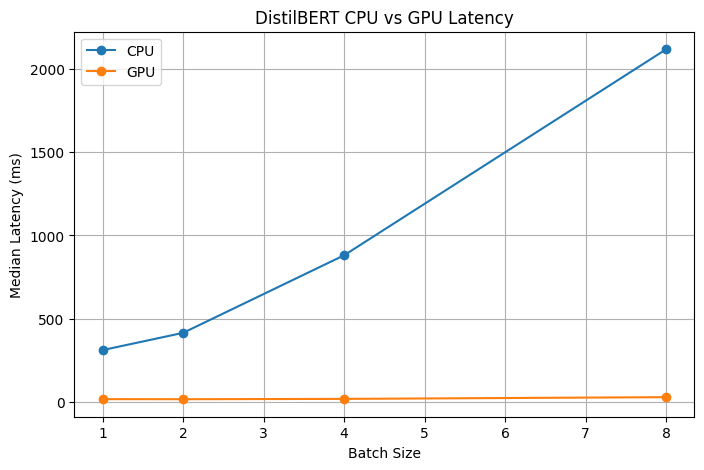

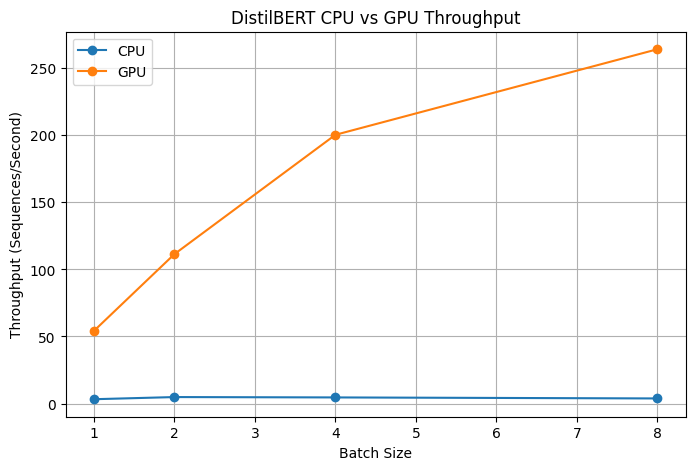

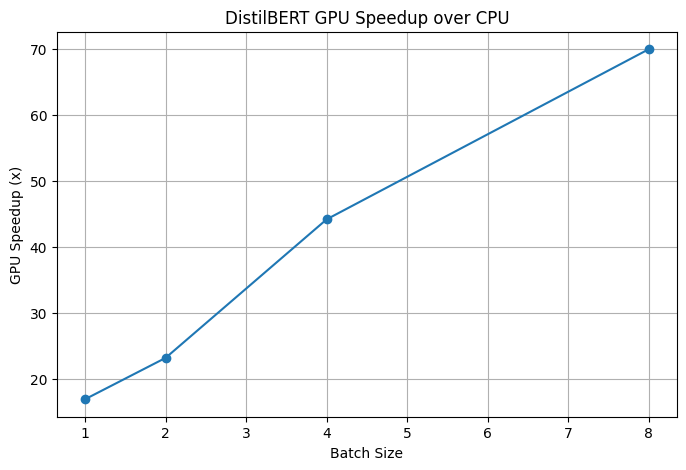

All DistilBERT graphs saved successfully!


In [ ]:
import matplotlib.pyplot as plt
import os

# Sort results by batch size
comparison = df_transformer_combined.sort_values("Batch_Size")

cpu_data = comparison[
    comparison["Device"] == "Intel Xeon CPU"
]

gpu_data = comparison[
    comparison["Device"] == "NVIDIA Tesla T4"
]

# Graph 1: Latency
plt.figure(figsize=(8, 5))

plt.plot(
    cpu_data["Batch_Size"],
    cpu_data["Median_Latency_ms"],
    marker="o",
    label="CPU"
)

plt.plot(
    gpu_data["Batch_Size"],
    gpu_data["Median_Latency_ms"],
    marker="o",
    label="GPU"
)

plt.xlabel("Batch Size")
plt.ylabel("Median Latency (ms)")
plt.title("DistilBERT CPU vs GPU Latency")
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(graphs, "distilbert_latency_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Graph 2: Throughput
plt.figure(figsize=(8, 5))

plt.plot(
    cpu_data["Batch_Size"],
    cpu_data["Throughput_Sequences_Per_Second"],
    marker="o",
    label="CPU"
)

plt.plot(
    gpu_data["Batch_Size"],
    gpu_data["Throughput_Sequences_Per_Second"],
    marker="o",
    label="GPU"
)

plt.xlabel("Batch Size")
plt.ylabel("Throughput (Sequences/Second)")
plt.title("DistilBERT CPU vs GPU Throughput")
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(graphs, "distilbert_throughput_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Graph 3: GPU Speedup
speedup_data = cpu_data[["Batch_Size", "GPU_Speedup"]]

plt.figure(figsize=(8, 5))

plt.plot(
    speedup_data["Batch_Size"],
    speedup_data["GPU_Speedup"],
    marker="o"
)

plt.xlabel("Batch Size")
plt.ylabel("GPU Speedup (x)")
plt.title("DistilBERT GPU Speedup over CPU")
plt.grid(True)

plt.savefig(
    os.path.join(graphs, "distilbert_gpu_speedup.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("All DistilBERT graphs saved successfully!")

In [ ]:
import os

required_graphs = [
    "distilbert_latency_comparison.png",
    "distilbert_throughput_comparison.png",
    "distilbert_gpu_speedup.png"
]

for filename in required_graphs:

    path = os.path.join(graphs, filename)

    if os.path.exists(path):
        print("✓ FOUND:", filename)
    else:
        print("✗ MISSING:", filename)

✓ FOUND: distilbert_latency_comparison.png
✓ FOUND: distilbert_throughput_comparison.png
✓ FOUND: distilbert_gpu_speedup.png


In [ ]:
import torch
import torch.nn as nn

class LSTMModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=64,
            hidden_size=128,
            num_layers=2,
            batch_first=True
        )

        self.fc = nn.Linear(128, 10)

    def forward(self, x):
        output, (hidden, cell) = self.lstm(x)
        return self.fc(output[:, -1, :])


# Create model
lstm_model = LSTMModel()

# Move to GPU
lstm_model = lstm_model.to("cuda")
lstm_model.eval()

print("Model: LSTM")
print("Device:", next(lstm_model.parameters()).device)
print(
    "Total parameters:",
    sum(p.numel() for p in lstm_model.parameters())
)

print("LSTM model loaded successfully!")

Model: LSTM
Device: cuda:0
Total parameters: 232714
LSTM model loaded successfully!


In [ ]:
import torch

sequence_length_lstm = 100
batch_sizes_lstm = [1, 2, 4, 8]

torch.manual_seed(42)

lstm_inputs = {}

for batch_size in batch_sizes_lstm:

    x = torch.randn(
        batch_size,
        sequence_length_lstm,
        64
    )

    lstm_inputs[batch_size] = x.to("cuda")

    print(
        f"Batch {batch_size}:",
        lstm_inputs[batch_size].shape
    )

print("LSTM benchmark inputs prepared!")

Batch 1: torch.Size([1, 100, 64])
Batch 2: torch.Size([2, 100, 64])
Batch 4: torch.Size([4, 100, 64])
Batch 8: torch.Size([8, 100, 64])
LSTM benchmark inputs prepared!


In [ ]:
import time
import numpy as np
import pandas as pd
import torch

lstm_gpu_results = []

lstm_model.eval()

for batch_size in batch_sizes_lstm:

    x = lstm_inputs[batch_size]

    # Warm-up
    with torch.inference_mode():
        for _ in range(3):
            lstm_model(x)

    torch.cuda.synchronize()

    timings = []

    # 10 measured runs
    with torch.inference_mode():
        for _ in range(10):

            torch.cuda.synchronize()
            start = time.perf_counter()

            lstm_model(x)

            torch.cuda.synchronize()
            end = time.perf_counter()

            timings.append((end - start) * 1000)

    median_ms = np.median(timings)
    mean_ms = np.mean(timings)
    std_ms = np.std(timings)

    throughput = batch_size / (median_ms / 1000)

    lstm_gpu_results.append({
        "Device": "NVIDIA Tesla T4",
        "Model": "LSTM",
        "Batch_Size": batch_size,
        "Sequence_Length": sequence_length_lstm,
        "Median_Latency_ms": median_ms,
        "Mean_Latency_ms": mean_ms,
        "Std_Dev_ms": std_ms,
        "Throughput_Sequences_Per_Second": throughput
    })

    print(
        f"Batch {batch_size}: "
        f"Median = {median_ms:.3f} ms | "
        f"Throughput = {throughput:.2f} sequences/sec"
    )

df_lstm_gpu = pd.DataFrame(lstm_gpu_results)

display(df_lstm_gpu)

Batch 1: Median = 3.396 ms | Throughput = 294.43 sequences/sec
Batch 2: Median = 3.943 ms | Throughput = 507.25 sequences/sec
Batch 4: Median = 2.686 ms | Throughput = 1489.08 sequences/sec
Batch 8: Median = 3.953 ms | Throughput = 2023.65 sequences/sec


,Device,Model,Batch_Size,Sequence_Length,Median_Latency_ms,Mean_Latency_ms,Std_Dev_ms,Throughput_Sequences_Per_Second
0,NVIDIA Tesla T4,LSTM,1,100,3.396355,3.044644,0.936606,294.433254
1,NVIDIA Tesla T4,LSTM,2,100,3.942802,3.870683,0.765000,507.253471
2,NVIDIA Tesla T4,LSTM,4,100,2.686219,3.090731,1.276261,1489.081588
3,NVIDIA Tesla T4,LSTM,8,100,3.953251,3.760555,1.064247,2023.650914


In [ ]:
lstm_gpu_path = os.path.join(
    raw,
    "lstm_gpu_inference.csv"
)

df_lstm_gpu.to_csv(lstm_gpu_path, index=False)

print("LSTM GPU results saved successfully!")
print(lstm_gpu_path)

LSTM GPU results saved successfully!
/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/lstm_gpu_inference.csv


In [ ]:
import copy
import torch

torch.set_num_threads(2)

# Copy model to CPU
lstm_model_cpu = copy.deepcopy(lstm_model)
lstm_model_cpu = lstm_model_cpu.to("cpu")
lstm_model_cpu.eval()

# Copy identical inputs to CPU
lstm_inputs_cpu = {}

for batch_size in batch_sizes_lstm:

    lstm_inputs_cpu[batch_size] = lstm_inputs[batch_size].cpu()

    print(
        f"Batch {batch_size}:",
        lstm_inputs_cpu[batch_size].shape
    )

print("CPU device:", next(lstm_model_cpu.parameters()).device)
print("CPU threads:", torch.get_num_threads())
print("LSTM CPU setup successful!")

Batch 1: torch.Size([1, 100, 64])
Batch 2: torch.Size([2, 100, 64])
Batch 4: torch.Size([4, 100, 64])
Batch 8: torch.Size([8, 100, 64])
CPU device: cpu
CPU threads: 2
LSTM CPU setup successful!


In [ ]:
import time
import numpy as np
import pandas as pd
import torch

lstm_cpu_results = []

for batch_size in batch_sizes_lstm:

    x = lstm_inputs_cpu[batch_size]

    # Warm-up
    with torch.inference_mode():
        lstm_model_cpu(x)

    timings = []

    # 5 measured runs
    with torch.inference_mode():
        for _ in range(5):

            start = time.perf_counter()
            lstm_model_cpu(x)
            end = time.perf_counter()

            timings.append((end - start) * 1000)

    median_ms = np.median(timings)
    mean_ms = np.mean(timings)
    std_ms = np.std(timings)

    throughput = batch_size / (median_ms / 1000)

    lstm_cpu_results.append({
        "Device": "Intel Xeon CPU",
        "Model": "LSTM",
        "Batch_Size": batch_size,
        "Sequence_Length": sequence_length_lstm,
        "Median_Latency_ms": median_ms,
        "Mean_Latency_ms": mean_ms,
        "Std_Dev_ms": std_ms,
        "Throughput_Sequences_Per_Second": throughput
    })

    print(
        f"Batch {batch_size}: "
        f"Median = {median_ms:.3f} ms | "
        f"Throughput = {throughput:.2f} sequences/sec"
    )

df_lstm_cpu = pd.DataFrame(lstm_cpu_results)

display(df_lstm_cpu)

Batch 1: Median = 152.985 ms | Throughput = 6.54 sequences/sec
Batch 2: Median = 39.862 ms | Throughput = 50.17 sequences/sec
Batch 4: Median = 92.897 ms | Throughput = 43.06 sequences/sec
Batch 8: Median = 17.284 ms | Throughput = 462.86 sequences/sec


,Device,Model,Batch_Size,Sequence_Length,Median_Latency_ms,Mean_Latency_ms,Std_Dev_ms,Throughput_Sequences_Per_Second
0,Intel Xeon CPU,LSTM,1,100,152.985164,215.402668,217.803645,6.536582
1,Intel Xeon CPU,LSTM,2,100,39.862036,227.012166,397.929780,50.173052
2,Intel Xeon CPU,LSTM,4,100,92.897318,105.286010,81.416239,43.058294
3,Intel Xeon CPU,LSTM,8,100,17.283836,16.622807,3.538207,462.860212


In [ ]:
import time
import numpy as np
import pandas as pd
import torch

torch.set_num_threads(2)

lstm_cpu_results = []

for batch_size in batch_sizes_lstm:

    x = lstm_inputs_cpu[batch_size]

    # 5 warm-up runs
    with torch.inference_mode():
        for _ in range(5):
            lstm_model_cpu(x)

    timings = []

    # 15 measured runs
    with torch.inference_mode():
        for _ in range(15):

            start = time.perf_counter()
            lstm_model_cpu(x)
            end = time.perf_counter()

            timings.append((end - start) * 1000)

    median_ms = np.median(timings)
    mean_ms = np.mean(timings)
    std_ms = np.std(timings)

    throughput = batch_size / (median_ms / 1000)

    lstm_cpu_results.append({
        "Device": "Intel Xeon CPU",
        "Model": "LSTM",
        "Batch_Size": batch_size,
        "Sequence_Length": sequence_length_lstm,
        "Median_Latency_ms": median_ms,
        "Mean_Latency_ms": mean_ms,
        "Std_Dev_ms": std_ms,
        "Throughput_Sequences_Per_Second": throughput
    })

    print(
        f"Batch {batch_size}: "
        f"Median = {median_ms:.3f} ms | "
        f"Std Dev = {std_ms:.3f} ms"
    )

df_lstm_cpu = pd.DataFrame(lstm_cpu_results)

display(df_lstm_cpu)

Batch 1: Median = 4.858 ms | Std Dev = 7.700 ms
Batch 2: Median = 4.908 ms | Std Dev = 1.268 ms
Batch 4: Median = 7.253 ms | Std Dev = 1.248 ms
Batch 8: Median = 30.647 ms | Std Dev = 47.915 ms


,Device,Model,Batch_Size,Sequence_Length,Median_Latency_ms,Mean_Latency_ms,Std_Dev_ms,Throughput_Sequences_Per_Second
0,Intel Xeon CPU,LSTM,1,100,4.858253,8.990017,7.700048,205.835307
1,Intel Xeon CPU,LSTM,2,100,4.907663,5.614397,1.268269,407.525945
2,Intel Xeon CPU,LSTM,4,100,7.253108,6.797198,1.248148,551.487721
3,Intel Xeon CPU,LSTM,8,100,30.646673,39.902946,47.915439,261.039755


In [ ]:
import time
import numpy as np
import pandas as pd
import torch

torch.set_num_threads(2)

lstm_cpu_results = []

for batch_size in batch_sizes_lstm:

    x = lstm_inputs_cpu[batch_size]

    # Warm-up: 5 groups of 10 inferences
    with torch.inference_mode():
        for _ in range(5):
            for _ in range(10):
                lstm_model_cpu(x)

    timings = []

    # 15 measurements, each containing 10 inferences
    with torch.inference_mode():
        for _ in range(15):

            start = time.perf_counter()

            for _ in range(10):
                lstm_model_cpu(x)

            end = time.perf_counter()

            average_ms = ((end - start) * 1000) / 10
            timings.append(average_ms)

    median_ms = np.median(timings)
    mean_ms = np.mean(timings)
    std_ms = np.std(timings)

    throughput = batch_size / (median_ms / 1000)

    lstm_cpu_results.append({
        "Device": "Intel Xeon CPU",
        "Model": "LSTM",
        "Batch_Size": batch_size,
        "Sequence_Length": sequence_length_lstm,
        "Median_Latency_ms": median_ms,
        "Mean_Latency_ms": mean_ms,
        "Std_Dev_ms": std_ms,
        "Throughput_Sequences_Per_Second": throughput
    })

    print(
        f"Batch {batch_size}: "
        f"Median = {median_ms:.3f} ms | "
        f"Std Dev = {std_ms:.3f} ms"
    )

df_lstm_cpu = pd.DataFrame(lstm_cpu_results)

display(df_lstm_cpu)

Batch 1: Median = 6.016 ms | Std Dev = 8.014 ms
Batch 2: Median = 6.182 ms | Std Dev = 1.680 ms
Batch 4: Median = 7.474 ms | Std Dev = 2.063 ms
Batch 8: Median = 10.169 ms | Std Dev = 1.691 ms


,Device,Model,Batch_Size,Sequence_Length,Median_Latency_ms,Mean_Latency_ms,Std_Dev_ms,Throughput_Sequences_Per_Second
0,Intel Xeon CPU,LSTM,1,100,6.015522,8.819924,8.013971,166.236601
1,Intel Xeon CPU,LSTM,2,100,6.181630,7.135668,1.679694,323.539261
2,Intel Xeon CPU,LSTM,4,100,7.474275,8.732724,2.062917,535.168927
3,Intel Xeon CPU,LSTM,8,100,10.168667,10.928267,1.690773,786.730492


In [ ]:
lstm_cpu_path = os.path.join(
    raw,
    "lstm_cpu_inference.csv"
)

df_lstm_cpu.to_csv(lstm_cpu_path, index=False)

print("LSTM CPU results saved successfully!")
print(lstm_cpu_path)

LSTM CPU results saved successfully!
/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/lstm_cpu_inference.csv


In [ ]:
import time
import numpy as np
import pandas as pd
import torch

lstm_gpu_results = []

torch.cuda.synchronize()

for batch_size in batch_sizes_lstm:

    x = lstm_inputs[batch_size]

    # Warm-up
    with torch.inference_mode():
        for _ in range(5):
            for _ in range(10):
                lstm_model(x)

    torch.cuda.synchronize()
    timings = []

    # 15 measured groups
    with torch.inference_mode():
        for _ in range(15):

            torch.cuda.synchronize()
            start = time.perf_counter()

            for _ in range(10):
                lstm_model(x)

            torch.cuda.synchronize()
            end = time.perf_counter()

            timings.append((end - start) * 1000 / 10)

    median_ms = np.median(timings)
    mean_ms = np.mean(timings)
    std_ms = np.std(timings)

    throughput = batch_size / (median_ms / 1000)

    lstm_gpu_results.append({
        "Device": "NVIDIA Tesla T4",
        "Model": "LSTM",
        "Batch_Size": batch_size,
        "Sequence_Length": sequence_length_lstm,
        "Median_Latency_ms": median_ms,
        "Mean_Latency_ms": mean_ms,
        "Std_Dev_ms": std_ms,
        "Throughput_Sequences_Per_Second": throughput
    })

    print(
        f"Batch {batch_size}: "
        f"Median = {median_ms:.3f} ms | "
        f"Std Dev = {std_ms:.3f} ms"
    )

df_lstm_gpu = pd.DataFrame(lstm_gpu_results)

display(df_lstm_gpu)

Batch 1: Median = 2.002 ms | Std Dev = 0.444 ms
Batch 2: Median = 2.124 ms | Std Dev = 0.760 ms
Batch 4: Median = 1.044 ms | Std Dev = 0.320 ms
Batch 8: Median = 1.036 ms | Std Dev = 0.320 ms


,Device,Model,Batch_Size,Sequence_Length,Median_Latency_ms,Mean_Latency_ms,Std_Dev_ms,Throughput_Sequences_Per_Second
0,NVIDIA Tesla T4,LSTM,1,100,2.002324,2.215838,0.443641,499.419699
1,NVIDIA Tesla T4,LSTM,2,100,2.123792,2.105708,0.760447,941.712028
2,NVIDIA Tesla T4,LSTM,4,100,1.043807,1.104380,0.320052,3832.127890
3,NVIDIA Tesla T4,LSTM,8,100,1.036286,1.086702,0.319945,7719.878794


In [ ]:
lstm_gpu_path = os.path.join(
    raw,
    "lstm_gpu_inference.csv"
)

df_lstm_gpu.to_csv(lstm_gpu_path, index=False)

print("Updated LSTM GPU results saved!")
print(lstm_gpu_path)

Updated LSTM GPU results saved!
/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/lstm_gpu_inference.csv


In [ ]:
df_lstm_combined = pd.concat(
    [df_lstm_cpu, df_lstm_gpu],
    ignore_index=True
)

cpu_latency = df_lstm_cpu.set_index(
    "Batch_Size"
)["Median_Latency_ms"]

gpu_latency = df_lstm_gpu.set_index(
    "Batch_Size"
)["Median_Latency_ms"]

speedup = cpu_latency / gpu_latency

df_lstm_combined["GPU_Speedup"] = (
    df_lstm_combined["Batch_Size"].map(speedup)
)

combined_path = os.path.join(
    raw,
    "combined_lstm_inference.csv"
)

df_lstm_combined.to_csv(combined_path, index=False)

display(df_lstm_combined)

print("Combined LSTM results saved!")
print(combined_path)

,Device,Model,Batch_Size,Sequence_Length,Median_Latency_ms,Mean_Latency_ms,Std_Dev_ms,Throughput_Sequences_Per_Second,GPU_Speedup
0,Intel Xeon CPU,LSTM,1,100,6.015522,8.819924,8.013971,166.236601,3.004270
1,Intel Xeon CPU,LSTM,2,100,6.181630,7.135668,1.679694,323.539261,2.910658
2,Intel Xeon CPU,LSTM,4,100,7.474275,8.732724,2.062917,535.168927,7.160595
3,Intel Xeon CPU,LSTM,8,100,10.168667,10.928267,1.690773,786.730492,9.812609
4,NVIDIA Tesla T4,LSTM,1,100,2.002324,2.215838,0.443641,499.419699,3.004270
5,NVIDIA Tesla T4,LSTM,2,100,2.123792,2.105708,0.760447,941.712028,2.910658
6,NVIDIA Tesla T4,LSTM,4,100,1.043807,1.104380,0.320052,3832.127890,7.160595
7,NVIDIA Tesla T4,LSTM,8,100,1.036286,1.086702,0.319945,7719.878794,9.812609


Combined LSTM results saved!
/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/combined_lstm_inference.csv


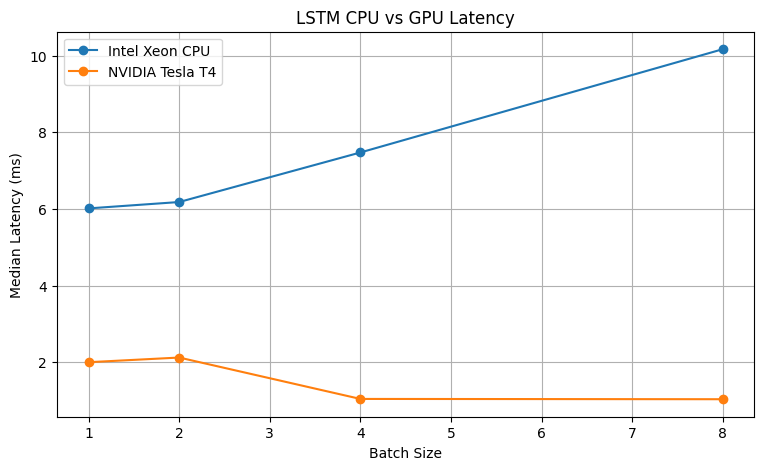

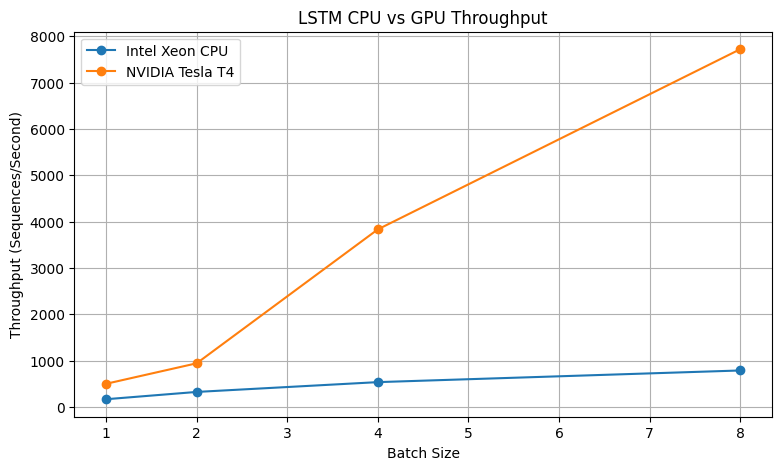

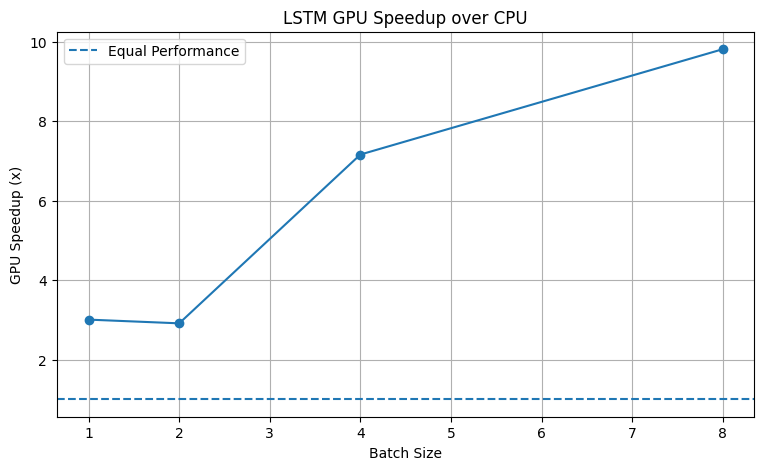

All three LSTM graphs saved successfully!


In [ ]:
import matplotlib.pyplot as plt
import os

# Ensure graph folder exists
os.makedirs(graphs, exist_ok=True)

# 1. LSTM Latency Comparison
plt.figure(figsize=(9, 5))

for device, group in df_lstm_combined.groupby("Device"):
    plt.plot(
        group["Batch_Size"],
        group["Median_Latency_ms"],
        marker="o",
        label=device
    )

plt.xlabel("Batch Size")
plt.ylabel("Median Latency (ms)")
plt.title("LSTM CPU vs GPU Latency")
plt.legend()
plt.grid(True)
plt.savefig(
    os.path.join(graphs, "lstm_latency_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# 2. LSTM Throughput Comparison
plt.figure(figsize=(9, 5))

for device, group in df_lstm_combined.groupby("Device"):
    plt.plot(
        group["Batch_Size"],
        group["Throughput_Sequences_Per_Second"],
        marker="o",
        label=device
    )

plt.xlabel("Batch Size")
plt.ylabel("Throughput (Sequences/Second)")
plt.title("LSTM CPU vs GPU Throughput")
plt.legend()
plt.grid(True)
plt.savefig(
    os.path.join(graphs, "lstm_throughput_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# 3. LSTM GPU Speedup
df_speedup = df_lstm_combined[
    df_lstm_combined["Device"] == "NVIDIA Tesla T4"
]

plt.figure(figsize=(9, 5))

plt.plot(
    df_speedup["Batch_Size"],
    df_speedup["GPU_Speedup"],
    marker="o"
)

plt.axhline(y=1, linestyle="--", label="Equal Performance")
plt.xlabel("Batch Size")
plt.ylabel("GPU Speedup (x)")
plt.title("LSTM GPU Speedup over CPU")
plt.legend()
plt.grid(True)
plt.savefig(
    os.path.join(graphs, "lstm_gpu_speedup.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("All three LSTM graphs saved successfully!")

In [ ]:
lstm_graphs = [
    "lstm_latency_comparison.png",
    "lstm_throughput_comparison.png",
    "lstm_gpu_speedup.png"
]

for filename in lstm_graphs:
    path = os.path.join(graphs, filename)

    if os.path.exists(path):
        print("✓ FOUND:", filename)
    else:
        print("✗ MISSING:", filename)

✓ FOUND: lstm_latency_comparison.png
✓ FOUND: lstm_throughput_comparison.png
✓ FOUND: lstm_gpu_speedup.png


In [ ]:
roofline_graphs = [
    "intel_xeon_cpu_roofline.png",
    "nvidia_tesla_t4_roofline.png",
    "google_cloud_tpu_v5e_1_roofline.png"
]

for filename in roofline_graphs:
    path = os.path.join(graphs, filename)

    if os.path.exists(path):
        print("✓ FOUND:", filename)
    else:
        print("✗ MISSING:", filename)

✗ MISSING: intel_xeon_cpu_roofline.png
✗ MISSING: nvidia_tesla_t4_roofline.png
✗ MISSING: google_cloud_tpu_v5e_1_roofline.png


In [ ]:
import os

required_files = [
    "combined_matrix_benchmark.csv",
    "combined_memory_bandwidth.csv"
]

for filename in required_files:
    path = os.path.join(raw, filename)

    if os.path.exists(path):
        print("✓ FOUND:", filename)
    else:
        print("✗ MISSING:", filename)

✗ MISSING: combined_matrix_benchmark.csv
✓ FOUND: combined_memory_bandwidth.csv


In [ ]:
import pandas as pd
import os

# Reconstruct matrix results from previously recorded outputs
matrix_data = [
    ["Intel Xeon CPU", 256, 0.289, 116.075981],
    ["Intel Xeon CPU", 512, 1.800, 149.107946],
    ["Intel Xeon CPU", 1024, 16.136, 133.082530],
    ["Intel Xeon CPU", 1536, 51.338, 141.176952],
    ["Intel Xeon CPU", 2048, 129.117, 133.056145],

    ["NVIDIA Tesla T4", 256, 0.061, 549.734704],
    ["NVIDIA Tesla T4", 512, 0.128, 2098.890143],
    ["NVIDIA Tesla T4", 1024, 0.730, 2941.315210],
    ["NVIDIA Tesla T4", 1536, 2.649, 2736.355965],
    ["NVIDIA Tesla T4", 2048, 6.078, 2826.772435],

    ["Google Cloud TPU v5e-1", 256, 0.297, 112.977886],
    ["Google Cloud TPU v5e-1", 512, 0.306, 877.240052],
    ["Google Cloud TPU v5e-1", 1024, 0.385, 5577.879605],
    ["Google Cloud TPU v5e-1", 1536, 0.576, 12582.912000],
    ["Google Cloud TPU v5e-1", 2048, 0.930, 18472.977617]
]

df_matrix = pd.DataFrame(
    matrix_data,
    columns=[
        "Device",
        "Matrix_Size",
        "Median_Time_ms",
        "GFLOPS"
    ]
)

# Load memory bandwidth results
df_memory = pd.read_csv(
    os.path.join(raw, "combined_memory_bandwidth.csv")
)

# Maximum measured bandwidth for each device
bandwidth_values = df_memory.groupby("Device")[
    "Bandwidth_GBps"
].max()

# Build Roofline input
df_roofline = df_matrix.copy()

df_roofline["Arithmetic_Intensity_FLOP_per_Byte"] = (
    2 * df_roofline["Matrix_Size"] / 12
)

df_roofline["Measured_Bandwidth_Ceiling_GBps"] = (
    df_roofline["Device"].map(bandwidth_values)
)

df_roofline["Data_Status"] = (
    "Reconstructed from recorded benchmark summaries; "
    "CPU/GPU and TPU timing methods differ"
)

# Save
roofline_path = os.path.join(
    raw,
    "roofline_input_data.csv"
)

df_roofline.to_csv(roofline_path, index=False)

display(df_roofline)

print("Roofline input rebuilt and saved!")
print(roofline_path)

,Device,Matrix_Size,Median_Time_ms,GFLOPS,Arithmetic_Intensity_FLOP_per_Byte,Measured_Bandwidth_Ceiling_GBps,Data_Status
0,Intel Xeon CPU,256,0.289,116.075981,42.666667,22.648432,Reconstructed from recorded benchmark summarie...
1,Intel Xeon CPU,512,1.800,149.107946,85.333333,22.648432,Reconstructed from recorded benchmark summarie...
2,Intel Xeon CPU,1024,16.136,133.082530,170.666667,22.648432,Reconstructed from recorded benchmark summarie...
3,Intel Xeon CPU,1536,51.338,141.176952,256.000000,22.648432,Reconstructed from recorded benchmark summarie...
4,Intel Xeon CPU,2048,129.117,133.056145,341.333333,22.648432,Reconstructed from recorded benchmark summarie...
5,NVIDIA Tesla T4,256,0.061,549.734704,42.666667,233.660000,Reconstructed from recorded benchmark summarie...
6,NVIDIA Tesla T4,512,0.128,2098.890143,85.333333,233.660000,Reconstructed from recorded benchmark summarie...
7,NVIDIA Tesla T4,1024,0.730,2941.315210,170.666667,233.660000,Reconstructed from recorded benchmark summarie...
8,NVIDIA Tesla T4,1536,2.649,2736.355965,256.000000,233.660000,Reconstructed from recorded benchmark summarie...
9,NVIDIA Tesla T4,2048,6.078,2826.772435,341.333333,233.660000,Reconstructed from recorded benchmark summarie...


Roofline input rebuilt and saved!
/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/roofline_input_data.csv


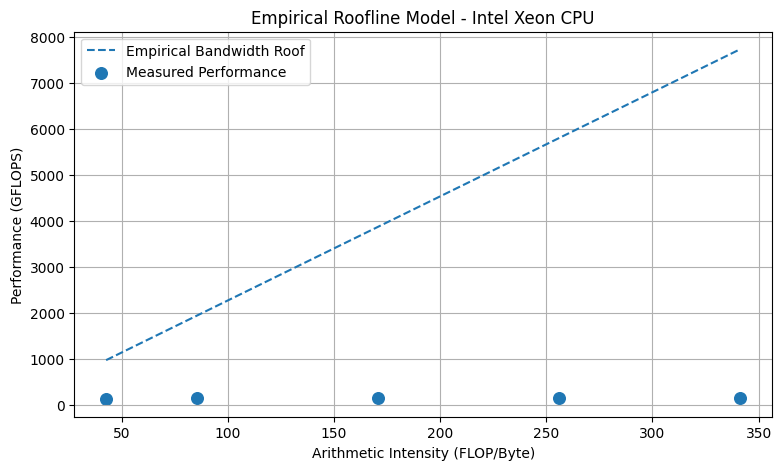

Saved: intel_xeon_cpu_roofline.png


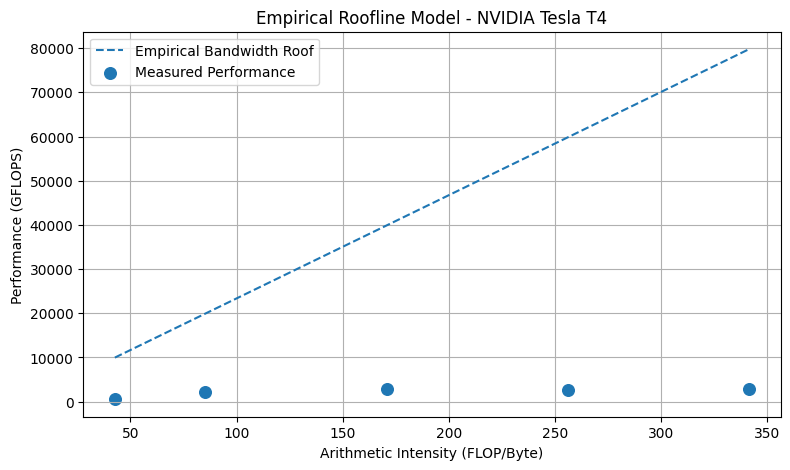

Saved: nvidia_tesla_t4_roofline.png


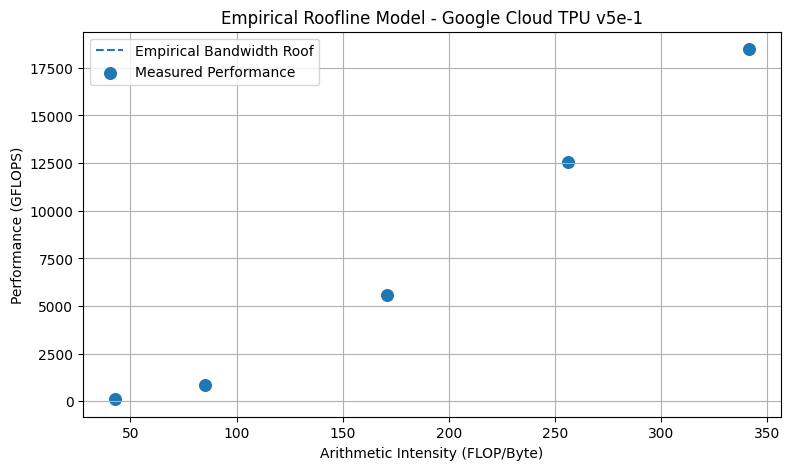

Saved: google_cloud_tpu_v5e_1_roofline.png
All Roofline graphs generated!


In [ ]:
import matplotlib.pyplot as plt
import os

device_files = {
    "Intel Xeon CPU": "intel_xeon_cpu_roofline.png",
    "NVIDIA Tesla T4": "nvidia_tesla_t4_roofline.png",
    "Google Cloud TPU v5e-1": "google_cloud_tpu_v5e_1_roofline.png"
}

for device, filename in device_files.items():

    subset = df_roofline[
        df_roofline["Device"] == device
    ].sort_values("Arithmetic_Intensity_FLOP_per_Byte")

    intensity = subset[
        "Arithmetic_Intensity_FLOP_per_Byte"
    ]

    bandwidth = subset[
        "Measured_Bandwidth_Ceiling_GBps"
    ].iloc[0]

    plt.figure(figsize=(9, 5))

    plt.plot(
        intensity,
        intensity * bandwidth,
        linestyle="--",
        label="Empirical Bandwidth Roof"
    )

    plt.scatter(
        intensity,
        subset["GFLOPS"],
        s=70,
        label="Measured Performance"
    )

    plt.xlabel("Arithmetic Intensity (FLOP/Byte)")
    plt.ylabel("Performance (GFLOPS)")
    plt.title(f"Empirical Roofline Model - {device}")
    plt.legend()
    plt.grid(True)

    plt.savefig(
        os.path.join(graphs, filename),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", filename)

print("All Roofline graphs generated!")

In [ ]:
roofline_graphs = [
    "intel_xeon_cpu_roofline.png",
    "nvidia_tesla_t4_roofline.png",
    "google_cloud_tpu_v5e_1_roofline.png"
]

for filename in roofline_graphs:
    path = os.path.join(graphs, filename)

    if os.path.exists(path):
        print("✓ FOUND:", filename)
    else:
        print("✗ MISSING:", filename)

✓ FOUND: intel_xeon_cpu_roofline.png
✓ FOUND: nvidia_tesla_t4_roofline.png
✓ FOUND: google_cloud_tpu_v5e_1_roofline.png


In [ ]:
import os

project = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison"

raw = os.path.join(project, "Results", "Raw_CSV")
graphs = os.path.join(project, "Results", "Graphs")
code = os.path.join(project, "Code")
documentation = os.path.join(project, "Documentation")

for folder in [project, raw, graphs, code, documentation]:
    print(
        "✓ FOUND" if os.path.exists(folder) else "✗ MISSING",
        folder
    )

✓ FOUND /content/gdrive/MyDrive/AI_Inference_Precision_Comparison
✓ FOUND /content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV
✓ FOUND /content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Graphs
✓ FOUND /content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Code
✓ FOUND /content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Documentation


In [ ]:
from torchvision import datasets, transforms

dataset_path = os.path.join(project, "Dataset")

os.makedirs(dataset_path, exist_ok=True)

transform = transforms.ToTensor()

train_dataset = datasets.FashionMNIST(
    root=dataset_path,
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root=dataset_path,
    train=False,
    download=True,
    transform=transform
)

print("Dataset downloaded successfully!")
print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Image shape:", train_dataset[0][0].shape)
print("Number of classes:", len(train_dataset.classes))
print("Classes:", train_dataset.classes)

100%|██████████| 26.4M/26.4M [00:01<00:00, 18.6MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 14.7MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.62MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 26.2MB/s]


Dataset downloaded successfully!
Training images: 60000
Testing images: 10000
Image shape: torch.Size([1, 28, 28])
Number of classes: 10
Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import copy
import numpy as np
import time

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# CNN architecture
class FashionCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


# Training configuration
BATCH_SIZE = 128
EPOCHS = 2
LEARNING_RATE = 0.001

# Data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(42)
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# Create initial model
base_model = FashionCNN()

# Save identical initial weights for both devices
initial_weights = copy.deepcopy(base_model.state_dict())

print("CNN model prepared!")
print("Parameters:", sum(p.numel() for p in base_model.parameters()))
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

CNN model prepared!
Parameters: 206922
Batch size: 128
Epochs: 2
Learning rate: 0.001
Training batches: 469
Testing batches: 79


In [ ]:
import time
import copy
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np

device = torch.device("cuda")

gpu_model = FashionCNN().to(device)
gpu_model.load_state_dict(initial_weights)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(
    gpu_model.parameters(),
    lr=LEARNING_RATE
)

gpu_training_results = []

torch.cuda.reset_peak_memory_stats()
total_start = time.perf_counter()

for epoch in range(EPOCHS):

    # Training
    gpu_model.train()
    correct = 0
    total = 0
    running_loss = 0.0

    torch.cuda.synchronize()
    epoch_start = time.perf_counter()

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = gpu_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    torch.cuda.synchronize()
    epoch_time = time.perf_counter() - epoch_start

    train_accuracy = 100 * correct / total

    # Testing
    gpu_model.eval()
    correct = 0
    total = 0

    with torch.inference_mode():
        for images, labels in test_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = gpu_model(images)
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    test_accuracy = 100 * correct / total

    gpu_training_results.append({
        "Device": "NVIDIA Tesla T4",
        "Epoch": epoch + 1,
        "Training_Time_sec": epoch_time,
        "Training_Loss": running_loss / len(train_loader),
        "Training_Accuracy": train_accuracy,
        "Test_Accuracy": test_accuracy
    })

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Time: {epoch_time:.2f}s | "
        f"Train Accuracy: {train_accuracy:.2f}% | "
        f"Test Accuracy: {test_accuracy:.2f}%"
    )

torch.cuda.synchronize()

gpu_total_time = time.perf_counter() - total_start
gpu_peak_memory = torch.cuda.max_memory_allocated() / (1024 ** 2)

df_gpu_training = pd.DataFrame(gpu_training_results)

print("\nGPU training completed!")
print("Total training time:", round(gpu_total_time, 2), "seconds")
print("Peak GPU memory:", round(gpu_peak_memory, 2), "MB")

display(df_gpu_training)

Epoch 1/2 | Time: 11.13s | Train Accuracy: 78.80% | Test Accuracy: 84.77%
Epoch 2/2 | Time: 8.55s | Train Accuracy: 86.81% | Test Accuracy: 87.41%

GPU training completed!
Total training time: 21.59 seconds
Peak GPU memory: 478.05 MB


,Device,Epoch,Training_Time_sec,Training_Loss,Training_Accuracy,Test_Accuracy
0,NVIDIA Tesla T4,1,11.132003,0.593934,78.798333,84.77
1,NVIDIA Tesla T4,2,8.545983,0.368921,86.806667,87.41


In [ ]:
gpu_training_path = os.path.join(
    raw,
    "cnn_gpu_training.csv"
)

df_gpu_training.to_csv(
    gpu_training_path,
    index=False
)

print("GPU training results saved!")
print(gpu_training_path)

print("Total elapsed time:", gpu_total_time)
print("Peak GPU memory (MB):", gpu_peak_memory)

GPU training results saved!
/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/cnn_gpu_training.csv
Total elapsed time: 21.586093273999722
Peak GPU memory (MB): 478.04736328125


In [ ]:
import time
import copy
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd

cpu_device = torch.device("cpu")
torch.set_num_threads(2)

cpu_model = FashionCNN().to(cpu_device)
cpu_model.load_state_dict(initial_weights)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(
    cpu_model.parameters(),
    lr=LEARNING_RATE
)

cpu_training_results = []

total_start = time.perf_counter()

for epoch in range(EPOCHS):

    cpu_model.train()
    correct = 0
    total = 0
    running_loss = 0.0

    epoch_start = time.perf_counter()

    for images, labels in train_loader:

        images = images.to(cpu_device)
        labels = labels.to(cpu_device)

        optimizer.zero_grad()

        outputs = cpu_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_time = time.perf_counter() - epoch_start
    train_accuracy = 100 * correct / total

    # Testing
    cpu_model.eval()
    correct = 0
    total = 0

    with torch.inference_mode():
        for images, labels in test_loader:

            outputs = cpu_model(images)
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    test_accuracy = 100 * correct / total

    cpu_training_results.append({
        "Device": "Intel Xeon CPU",
        "Epoch": epoch + 1,
        "Training_Time_sec": epoch_time,
        "Training_Loss": running_loss / len(train_loader),
        "Training_Accuracy": train_accuracy,
        "Test_Accuracy": test_accuracy
    })

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Time: {epoch_time:.2f}s | "
        f"Train Accuracy: {train_accuracy:.2f}% | "
        f"Test Accuracy: {test_accuracy:.2f}%"
    )

cpu_total_time = time.perf_counter() - total_start

df_cpu_training = pd.DataFrame(cpu_training_results)

print("\nCPU training completed!")
print("Total elapsed time:", round(cpu_total_time, 2), "seconds")

display(df_cpu_training)

Epoch 1/2 | Time: 66.38s | Train Accuracy: 78.35% | Test Accuracy: 85.08%
Epoch 2/2 | Time: 26.42s | Train Accuracy: 87.08% | Test Accuracy: 86.97%

CPU training completed!
Total elapsed time: 100.37 seconds


,Device,Epoch,Training_Time_sec,Training_Loss,Training_Accuracy,Test_Accuracy
0,Intel Xeon CPU,1,66.378472,0.596161,78.350,85.08
1,Intel Xeon CPU,2,26.419694,0.361503,87.085,86.97


In [ ]:
cpu_training_path = os.path.join(
    raw,
    "cnn_cpu_training.csv"
)

df_cpu_training.to_csv(
    cpu_training_path,
    index=False
)

print("CPU training results saved!")
print(cpu_training_path)

print("Total CPU elapsed time:", cpu_total_time)

CPU training results saved!
/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/cnn_cpu_training.csv
Total CPU elapsed time: 100.37094390600032


In [ ]:
df_training_combined = pd.concat(
    [df_cpu_training, df_gpu_training],
    ignore_index=True
)

# Calculate per-epoch GPU speedup
cpu_times = df_cpu_training.set_index(
    "Epoch"
)["Training_Time_sec"]

gpu_times = df_gpu_training.set_index(
    "Epoch"
)["Training_Time_sec"]

epoch_speedup = cpu_times / gpu_times

df_training_combined["GPU_Speedup"] = (
    df_training_combined["Epoch"].map(epoch_speedup)
)

# Save combined results
training_combined_path = os.path.join(
    raw,
    "combined_cnn_training.csv"
)

df_training_combined.to_csv(
    training_combined_path,
    index=False
)

print("Combined CNN training results:")
display(df_training_combined)

print("\nTotal elapsed time GPU:", round(gpu_total_time, 2), "seconds")
print("Total elapsed time CPU:", round(cpu_total_time, 2), "seconds")

print(
    "Overall GPU speedup:",
    round(cpu_total_time / gpu_total_time, 2),
    "x"
)

print("\nCombined training CSV saved!")
print(training_combined_path)

Combined CNN training results:


,Device,Epoch,Training_Time_sec,Training_Loss,Training_Accuracy,Test_Accuracy,GPU_Speedup
0,Intel Xeon CPU,1,66.378472,0.596161,78.350000,85.08,5.962851
1,Intel Xeon CPU,2,26.419694,0.361503,87.085000,86.97,3.091475
2,NVIDIA Tesla T4,1,11.132003,0.593934,78.798333,84.77,5.962851
3,NVIDIA Tesla T4,2,8.545983,0.368921,86.806667,87.41,3.091475



Total elapsed time GPU: 21.59 seconds
Total elapsed time CPU: 100.37 seconds
Overall GPU speedup: 4.65 x

Combined training CSV saved!
/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/combined_cnn_training.csv


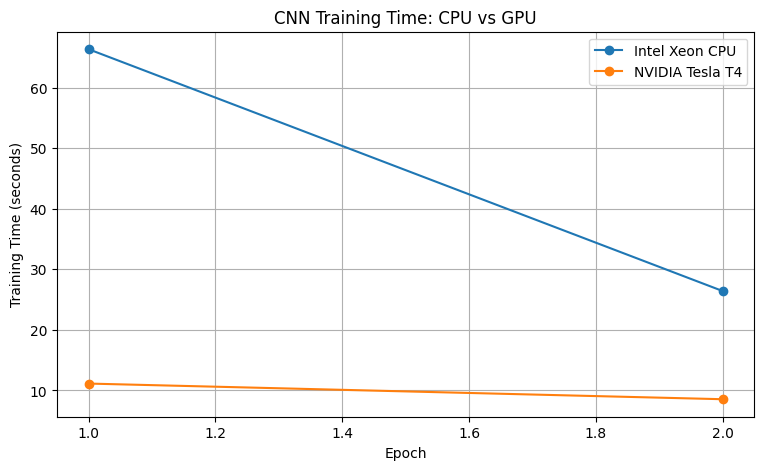

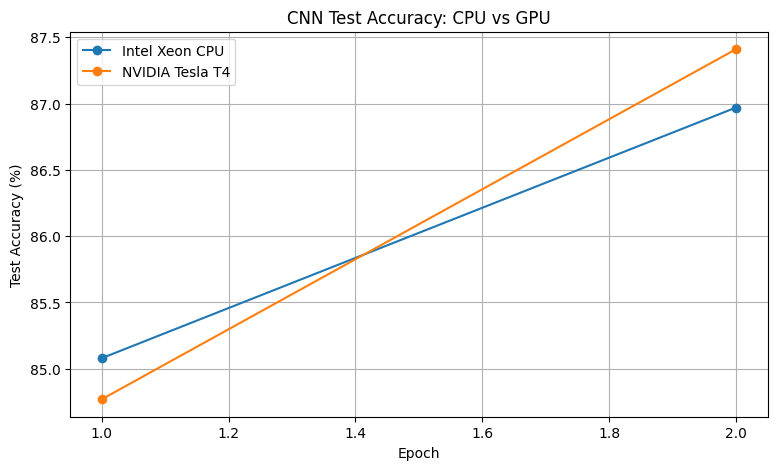

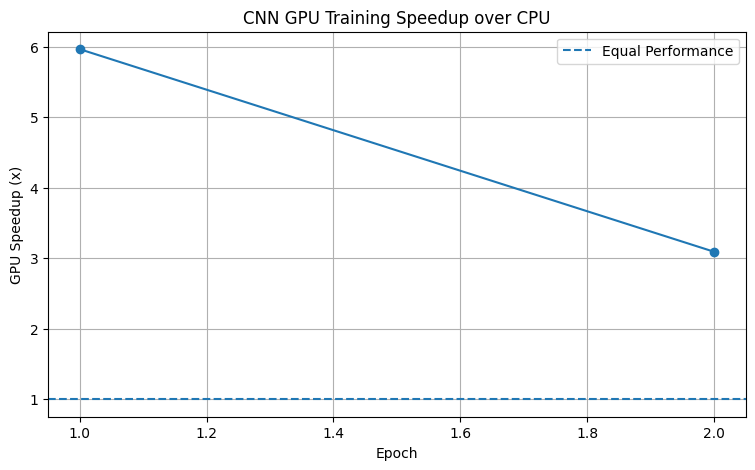

All CNN training graphs generated!


In [ ]:
import matplotlib.pyplot as plt
import os

# 1. Training time comparison
plt.figure(figsize=(9, 5))

for device, group in df_training_combined.groupby("Device"):
    plt.plot(
        group["Epoch"],
        group["Training_Time_sec"],
        marker="o",
        label=device
    )

plt.xlabel("Epoch")
plt.ylabel("Training Time (seconds)")
plt.title("CNN Training Time: CPU vs GPU")
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(graphs, "cnn_training_time.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# 2. Accuracy comparison
plt.figure(figsize=(9, 5))

for device, group in df_training_combined.groupby("Device"):
    plt.plot(
        group["Epoch"],
        group["Test_Accuracy"],
        marker="o",
        label=device
    )

plt.xlabel("Epoch")
plt.ylabel("Test Accuracy (%)")
plt.title("CNN Test Accuracy: CPU vs GPU")
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(graphs, "cnn_training_accuracy.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# 3. GPU speedup
plt.figure(figsize=(9, 5))

gpu_data = df_training_combined[
    df_training_combined["Device"] == "NVIDIA Tesla T4"
]

plt.plot(
    gpu_data["Epoch"],
    gpu_data["GPU_Speedup"],
    marker="o"
)

plt.axhline(
    y=1,
    linestyle="--",
    label="Equal Performance"
)

plt.xlabel("Epoch")
plt.ylabel("GPU Speedup (x)")
plt.title("CNN GPU Training Speedup over CPU")
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(graphs, "cnn_training_speedup.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("All CNN training graphs generated!")

In [ ]:
training_graphs = [
    "cnn_training_time.png",
    "cnn_training_accuracy.png",
    "cnn_training_speedup.png"
]

for filename in training_graphs:

    path = os.path.join(graphs, filename)

    if os.path.exists(path):
        print("✓ FOUND:", filename)
    else:
        print("✗ MISSING:", filename)

✓ FOUND: cnn_training_time.png
✓ FOUND: cnn_training_accuracy.png
✓ FOUND: cnn_training_speedup.png


In [ ]:
import pandas as pd
import os

# Measured overall GPU speedup
measured_speedup = cpu_total_time / gpu_total_time

# Amdahl's Law analysis
parallel_fractions = [0.50, 0.70, 0.80, 0.90, 0.95, 0.99]
processing_units = [2, 4, 8, 16]

amdahl_results = []

for P in parallel_fractions:
    for N in processing_units:

        speedup = 1 / ((1 - P) + (P / N))

        amdahl_results.append({
            "Parallel_Fraction": P,
            "Serial_Fraction": 1 - P,
            "Processing_Units": N,
            "Theoretical_Speedup": speedup
        })

df_amdahl = pd.DataFrame(amdahl_results)

# Save results
amdahl_path = os.path.join(
    raw,
    "amdahl_law_analysis.csv"
)

df_amdahl.to_csv(amdahl_path, index=False)

print("Measured CNN GPU speedup:", round(measured_speedup, 2), "x")

print("\nAmdahl's Law theoretical results:")
display(df_amdahl)

print("\nSaved:", amdahl_path)

Measured CNN GPU speedup: 4.65 x

Amdahl's Law theoretical results:


,Parallel_Fraction,Serial_Fraction,Processing_Units,Theoretical_Speedup
0,0.50,0.50,2,1.333333
1,0.50,0.50,4,1.600000
2,0.50,0.50,8,1.777778
3,0.50,0.50,16,1.882353
4,0.70,0.30,2,1.538462
5,0.70,0.30,4,2.105263
6,0.70,0.30,8,2.580645
7,0.70,0.30,16,2.909091
8,0.80,0.20,2,1.666667
9,0.80,0.20,4,2.500000



Saved: /content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/amdahl_law_analysis.csv


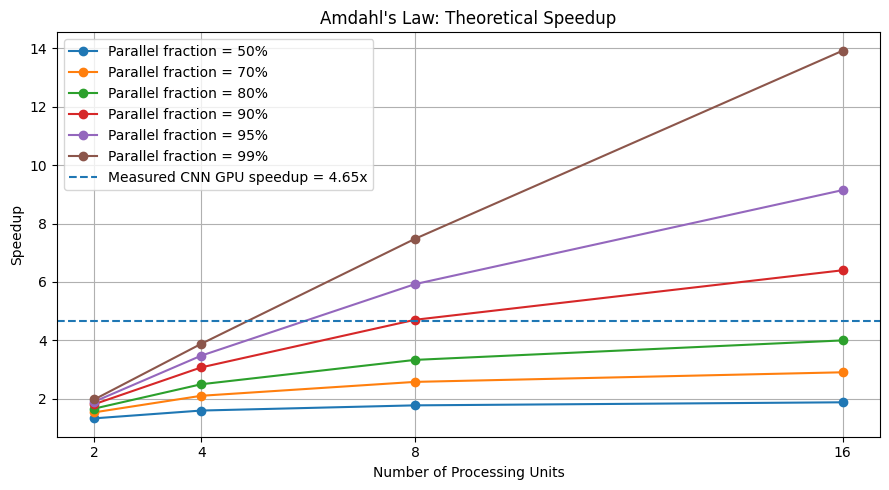

Amdahl's Law graph saved: /content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Graphs/amdahl_law_speedup.png


In [ ]:
import matplotlib.pyplot as plt
import os

plt.figure(figsize=(9, 5))

for P, group in df_amdahl.groupby("Parallel_Fraction"):
    plt.plot(
        group["Processing_Units"],
        group["Theoretical_Speedup"],
        marker="o",
        label=f"Parallel fraction = {P:.0%}"
    )

plt.axhline(
    y=measured_speedup,
    linestyle="--",
    label=f"Measured CNN GPU speedup = {measured_speedup:.2f}x"
)

plt.xlabel("Number of Processing Units")
plt.ylabel("Speedup")
plt.title("Amdahl's Law: Theoretical Speedup")
plt.xticks([2, 4, 8, 16])
plt.grid(True)
plt.legend()
plt.tight_layout()

path = os.path.join(graphs, "amdahl_law_speedup.png")
plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print("Amdahl's Law graph saved:", path)

In [ ]:
import os

path = os.path.join(graphs, "amdahl_law_speedup.png")

print(
    "✓ FOUND: amdahl_law_speedup.png"
    if os.path.exists(path)
    else "✗ MISSING: amdahl_law_speedup.png"
)

✓ FOUND: amdahl_law_speedup.png


In [ ]:
import platform
import subprocess

print("CPU INFORMATION")
print("----------------")

print("Processor:", platform.processor())
print("Architecture:", platform.machine())

print("\nCPU DETAILS:")
result = subprocess.run(
    ["lscpu"],
    capture_output=True,
    text=True
)

print(result.stdout)

print("\nPERFORMANCE COUNTER AVAILABILITY:")
perf = subprocess.run(
    ["perf", "stat", "echo", "Iron Law Test"],
    capture_output=True,
    text=True
)

print(perf.stderr if perf.stderr else perf.stdout)

CPU INFORMATION
----------------
Processor: x86_64
Architecture: x86_64

CPU DETAILS:
Architecture:                            x86_64
CPU op-mode(s):                          32-bit, 64-bit
Address sizes:                           46 bits physical, 48 bits virtual
Byte Order:                              Little Endian
CPU(s):                                  2
On-line CPU(s) list:                     0,1
Vendor ID:                               GenuineIntel
Model name:                              Intel(R) Xeon(R) CPU @ 2.00GHz
CPU family:                              6
Model:                                   85
Thread(s) per core:                      2
Core(s) per socket:                      1
Socket(s):                               1
Stepping:                                3
BogoMIPS:                                4000.38
Flags:                                   fpu vme de pse tsc msr pae mce cx8 apic sep mtrr pge mca cmov pat pse36 clflush mmx fxsr sse sse2 ss ht syscall nx pd

FileNotFoundError: [Errno 2] No such file or directory: 'perf'

In [ ]:
import torch
import pandas as pd
import os

torch.set_num_threads(2)

# Reproducible CPU workload
torch.manual_seed(42)

A = torch.randn(512, 512, device="cpu")
B = torch.randn(512, 512, device="cpu")

# Warm-up
for _ in range(3):
    C = torch.matmul(A, B)

# Profile CPU operations
with torch.profiler.profile(
    activities=[torch.profiler.ProfilerActivity.CPU],
    record_shapes=True,
    profile_memory=True
) as prof:

    for _ in range(5):
        C = torch.matmul(A, B)

# Extract operator statistics
rows = []

for event in prof.key_averages():
    rows.append({
        "Operator": event.key,
        "Calls": event.count,
        "CPU_Time_Total_us": event.cpu_time_total,
        "CPU_Time_Average_us": event.cpu_time,
        "CPU_Memory_Bytes": event.cpu_memory_usage
    })

df_cpu_profile = pd.DataFrame(rows)

display(df_cpu_profile)

# Save profiling data
profile_path = os.path.join(
    raw,
    "cpu_iron_law_software_profile.csv"
)

df_cpu_profile.to_csv(profile_path, index=False)

print("CPU profiling data saved:", profile_path)

/usr/local/lib/python3.13/dist-packages/torch/profiler/profiler.py:224: UserWarning: Warning: Profiler clears events at the end of each cycle.Only events from the current cycle will be reported.To keep events across cycles, set acc_events=True.
  _warn_once(


,Operator,Calls,CPU_Time_Total_us,CPU_Time_Average_us,CPU_Memory_Bytes
0,aten::matmul,5,106583.604,21316.720800,5242880
1,aten::mm,5,106488.075,21297.615000,5242880
2,aten::resolve_conj,15,9.473,0.631533,0
3,[memory],4,0.000,0.000000,-4194304


CPU profiling data saved: /content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/cpu_iron_law_software_profile.csv


In [ ]:
import pandas as pd
import os

mm_event = df_cpu_profile[
    df_cpu_profile["Operator"] == "aten::mm"
].iloc[0]

instruction_metrics = {
    "Device": "Intel Xeon CPU",
    "Workload": "512x512 Matrix Multiplication",
    "Number_of_Calls": int(mm_event["Calls"]),
    "Total_CPU_Time_us": mm_event["CPU_Time_Total_us"],
    "Average_Time_per_Call_us": mm_event["CPU_Time_Total_us"] / mm_event["Calls"],
    "Instruction_Count": "Unavailable",
    "Measured_CPI": "Unavailable",
    "Reason": "Linux perf utility unavailable in Colab"
}

df_iron_law = pd.DataFrame([instruction_metrics])

display(df_iron_law)

iron_path = os.path.join(
    raw,
    "cpu_iron_law_analysis.csv"
)

df_iron_law.to_csv(iron_path, index=False)

print("Iron Law analysis saved:", iron_path)

,Device,Workload,Number_of_Calls,Total_CPU_Time_us,Average_Time_per_Call_us,Instruction_Count,Measured_CPI,Reason
0,Intel Xeon CPU,512x512 Matrix Multiplication,5,106488.075,21297.615,Unavailable,Unavailable,Linux perf utility unavailable in Colab


Iron Law analysis saved: /content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/cpu_iron_law_analysis.csv


In [ ]:
iron_law_notes = """
CPU IRON LAW PROFILING

CPU:
Intel Xeon CPU @ 2.00 GHz
Architecture: x86-64
Logical CPUs available: 2
Environment: Google Colab virtual machine (KVM)

Workload:
512 x 512 matrix multiplication
5 profiled calls

Software profiling:
Total CPU time: 106488.075 microseconds
Average time per call: 21297.615 microseconds

Iron Law:
CPU Execution Time = Instruction Count x CPI x Clock Cycle Time

Limitations:
1. Linux perf utility was unavailable in the Colab environment.
2. Hardware instruction counts could not be collected.
3. Hardware cycle counts could not be collected.
4. Actual CPI could not be calculated.
5. PyTorch profiler provided software-level operator timings,
   not hardware performance-counter measurements.

Conclusion:
Software-level profiling was successfully performed.
Hardware-level Iron Law analysis remains limited by
virtualized Colab access and unavailable performance counters.
No instruction count or CPI values were fabricated.
"""

notes_path = os.path.join(
    documentation,
    "cpu_iron_law_limitations.txt"
)

with open(notes_path, "w") as f:
    f.write(iron_law_notes)

print("Iron Law documentation saved!")
print(notes_path)

Iron Law documentation saved!
/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Documentation/cpu_iron_law_limitations.txt


In [ ]:
import torch
import time
import statistics
import pandas as pd
import os

torch.manual_seed(42)

N = 1024

A = torch.randn(N, N)
B = torch.randn(N, N)

thread_results = []

for threads in [1, 2]:

    torch.set_num_threads(threads)

    # Warm-up
    for _ in range(3):
        C = torch.matmul(A, B)

    times = []

    # Ten measurements
    for _ in range(10):

        start = time.perf_counter()

        C = torch.matmul(A, B)

        end = time.perf_counter()

        times.append(end - start)

    median_time = statistics.median(times)

    gflops = (2 * N**3) / median_time / 1e9

    thread_results.append({
        "CPU_Threads": threads,
        "Matrix_Size": N,
        "Median_Time_ms": median_time * 1000,
        "GFLOPS": gflops
    })

df_thread_scaling = pd.DataFrame(thread_results)

display(df_thread_scaling)

thread_path = os.path.join(
    raw,
    "cpu_thread_scaling.csv"
)

df_thread_scaling.to_csv(thread_path, index=False)

print("Thread scaling results saved:", thread_path)

,CPU_Threads,Matrix_Size,Median_Time_ms,GFLOPS
0,1,1024,27.778268,77.308048
1,2,1024,34.465955,62.307388


Thread scaling results saved: /content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/cpu_thread_scaling.csv


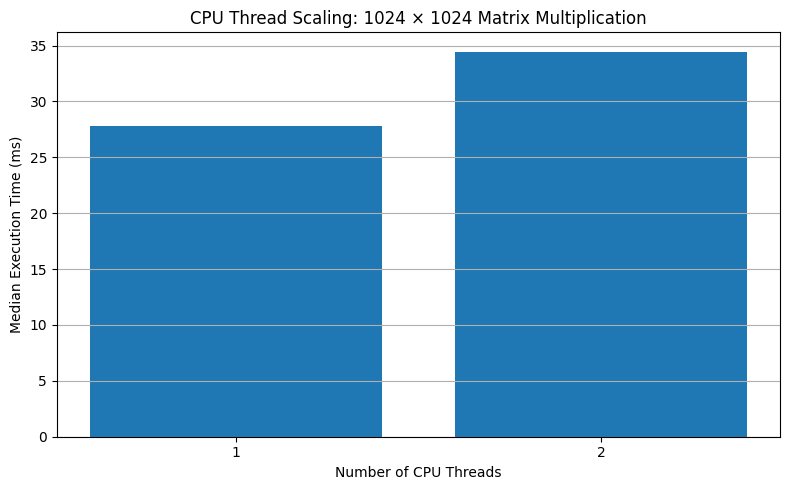

Graph saved: /content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Graphs/cpu_thread_scaling.png


In [ ]:
import matplotlib.pyplot as plt
import os

plt.figure(figsize=(8, 5))

plt.bar(
    df_thread_scaling["CPU_Threads"].astype(str),
    df_thread_scaling["Median_Time_ms"]
)

plt.xlabel("Number of CPU Threads")
plt.ylabel("Median Execution Time (ms)")
plt.title("CPU Thread Scaling: 1024 × 1024 Matrix Multiplication")
plt.grid(axis="y")
plt.tight_layout()

path = os.path.join(graphs, "cpu_thread_scaling.png")

plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print("Graph saved:", path)

In [ ]:
print(os.path.exists(path), path)

True /content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Graphs/cpu_thread_scaling.png


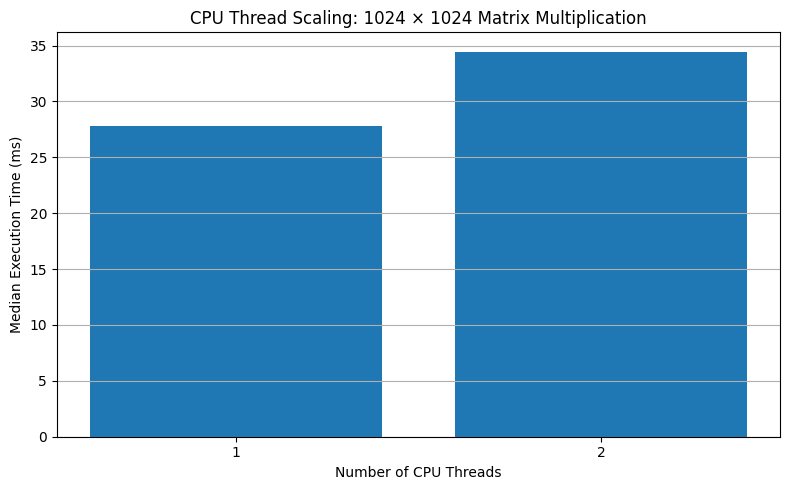

Graph saved: /content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Graphs/cpu_thread_scaling.png


In [ ]:
import matplotlib.pyplot as plt
import os

plt.figure(figsize=(8, 5))

plt.bar(
    df_thread_scaling["CPU_Threads"].astype(str),
    df_thread_scaling["Median_Time_ms"]
)

plt.xlabel("Number of CPU Threads")
plt.ylabel("Median Execution Time (ms)")
plt.title("CPU Thread Scaling: 1024 × 1024 Matrix Multiplication")
plt.grid(axis="y")
plt.tight_layout()

path = os.path.join(graphs, "cpu_thread_scaling.png")

plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print("Graph saved:", path)

In [ ]:
print("Graph exists:", os.path.exists(path))

Graph exists: True


In [ ]:
import os
from google.colab import drive

drive.mount('/content/gdrive')

project = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison"

folders = [
    "Code",
    "Dataset",
    "Documentation",
    "Research_Paper",
    "Results/Raw_CSV",
    "Results/Graphs"
]

for folder in folders:
    path = os.path.join(project, folder)

    print("\n", folder)

    if os.path.exists(path):
        files = os.listdir(path)
        print("FOUND | Files:", len(files))

        for file in files:
            print(" -", file)
    else:
        print("NOT FOUND")

Mounted at /content/gdrive

 Code
FOUND | Files: 0

 Dataset
FOUND | Files: 1
 - FashionMNIST

 Documentation
FOUND | Files: 3
 - hardware_inventory.json
 - cpu_iron_law_limitations.txt
 - hardware_architecture_comparison.csv

 Research_Paper
FOUND | Files: 0

 Results/Raw_CSV
FOUND | Files: 26
 - experiment_log.csv
 - matrix_multiplication_cpu_gpu.csv
 - memory_bandwidth_gpu.csv
 - memory_bandwidth_cpu.csv
 - memory_bandwidth_tpu.csv
 - combined_memory_bandwidth.csv
 - gpu_precision_comparison.csv
 - resnet50_gpu_inference.csv
 - resnet50_cpu_inference.csv
 - combined_resnet50_inference.csv
 - resnet50_gpu_wall_timing.csv
 - resnet50_cpu_gpu_fair_comparison.csv
 - distilbert_gpu_inference.csv
 - distilbert_cpu_inference.csv
 - combined_distilbert_inference.csv
 - lstm_cpu_inference.csv
 - lstm_gpu_inference.csv
 - combined_lstm_inference.csv
 - roofline_input_data.csv
 - cnn_gpu_training.csv
 - cnn_cpu_training.csv
 - combined_cnn_training.csv
 - amdahl_law_analysis.csv
 - cpu_iron_la

In [ ]:
import os

raw = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV"

required_files = [
    "combined_matrix_benchmark.csv",
    "combined_precision_all_sizes.csv",
    "cpu_precision_comparison.csv",
    "gpu_precision_all_sizes.csv",
    "host_device_transfer.csv",
    "matrix_multiplication_tpu_validated.csv",
    "tpu_precision_comparison.csv",
    "tpu_precision_timing_validation.csv"
]

for filename in required_files:
    path = os.path.join(raw, filename)

    if os.path.exists(path):
        print("FOUND:", filename)
    else:
        print("NOT FOUND:", filename)

NOT FOUND: combined_matrix_benchmark.csv
NOT FOUND: combined_precision_all_sizes.csv
NOT FOUND: cpu_precision_comparison.csv
NOT FOUND: gpu_precision_all_sizes.csv
NOT FOUND: host_device_transfer.csv
NOT FOUND: matrix_multiplication_tpu_validated.csv
NOT FOUND: tpu_precision_comparison.csv
NOT FOUND: tpu_precision_timing_validation.csv


In [ ]:
import os
import pandas as pd

raw = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV"

files = [
    "matrix_multiplication_cpu_gpu.csv",
    "gpu_precision_comparison.csv",
    "memory_bandwidth_cpu.csv",
    "memory_bandwidth_gpu.csv",
    "memory_bandwidth_tpu.csv",
    "resnet50_cpu_gpu_fair_comparison.csv",
    "experiment_log.csv"
]

for filename in files:
    path = os.path.join(raw, filename)

    print("\n" + "="*60)
    print(filename)

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Columns:", list(df.columns))
        print(df.head(3).to_string(index=False))
    else:
        print("FILE NOT FOUND")


matrix_multiplication_cpu_gpu.csv
Columns: ['Device', 'Matrix_Size', 'Precision', 'Repetitions', 'Median_Seconds', 'Mean_Seconds', 'Std_Seconds', 'GFLOPS']
Device  Matrix_Size Precision  Repetitions  Median_Seconds  Mean_Seconds  Std_Seconds     GFLOPS
   CPU          256      FP32           10        0.000289      0.000294     0.000013 116.075981
   GPU          256      FP32           10        0.000061      0.000063     0.000007 549.734704
   CPU          512      FP32           10        0.001800      0.001795     0.000100 149.107946

gpu_precision_comparison.csv
Columns: ['Device', 'Precision', 'Matrix_Size', 'Median_Time_ms', 'Max_Error', 'Mean_Error', 'RMSE']
         Device Precision  Matrix_Size  Median_Time_ms  Max_Error  Mean_Error     RMSE
NVIDIA Tesla T4      FP32         1024        0.854121   0.000000    0.000000 0.000000
NVIDIA Tesla T4      FP16         1024        0.166571   0.079193    0.009036 0.011491
NVIDIA Tesla T4      BF16         1024        1.492358   0.5754

In [ ]:
import os
import pandas as pd

raw = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV"

# Load original CPU and GPU measurements
df = pd.read_csv(
    os.path.join(raw, "matrix_multiplication_cpu_gpu.csv")
)

combined = pd.DataFrame({
    "Device": df["Device"],
    "Matrix_Size": df["Matrix_Size"],
    "Median_Time_ms": df["Median_Seconds"] * 1000,
    "GFLOPS": df["GFLOPS"],
    "Data_Status": "Original saved measurement"
})

# Previously recorded TPU host-timing results
tpu_data = {
    "Matrix_Size": [256, 512, 1024, 1536, 2048],
    "Median_Time_ms": [0.297, 0.306, 0.385, 0.576, 0.930],
    "GFLOPS": [
        112.977886, 877.240052, 5577.879605,
        12582.912000, 18472.977617
    ]
}

tpu = pd.DataFrame(tpu_data)
tpu["Device"] = "TPU v5e-1"
tpu["Data_Status"] = "Reconstructed from recorded TPU host timings"

tpu = tpu[combined.columns]

# Combine and save
combined = pd.concat([combined, tpu], ignore_index=True)

output = os.path.join(raw, "combined_matrix_benchmark.csv")
combined.to_csv(output, index=False)

print("Combined matrix benchmark saved!")
print("Rows:", len(combined))
print("Location:", output)
print(combined.to_string(index=False))

Combined matrix benchmark saved!
Rows: 15
Location: /content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/combined_matrix_benchmark.csv
   Device  Matrix_Size  Median_Time_ms       GFLOPS                                  Data_Status
      CPU          256        0.289073   116.075981                   Original saved measurement
      GPU          256        0.061038   549.734704                   Original saved measurement
      CPU          512        1.800276   149.107946                   Original saved measurement
      GPU          512        0.127894  2098.890143                   Original saved measurement
      CPU         1024       16.136480   133.082530                   Original saved measurement
      GPU         1024        0.730110  2941.315210                   Original saved measurement
      CPU         2048      129.117443   133.056145                   Original saved measurement
      GPU         2048        6.077557  2826.772435                 

In [ ]:
import os
import pandas as pd

raw = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV"

# CPU precision results
cpu_data = [
    ["Intel Xeon CPU", "FP32", 256, 3.611096, 0, 0, 0, "Single run"],
    ["Intel Xeon CPU", "FP16", 256, 28.107131, 0.029602, 0.004542, 0.005789, "Single run"],
    ["Intel Xeon CPU", "BF16", 256, 15.344216, 0.238396, 0.036346, 0.046268, "Single run"],
    ["Intel Xeon CPU", "FP32", 512, 4.373623, 0, 0, 0, "Single run"],
    ["Intel Xeon CPU", "FP16", 512, 216.667706, 0.048714, 0.006382, 0.008105, "Single run"],
    ["Intel Xeon CPU", "BF16", 512, 156.556824, 0.352341, 0.051100, 0.064992, "Single run"],
    ["Intel Xeon CPU", "FP32", 1024, 36.998404, 0, 0, 0, "10 repetitions"],
    ["Intel Xeon CPU", "FP16", 1024, 3844.777126, 0.083710, 0.009059, 0.011522, "10 repetitions"],
    ["Intel Xeon CPU", "BF16", 1024, 3917.890336, 0.574890, 0.072580, 0.092238, "10 repetitions"]
]

columns = [
    "Device", "Precision", "Matrix_Size", "Median_Time_ms",
    "Max_Error", "Mean_Error", "RMSE", "Timing_Method"
]

cpu_df = pd.DataFrame(cpu_data, columns=columns)
cpu_df["Data_Status"] = "Reconstructed from recorded results"

cpu_df.to_csv(os.path.join(raw, "cpu_precision_comparison.csv"), index=False)

print("CPU precision file restored.")
print(cpu_df.to_string(index=False))

CPU precision file restored.
        Device Precision  Matrix_Size  Median_Time_ms  Max_Error  Mean_Error     RMSE  Timing_Method                         Data_Status
Intel Xeon CPU      FP32          256        3.611096   0.000000    0.000000 0.000000     Single run Reconstructed from recorded results
Intel Xeon CPU      FP16          256       28.107131   0.029602    0.004542 0.005789     Single run Reconstructed from recorded results
Intel Xeon CPU      BF16          256       15.344216   0.238396    0.036346 0.046268     Single run Reconstructed from recorded results
Intel Xeon CPU      FP32          512        4.373623   0.000000    0.000000 0.000000     Single run Reconstructed from recorded results
Intel Xeon CPU      FP16          512      216.667706   0.048714    0.006382 0.008105     Single run Reconstructed from recorded results
Intel Xeon CPU      BF16          512      156.556824   0.352341    0.051100 0.064992     Single run Reconstructed from recorded results
Intel Xeon C

In [ ]:
import os
import pandas as pd

raw = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV"

gpu_data = [
    ["NVIDIA Tesla T4", "FP32", 256, 0.086764, 0, 0, 0],
    ["NVIDIA Tesla T4", "FP16", 256, 0.107443, 0.032310, 0.004544, 0.005784],
    ["NVIDIA Tesla T4", "BF16", 256, 0.108230, 0.257217, 0.036432, 0.046393],

    ["NVIDIA Tesla T4", "FP32", 512, 0.187298, 0, 0, 0],
    ["NVIDIA Tesla T4", "FP16", 512, 0.079458, 0.048256, 0.006393, 0.008132],
    ["NVIDIA Tesla T4", "BF16", 512, 0.273519, 0.383034, 0.051161, 0.065097],

    ["NVIDIA Tesla T4", "FP32", 1024, 0.900514, 0, 0, 0],
    ["NVIDIA Tesla T4", "FP16", 1024, 0.200020, 0.082199, 0.009036, 0.011490],
    ["NVIDIA Tesla T4", "BF16", 1024, 1.562538, 0.570435, 0.072345, 0.091970]
]

columns = [
    "Device", "Precision", "Matrix_Size", "Median_Time_ms",
    "Max_Error", "Mean_Error", "RMSE"
]

gpu_df = pd.DataFrame(gpu_data, columns=columns)

gpu_df["Timing_Method"] = "1 warmup, 3 repetitions"
gpu_df["Data_Status"] = "Reconstructed from recorded results"

output = os.path.join(raw, "gpu_precision_all_sizes.csv")
gpu_df.to_csv(output, index=False)

print("GPU precision file restored!")
print("Rows:", len(gpu_df))
print("Saved at:", output)
print(gpu_df.to_string(index=False))

GPU precision file restored!
Rows: 9
Saved at: /content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/gpu_precision_all_sizes.csv
         Device Precision  Matrix_Size  Median_Time_ms  Max_Error  Mean_Error     RMSE           Timing_Method                         Data_Status
NVIDIA Tesla T4      FP32          256        0.086764   0.000000    0.000000 0.000000 1 warmup, 3 repetitions Reconstructed from recorded results
NVIDIA Tesla T4      FP16          256        0.107443   0.032310    0.004544 0.005784 1 warmup, 3 repetitions Reconstructed from recorded results
NVIDIA Tesla T4      BF16          256        0.108230   0.257217    0.036432 0.046393 1 warmup, 3 repetitions Reconstructed from recorded results
NVIDIA Tesla T4      FP32          512        0.187298   0.000000    0.000000 0.000000 1 warmup, 3 repetitions Reconstructed from recorded results
NVIDIA Tesla T4      FP16          512        0.079458   0.048256    0.006393 0.008132 1 warmup, 3 repetitions Recon

In [ ]:
import os
import pandas as pd

raw = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV"

# Combine CPU and GPU precision results
cpu = pd.read_csv(os.path.join(raw, "cpu_precision_comparison.csv"))
gpu = pd.read_csv(os.path.join(raw, "gpu_precision_all_sizes.csv"))

combined = pd.concat([cpu, gpu], ignore_index=True)

combined.to_csv(
    os.path.join(raw, "combined_precision_all_sizes.csv"),
    index=False
)

print("CPU + GPU precision dataset saved.")
print("Rows:", len(combined))

# Restore TPU precision-mode results separately
# These are FP32 matmul precision settings, NOT FP16/BF16 formats.
tpu_data = [
    [256, "medium", 0.307, 0.18210411, 0.03777457],
    [256, "high", 0.303, 0.00111008, 0.00020831],
    [256, "highest", 0.305, 0.00002289, 0.00000352],

    [512, "medium", 0.279, 0.26791382, 0.05326051],
    [512, "high", 0.312, 0.00151062, 0.00029414],
    [512, "highest", 0.317, 0.00005341, 0.00000574],

    [1024, "medium", 0.322, 0.38045692, 0.07524784],
    [1024, "high", 0.352, 0.00219727, 0.00041515],
    [1024, "highest", 0.403, 0.00007248, 0.00000890],

    [1536, "medium", 0.370, 0.47424316, 0.09207034],
    [1536, "high", 0.443, 0.00302124, 0.00050931],
    [1536, "highest", 0.564, 0.00009155, 0.00001164],

    [2048, "medium", 0.470, 0.57023239, 0.10641143],
    [2048, "high", 0.619, 0.00329590, 0.00058729],
    [2048, "highest", 0.925, 0.00012207, 0.00001413]
]

tpu_df = pd.DataFrame(
    tpu_data,
    columns=[
        "Matrix_Size", "Precision_Mode", "Median_Time_ms",
        "Max_Error", "RMSE"
    ]
)

tpu_df.insert(0, "Device", "Google Cloud TPU v5e-1")
tpu_df["Data_Status"] = "Reconstructed from recorded TPU results"

tpu_df.to_csv(
    os.path.join(raw, "tpu_precision_comparison.csv"),
    index=False
)

print("\nTPU precision-mode dataset saved.")
print("Rows:", len(tpu_df))
print(tpu_df.to_string(index=False))

CPU + GPU precision dataset saved.
Rows: 18

TPU precision-mode dataset saved.
Rows: 15
                Device  Matrix_Size Precision_Mode  Median_Time_ms  Max_Error     RMSE                             Data_Status
Google Cloud TPU v5e-1          256         medium           0.307   0.182104 0.037775 Reconstructed from recorded TPU results
Google Cloud TPU v5e-1          256           high           0.303   0.001110 0.000208 Reconstructed from recorded TPU results
Google Cloud TPU v5e-1          256        highest           0.305   0.000023 0.000004 Reconstructed from recorded TPU results
Google Cloud TPU v5e-1          512         medium           0.279   0.267914 0.053261 Reconstructed from recorded TPU results
Google Cloud TPU v5e-1          512           high           0.312   0.001511 0.000294 Reconstructed from recorded TPU results
Google Cloud TPU v5e-1          512        highest           0.317   0.000053 0.000006 Reconstructed from recorded TPU results
Google Cloud TPU v5e-1 

In [ ]:
import os
import pandas as pd

raw = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV"

# 1. TPU end-to-end timing validation
tpu_timing = {
    "Matrix_Size": [256, 512, 1024, 1536, 2048],
    "Medium_Time_ms": [1.071, 2.202, 8.963, 17.773, 31.052],
    "High_Time_ms": [1.046, 2.165, 8.924, 17.952, 31.104],
    "Highest_Time_ms": [1.106, 2.214, 9.403, 18.321, 31.398]
}

timing_df = pd.DataFrame(tpu_timing)
timing_df["Data_Status"] = "Reconstructed from recorded TPU timing results"

timing_df.to_csv(
    os.path.join(raw, "tpu_precision_timing_validation.csv"),
    index=False
)

print("TPU timing validation saved:", len(timing_df), "rows")

# 2. GPU host-device transfer summary
transfer_data = [
    ["CPU to GPU", 1, 0.444, 2.361658],
    ["CPU to GPU", 4, 2.999, 1.398568],
    ["CPU to GPU", 16, 7.609, 2.204917],
    ["CPU to GPU", 64, 15.451, 4.343335],
    ["CPU to GPU", 128, 31.204, 4.301299],

    ["GPU to CPU", 1, 0.356, 2.945438],
    ["GPU to CPU", 4, 0.991, 4.232396],
    ["GPU to CPU", 16, 3.528, 4.755447],
    ["GPU to CPU", 64, 45.009, 1.491010],
    ["GPU to CPU", 128, 91.069, 1.473803]
]

transfer_df = pd.DataFrame(
    transfer_data,
    columns=[
        "Direction", "Data_Size_MiB",
        "Transfer_Time_ms", "Effective_Bandwidth_GBps"
    ]
)

transfer_df["Device"] = "NVIDIA Tesla T4"
transfer_df["Data_Size_Bytes"] = (
    transfer_df["Data_Size_MiB"] * 1024**2
).astype("int64")

transfer_df["Timing_Statistic"] = "Upper-middle order statistic"
transfer_df["Data_Status"] = "Reconstructed from recorded console summary"

transfer_df.to_csv(
    os.path.join(raw, "host_device_transfer.csv"),
    index=False
)

print("GPU transfer summary saved:", len(transfer_df), "rows")
print("\nTransfer results:")
print(transfer_df.to_string(index=False))

TPU timing validation saved: 5 rows
GPU transfer summary saved: 10 rows

Transfer results:
 Direction  Data_Size_MiB  Transfer_Time_ms  Effective_Bandwidth_GBps          Device  Data_Size_Bytes             Timing_Statistic                                 Data_Status
CPU to GPU              1             0.444                  2.361658 NVIDIA Tesla T4          1048576 Upper-middle order statistic Reconstructed from recorded console summary
CPU to GPU              4             2.999                  1.398568 NVIDIA Tesla T4          4194304 Upper-middle order statistic Reconstructed from recorded console summary
CPU to GPU             16             7.609                  2.204917 NVIDIA Tesla T4         16777216 Upper-middle order statistic Reconstructed from recorded console summary
CPU to GPU             64            15.451                  4.343335 NVIDIA Tesla T4         67108864 Upper-middle order statistic Reconstructed from recorded console summary
CPU to GPU            128    

In [ ]:
import os
import pandas as pd

raw = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV"

tpu_data = {
    "Device": ["TPU v5e-1"] * 5,
    "Matrix_Size": [256, 512, 1024, 1536, 2048],
    "Event_Time_ms": [0.269, 0.277, 0.356, 0.548, 0.894],
    "Host_Time_ms": [0.297, 0.306, 0.385, 0.576, 0.930],
    "GFLOPS_Event": [
        124.737665, 969.081069, 6032.257438,
        13225.834511, 19216.855911
    ],
    "GFLOPS_Host": [
        112.977886, 877.240052, 5577.879605,
        12582.912000, 18472.977617
    ]
}

df = pd.DataFrame(tpu_data)
df["Data_Status"] = "Reconstructed from recorded TPU timing summary"

path = os.path.join(raw, "matrix_multiplication_tpu_validated.csv")
df.to_csv(path, index=False)

print("TPU matrix validation file restored.")
print(df.to_string(index=False))

TPU matrix validation file restored.
   Device  Matrix_Size  Event_Time_ms  Host_Time_ms  GFLOPS_Event  GFLOPS_Host                                    Data_Status
TPU v5e-1          256          0.269         0.297    124.737665   112.977886 Reconstructed from recorded TPU timing summary
TPU v5e-1          512          0.277         0.306    969.081069   877.240052 Reconstructed from recorded TPU timing summary
TPU v5e-1         1024          0.356         0.385   6032.257438  5577.879605 Reconstructed from recorded TPU timing summary
TPU v5e-1         1536          0.548         0.576  13225.834511 12582.912000 Reconstructed from recorded TPU timing summary
TPU v5e-1         2048          0.894         0.930  19216.855911 18472.977617 Reconstructed from recorded TPU timing summary


In [ ]:
import os

project = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison"

raw = os.path.join(project, "Results/Raw_CSV")
graphs = os.path.join(project, "Results/Graphs")

expected_csv = [
    "matrix_multiplication_cpu_gpu.csv",
    "combined_matrix_benchmark.csv",
    "matrix_multiplication_tpu_validated.csv",
    "memory_bandwidth_cpu.csv",
    "memory_bandwidth_gpu.csv",
    "memory_bandwidth_tpu.csv",
    "combined_memory_bandwidth.csv",
    "cpu_precision_comparison.csv",
    "gpu_precision_comparison.csv",
    "gpu_precision_all_sizes.csv",
    "combined_precision_all_sizes.csv",
    "tpu_precision_comparison.csv",
    "tpu_precision_timing_validation.csv",
    "host_device_transfer.csv",
    "resnet50_cpu_gpu_fair_comparison.csv",
    "combined_distilbert_inference.csv",
    "combined_lstm_inference.csv",
    "combined_cnn_training.csv",
    "roofline_input_data.csv",
    "amdahl_law_analysis.csv",
    "cpu_iron_law_analysis.csv",
    "cpu_thread_scaling.csv"
]

expected_graphs = [
    "matrix_performance_gflops.png",
    "matrix_latency_comparison.png",
    "memory_bandwidth_comparison.png",
    "intel_xeon_cpu_precision_time.png",
    "nvidia_tesla_t4_precision_time.png",
    "intel_xeon_cpu_roofline.png",
    "nvidia_tesla_t4_roofline.png",
    "google_cloud_tpu_v5e_1_roofline.png",
    "host_device_transfer_latency.png",
    "host_device_transfer_bandwidth.png",
    "resnet50_latency_comparison.png",
    "distilbert_latency_comparison.png",
    "lstm_latency_comparison.png",
    "cnn_training_time.png",
    "cnn_training_accuracy.png",
    "amdahl_law_speedup.png",
    "cpu_thread_scaling.png"
]

print("========== CSV AUDIT ==========")
missing_csv = []

for f in expected_csv:
    exists = os.path.exists(os.path.join(raw, f))
    print(("FOUND: " if exists else "MISSING: ") + f)
    if not exists:
        missing_csv.append(f)

print("\n========== GRAPH AUDIT ==========")
missing_graphs = []

for f in expected_graphs:
    exists = os.path.exists(os.path.join(graphs, f))
    print(("FOUND: " if exists else "MISSING: ") + f)
    if not exists:
        missing_graphs.append(f)

print("\n========== SUMMARY ==========")
print("CSV missing:", len(missing_csv))
print("Graphs missing:", len(missing_graphs))
print("Total CSV files:", len(os.listdir(raw)))
print("Total graph files:", len(os.listdir(graphs)))

========== CSV AUDIT ==========
FOUND: matrix_multiplication_cpu_gpu.csv
FOUND: combined_matrix_benchmark.csv
FOUND: matrix_multiplication_tpu_validated.csv
FOUND: memory_bandwidth_cpu.csv
FOUND: memory_bandwidth_gpu.csv
FOUND: memory_bandwidth_tpu.csv
FOUND: combined_memory_bandwidth.csv
FOUND: cpu_precision_comparison.csv
FOUND: gpu_precision_comparison.csv
FOUND: gpu_precision_all_sizes.csv
FOUND: combined_precision_all_sizes.csv
FOUND: tpu_precision_comparison.csv
FOUND: tpu_precision_timing_validation.csv
FOUND: host_device_transfer.csv
FOUND: resnet50_cpu_gpu_fair_comparison.csv
FOUND: combined_distilbert_inference.csv
FOUND: combined_lstm_inference.csv
FOUND: combined_cnn_training.csv
FOUND: roofline_input_data.csv
FOUND: amdahl_law_analysis.csv
FOUND: cpu_iron_law_analysis.csv
FOUND: cpu_thread_scaling.csv

========== GRAPH AUDIT ==========
MISSING: matrix_performance_gflops.png
MISSING: matrix_latency_comparison.png
FOUND: memory_bandwidth_comparison.png
MISSING: intel_xeon_cp

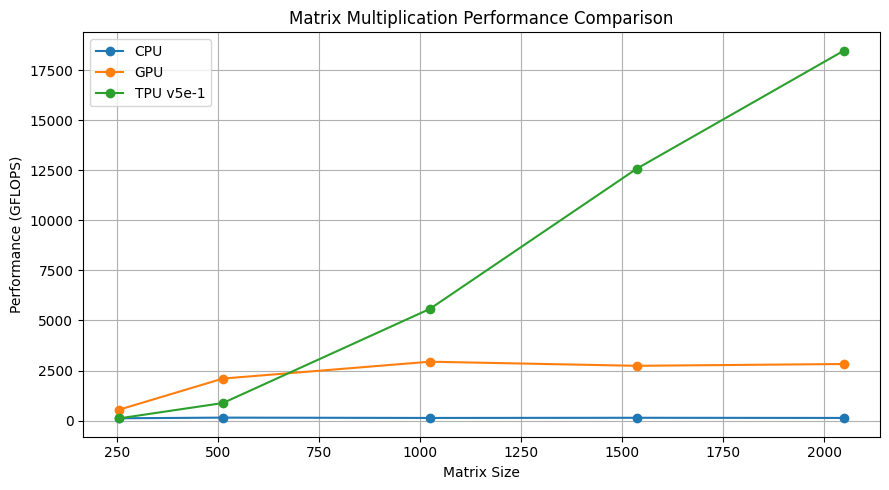

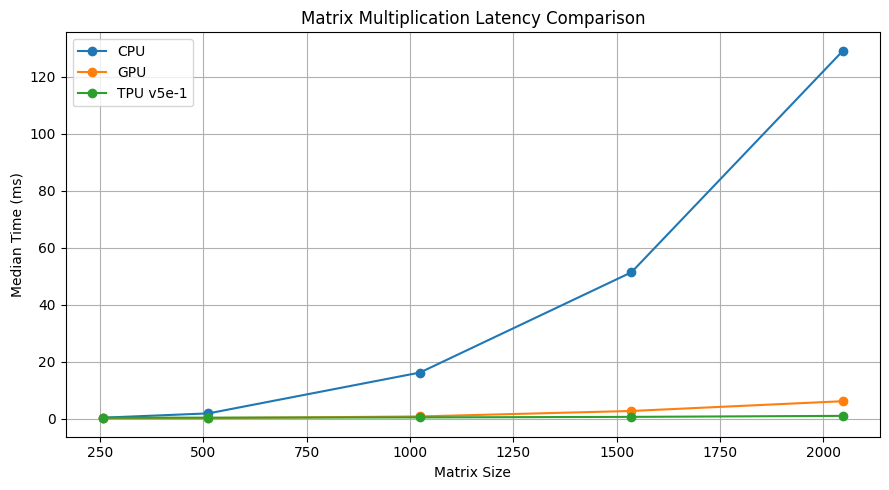

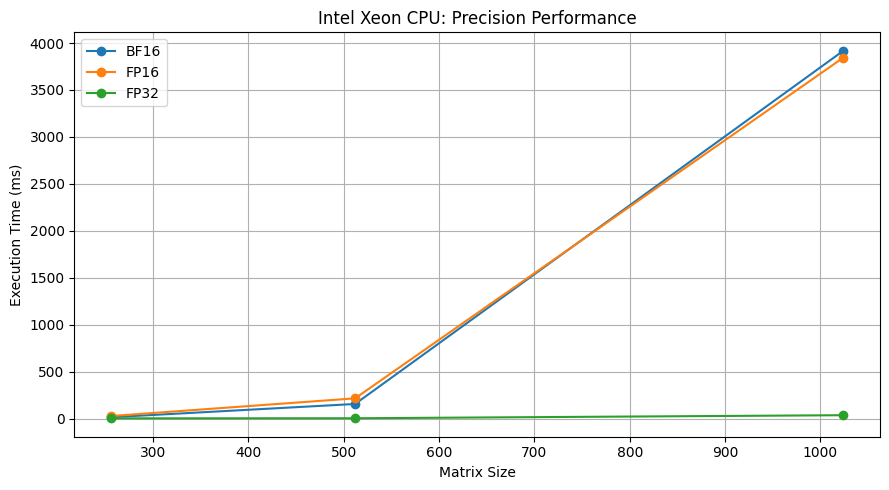

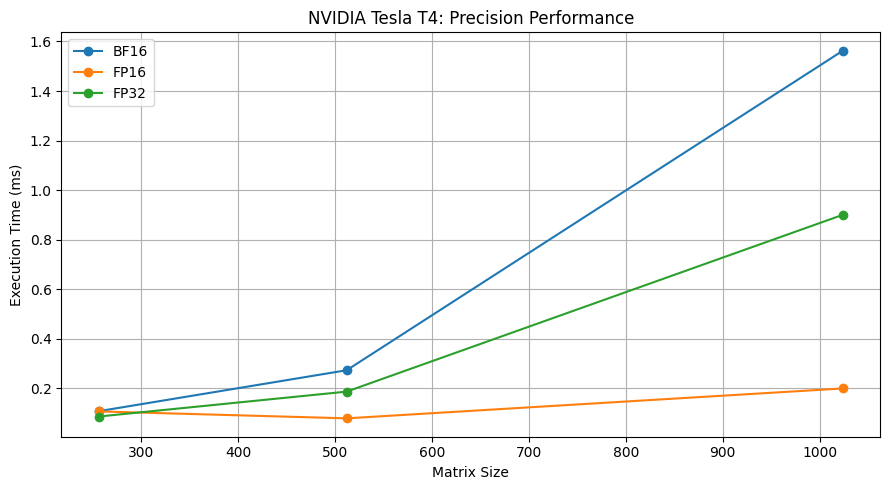

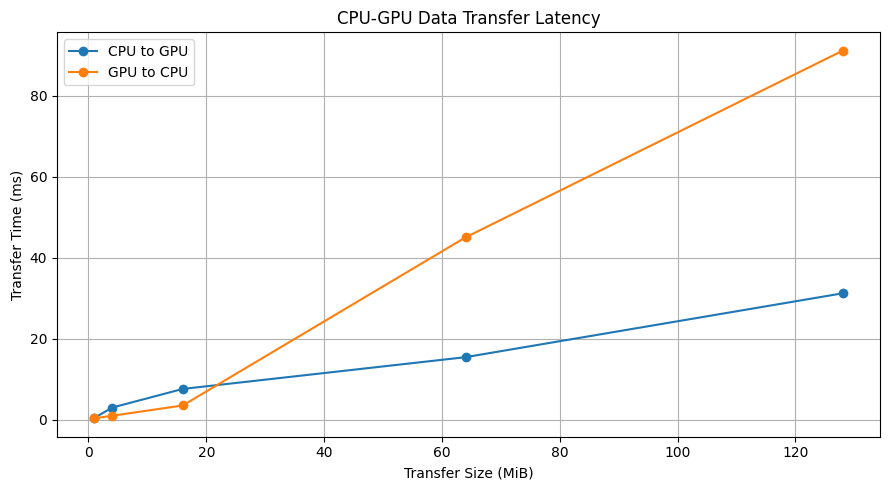

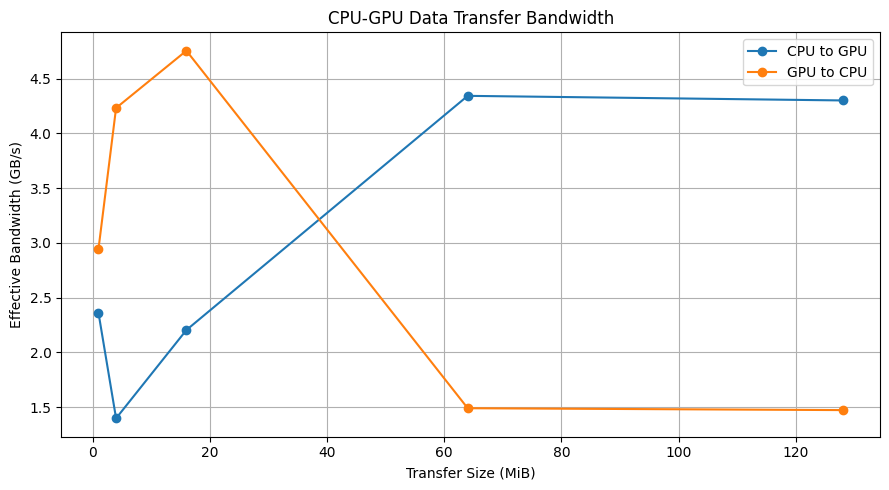


ALL SIX GRAPHS GENERATED!
FOUND: matrix_performance_gflops.png
FOUND: matrix_latency_comparison.png
FOUND: intel_xeon_cpu_precision_time.png
FOUND: nvidia_tesla_t4_precision_time.png
FOUND: host_device_transfer_latency.png
FOUND: host_device_transfer_bandwidth.png

Graphs folder: /content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Graphs


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt

project = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison"
raw = os.path.join(project, "Results/Raw_CSV")
graphs = os.path.join(project, "Results/Graphs")

os.makedirs(graphs, exist_ok=True)

# ==========================================
# 1. MATRIX MULTIPLICATION PERFORMANCE
# ==========================================

df = pd.read_csv(os.path.join(raw, "combined_matrix_benchmark.csv"))

plt.figure(figsize=(9, 5))

for device, group in df.groupby("Device"):
    group = group.sort_values("Matrix_Size")
    plt.plot(
        group["Matrix_Size"],
        group["GFLOPS"],
        marker="o",
        label=device
    )

plt.xlabel("Matrix Size")
plt.ylabel("Performance (GFLOPS)")
plt.title("Matrix Multiplication Performance Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(graphs, "matrix_performance_gflops.png"), dpi=300)
plt.show()
plt.close()


# ==========================================
# 2. MATRIX MULTIPLICATION LATENCY
# ==========================================

plt.figure(figsize=(9, 5))

for device, group in df.groupby("Device"):
    group = group.sort_values("Matrix_Size")
    plt.plot(
        group["Matrix_Size"],
        group["Median_Time_ms"],
        marker="o",
        label=device
    )

plt.xlabel("Matrix Size")
plt.ylabel("Median Time (ms)")
plt.title("Matrix Multiplication Latency Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(graphs, "matrix_latency_comparison.png"), dpi=300)
plt.show()
plt.close()


# ==========================================
# 3. CPU PRECISION TIME
# ==========================================

precision = pd.read_csv(
    os.path.join(raw, "combined_precision_all_sizes.csv")
)

cpu = precision[precision["Device"] == "Intel Xeon CPU"]

plt.figure(figsize=(9, 5))

for fmt, group in cpu.groupby("Precision"):
    group = group.sort_values("Matrix_Size")
    plt.plot(
        group["Matrix_Size"],
        group["Median_Time_ms"],
        marker="o",
        label=fmt
    )

plt.xlabel("Matrix Size")
plt.ylabel("Execution Time (ms)")
plt.title("Intel Xeon CPU: Precision Performance")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(graphs, "intel_xeon_cpu_precision_time.png"), dpi=300)
plt.show()
plt.close()


# ==========================================
# 4. GPU PRECISION TIME
# ==========================================

gpu = precision[precision["Device"] == "NVIDIA Tesla T4"]

plt.figure(figsize=(9, 5))

for fmt, group in gpu.groupby("Precision"):
    group = group.sort_values("Matrix_Size")
    plt.plot(
        group["Matrix_Size"],
        group["Median_Time_ms"],
        marker="o",
        label=fmt
    )

plt.xlabel("Matrix Size")
plt.ylabel("Execution Time (ms)")
plt.title("NVIDIA Tesla T4: Precision Performance")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(graphs, "nvidia_tesla_t4_precision_time.png"), dpi=300)
plt.show()
plt.close()


# ==========================================
# 5. HOST-TO-DEVICE TRANSFER LATENCY
# ==========================================

transfer = pd.read_csv(
    os.path.join(raw, "host_device_transfer.csv")
)

plt.figure(figsize=(9, 5))

for direction, group in transfer.groupby("Direction"):
    group = group.sort_values("Data_Size_MiB")
    plt.plot(
        group["Data_Size_MiB"],
        group["Transfer_Time_ms"],
        marker="o",
        label=direction
    )

plt.xlabel("Transfer Size (MiB)")
plt.ylabel("Transfer Time (ms)")
plt.title("CPU-GPU Data Transfer Latency")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(graphs, "host_device_transfer_latency.png"), dpi=300)
plt.show()
plt.close()


# ==========================================
# 6. HOST-DEVICE TRANSFER BANDWIDTH
# ==========================================

plt.figure(figsize=(9, 5))

for direction, group in transfer.groupby("Direction"):
    group = group.sort_values("Data_Size_MiB")
    plt.plot(
        group["Data_Size_MiB"],
        group["Effective_Bandwidth_GBps"],
        marker="o",
        label=direction
    )

plt.xlabel("Transfer Size (MiB)")
plt.ylabel("Effective Bandwidth (GB/s)")
plt.title("CPU-GPU Data Transfer Bandwidth")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(graphs, "host_device_transfer_bandwidth.png"), dpi=300)
plt.show()
plt.close()


# ==========================================
# FINAL CONFIRMATION
# ==========================================

print("\nALL SIX GRAPHS GENERATED!")

for filename in [
    "matrix_performance_gflops.png",
    "matrix_latency_comparison.png",
    "intel_xeon_cpu_precision_time.png",
    "nvidia_tesla_t4_precision_time.png",
    "host_device_transfer_latency.png",
    "host_device_transfer_bandwidth.png"
]:
    path = os.path.join(graphs, filename)
    print(("FOUND: " if os.path.exists(path) else "MISSING: ") + filename)

print("\nGraphs folder:", graphs)

In [ ]:
import os
import glob

# Project CSV folder in Google Drive
raw_folder = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV"

# Check folder
if not os.path.exists(raw_folder):
    print("CSV folder not found. Check Google Drive mounting.")
else:
    csv_files = sorted(glob.glob(os.path.join(raw_folder, "*.csv")))

    print("========== CSV FILE AUDIT ==========")
    print("Total CSV files:", len(csv_files))
    print()

    for file in csv_files:
        print(os.path.basename(file), "|",
              round(os.path.getsize(file) / 1024, 2), "KB")

    print("\n========== AUDIT COMPLETE ==========")

========== CSV FILE AUDIT ==========
Total CSV files: 34

amdahl_law_analysis.csv | 1.05 KB
cnn_cpu_training.csv | 0.2 KB
cnn_gpu_training.csv | 0.23 KB
combined_cnn_training.csv | 0.44 KB
combined_distilbert_inference.csv | 1.1 KB
combined_lstm_inference.csv | 1.05 KB
combined_matrix_benchmark.csv | 1.13 KB
combined_memory_bandwidth.csv | 0.5 KB
combined_precision_all_sizes.csv | 2.05 KB
combined_resnet50_inference.csv | 1.39 KB
cpu_iron_law_analysis.csv | 0.25 KB
cpu_iron_law_software_profile.csv | 0.25 KB
cpu_precision_comparison.csv | 1.01 KB
cpu_thread_scaling.csv | 0.13 KB
distilbert_cpu_inference.csv | 0.52 KB
distilbert_gpu_inference.csv | 0.53 KB
experiment_log.csv | 0.08 KB
gpu_precision_all_sizes.csv | 1.13 KB
gpu_precision_comparison.csv | 0.24 KB
host_device_transfer.csv | 1.35 KB
lstm_cpu_inference.csv | 0.5 KB
lstm_gpu_inference.csv | 0.51 KB
matrix_multiplication_cpu_gpu.csv | 1.07 KB
matrix_multiplication_tpu_validated.csv | 0.55 KB
memory_bandwidth_cpu.csv | 0.25 KB
m

In [ ]:
import os
import glob
import pandas as pd

raw_folder = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV"

csv_files = sorted(glob.glob(os.path.join(raw_folder, "*.csv")))

print("=" * 70)
print("COMPLETE CSV CONTENT STRUCTURE AUDIT")
print("=" * 70)

for file in csv_files:
    df = pd.read_csv(file)

    print("\nFILE:", os.path.basename(file))
    print("Rows:", len(df))
    print("Columns:", len(df.columns))
    print("Column names:", list(df.columns))

    if "Data_Status" in df.columns:
        print("Data Status:")
        print(df["Data_Status"].value_counts(dropna=False).to_dict())

print("\n" + "=" * 70)
print("STRUCTURE AUDIT COMPLETE")
print("Total files inspected:", len(csv_files))

COMPLETE CSV CONTENT STRUCTURE AUDIT

FILE: amdahl_law_analysis.csv
Rows: 24
Columns: 4
Column names: ['Parallel_Fraction', 'Serial_Fraction', 'Processing_Units', 'Theoretical_Speedup']

FILE: cnn_cpu_training.csv
Rows: 2
Columns: 6
Column names: ['Device', 'Epoch', 'Training_Time_sec', 'Training_Loss', 'Training_Accuracy', 'Test_Accuracy']

FILE: cnn_gpu_training.csv
Rows: 2
Columns: 6
Column names: ['Device', 'Epoch', 'Training_Time_sec', 'Training_Loss', 'Training_Accuracy', 'Test_Accuracy']

FILE: combined_cnn_training.csv
Rows: 4
Columns: 7
Column names: ['Device', 'Epoch', 'Training_Time_sec', 'Training_Loss', 'Training_Accuracy', 'Test_Accuracy', 'GPU_Speedup']

FILE: combined_distilbert_inference.csv
Rows: 8
Columns: 9
Column names: ['Device', 'Model', 'Batch_Size', 'Sequence_Length', 'Median_Latency_ms', 'Mean_Latency_ms', 'Std_Dev_ms', 'Throughput_Sequences_Per_Second', 'GPU_Speedup']

FILE: combined_lstm_inference.csv
Rows: 8
Columns: 9
Column names: ['Device', 'Model', 'Bat

In [ ]:
import pandas as pd
import os

raw = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV"

files = [
    "matrix_multiplication_cpu_gpu.csv",
    "combined_matrix_benchmark.csv",
    "matrix_multiplication_tpu_validated.csv"
]

for filename in files:
    print("\n" + "=" * 75)
    print("FILE:", filename)
    print("=" * 75)

    df = pd.read_csv(os.path.join(raw, filename))
    print(df.to_string(index=False))


FILE: matrix_multiplication_cpu_gpu.csv
Device  Matrix_Size Precision  Repetitions  Median_Seconds  Mean_Seconds  Std_Seconds      GFLOPS
   CPU          256      FP32           10        0.000289      0.000294     0.000013  116.075981
   GPU          256      FP32           10        0.000061      0.000063     0.000007  549.734704
   CPU          512      FP32           10        0.001800      0.001795     0.000100  149.107946
   GPU          512      FP32           10        0.000128      0.000128     0.000002 2098.890143
   CPU         1024      FP32           10        0.016136      0.017012     0.002586  133.082530
   GPU         1024      FP32           10        0.000730      0.000733     0.000012 2941.315210
   CPU         2048      FP32           10        0.129117      0.131315     0.012575  133.056145
   GPU         2048      FP32           10        0.006078      0.006082     0.000015 2826.772435
   CPU         1536      FP32           10        0.051338      0.054201     

In [ ]:
import pandas as pd
import os

raw = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV"

files = [
    "cpu_precision_comparison.csv",
    "gpu_precision_comparison.csv",
    "gpu_precision_all_sizes.csv",
    "combined_precision_all_sizes.csv",
    "tpu_precision_comparison.csv",
    "tpu_precision_timing_validation.csv"
]

for filename in files:
    print("\n" + "=" * 80)
    print("FILE:", filename)
    print("=" * 80)

    df = pd.read_csv(os.path.join(raw, filename))
    print(df.to_string(index=False))


FILE: cpu_precision_comparison.csv
        Device Precision  Matrix_Size  Median_Time_ms  Max_Error  Mean_Error     RMSE  Timing_Method                         Data_Status
Intel Xeon CPU      FP32          256        3.611096   0.000000    0.000000 0.000000     Single run Reconstructed from recorded results
Intel Xeon CPU      FP16          256       28.107131   0.029602    0.004542 0.005789     Single run Reconstructed from recorded results
Intel Xeon CPU      BF16          256       15.344216   0.238396    0.036346 0.046268     Single run Reconstructed from recorded results
Intel Xeon CPU      FP32          512        4.373623   0.000000    0.000000 0.000000     Single run Reconstructed from recorded results
Intel Xeon CPU      FP16          512      216.667706   0.048714    0.006382 0.008105     Single run Reconstructed from recorded results
Intel Xeon CPU      BF16          512      156.556824   0.352341    0.051100 0.064992     Single run Reconstructed from recorded results
Intel

In [ ]:
import pandas as pd
import os

raw = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV"

files = [
    "memory_bandwidth_cpu.csv",
    "memory_bandwidth_gpu.csv",
    "memory_bandwidth_tpu.csv",
    "combined_memory_bandwidth.csv"
]

for filename in files:
    print("\n" + "=" * 70)
    print("FILE:", filename)
    print("=" * 70)

    df = pd.read_csv(os.path.join(raw, filename))
    print(df.to_string(index=False))


FILE: memory_bandwidth_cpu.csv
        Device  Elements  Data_Size_MB  Median_Time_ms  Bandwidth_GBps
Intel Xeon CPU   1000000          12.0        0.529838       22.648432
Intel Xeon CPU   4000000          48.0        2.870705       16.720631
Intel Xeon CPU  16000000         192.0       29.674066        6.470296

FILE: memory_bandwidth_gpu.csv
         Device  Elements  Data_Size_MB  Median_Time_ms  Bandwidth_GBps
NVIDIA Tesla T4   1000000          12.0          0.0745          161.08
NVIDIA Tesla T4   4000000          48.0          0.2263          212.07
NVIDIA Tesla T4  16000000         192.0          0.8217          233.66

FILE: memory_bandwidth_tpu.csv
   Device  Elements  Data_Size_MB  Median_Time_ms  Bandwidth_GBps
TPU v5e-1   1000000            12        0.293615       40.869847
TPU v5e-1   4000000            48        0.366610      130.929325
TPU v5e-1  16000000           192        0.571880      335.734770

FILE: combined_memory_bandwidth.csv
         Device  Elements  Data

In [ ]:
import pandas as pd
import os

raw = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV"

filename = "host_device_transfer.csv"

df = pd.read_csv(os.path.join(raw, filename))

print("========== HOST-DEVICE TRANSFER AUDIT ==========")
print(df.to_string(index=False))

print("\n========== SUMMARY ==========")
print(df.groupby("Direction")[
    ["Data_Size_MiB", "Transfer_Time_ms",
     "Effective_Bandwidth_GBps"]
].to_string())

print("\nData status:")
print(df["Data_Status"].value_counts())

========== HOST-DEVICE TRANSFER AUDIT ==========
 Direction  Data_Size_MiB  Transfer_Time_ms  Effective_Bandwidth_GBps          Device  Data_Size_Bytes             Timing_Statistic                                 Data_Status
CPU to GPU              1             0.444                  2.361658 NVIDIA Tesla T4          1048576 Upper-middle order statistic Reconstructed from recorded console summary
CPU to GPU              4             2.999                  1.398568 NVIDIA Tesla T4          4194304 Upper-middle order statistic Reconstructed from recorded console summary
CPU to GPU             16             7.609                  2.204917 NVIDIA Tesla T4         16777216 Upper-middle order statistic Reconstructed from recorded console summary
CPU to GPU             64            15.451                  4.343335 NVIDIA Tesla T4         67108864 Upper-middle order statistic Reconstructed from recorded console summary
CPU to GPU            128            31.204                  4.301299 N

AttributeError: 'DataFrameGroupBy' object has no attribute 'to_string'

In [ ]:
import pandas as pd
import os

raw = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV"

files = [
    "resnet50_cpu_inference.csv",
    "resnet50_gpu_inference.csv",
    "resnet50_cpu_gpu_fair_comparison.csv",
    "resnet50_gpu_wall_timing.csv",
    "combined_resnet50_inference.csv"
]

for filename in files:
    path = os.path.join(raw, filename)

    print("\n" + "=" * 80)
    print("FILE:", filename)
    print("=" * 80)

    if os.path.exists(path):
        df = pd.read_csv(path)
        print(df.to_string(index=False))
    else:
        print("FILE NOT FOUND")


FILE: resnet50_cpu_inference.csv
        Device     Model  Batch_Size  Median_Latency_ms  Mean_Latency_ms  Std_Dev_ms  Throughput_Images_Per_Second  P95_Latency_ms  P99_Latency_ms
Intel Xeon CPU ResNet-50           1         475.114414       461.359500  192.156902                      2.104756      746.765041      833.943139
Intel Xeon CPU ResNet-50           2         231.415086       238.127424   15.914779                      8.642479             NaN             NaN
Intel Xeon CPU ResNet-50           4         509.439978       718.962978  378.266087                      7.851759             NaN             NaN
Intel Xeon CPU ResNet-50           8         879.117563      1108.224512  405.372893                      9.100034             NaN             NaN
Intel Xeon CPU ResNet-50          16        2272.751079      2571.195571  558.704043                      7.039926             NaN             NaN
Intel Xeon CPU ResNet-50          32        4903.149565      4961.666397  589.637644

In [ ]:
import pandas as pd
import os

raw = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV"

files = [
    "distilbert_cpu_inference.csv",
    "distilbert_gpu_inference.csv",
    "combined_distilbert_inference.csv"
]

for filename in files:
    path = os.path.join(raw, filename)

    print("\n" + "=" * 80)
    print("FILE:", filename)
    print("=" * 80)

    if os.path.exists(path):
        df = pd.read_csv(path)
        print(df.to_string(index=False))
    else:
        print("FILE NOT FOUND")


FILE: distilbert_cpu_inference.csv
        Device      Model  Batch_Size  Sequence_Length  Median_Latency_ms  Mean_Latency_ms  Std_Dev_ms  Throughput_Sequences_Per_Second
Intel Xeon CPU DistilBERT           1              128         312.445918       330.515750   80.057108                         3.200554
Intel Xeon CPU DistilBERT           2              128         415.938363       455.413623   64.974725                         4.808405
Intel Xeon CPU DistilBERT           4              128         881.128045       856.738379  121.088265                         4.539635
Intel Xeon CPU DistilBERT           8              128        2116.526875      2197.408012  565.908002                         3.779777

FILE: distilbert_gpu_inference.csv
         Device      Model  Batch_Size  Sequence_Length  Median_Latency_ms  Mean_Latency_ms  Std_Dev_ms  Throughput_Sequences_Per_Second
NVIDIA Tesla T4 DistilBERT           1              128          18.488314        20.674277    5.010730        

In [ ]:
import pandas as pd
import os

raw = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV"

files = [
    "lstm_cpu_inference.csv",
    "lstm_gpu_inference.csv",
    "combined_lstm_inference.csv"
]

for filename in files:
    path = os.path.join(raw, filename)

    print("\n" + "=" * 80)
    print("FILE:", filename)
    print("=" * 80)

    if os.path.exists(path):
        df = pd.read_csv(path)
        print(df.to_string(index=False))
    else:
        print("FILE NOT FOUND")


FILE: lstm_cpu_inference.csv
        Device Model  Batch_Size  Sequence_Length  Median_Latency_ms  Mean_Latency_ms  Std_Dev_ms  Throughput_Sequences_Per_Second
Intel Xeon CPU  LSTM           1              100           6.015522         8.819924    8.013971                       166.236601
Intel Xeon CPU  LSTM           2              100           6.181630         7.135668    1.679694                       323.539261
Intel Xeon CPU  LSTM           4              100           7.474275         8.732724    2.062917                       535.168927
Intel Xeon CPU  LSTM           8              100          10.168667        10.928267    1.690773                       786.730492

FILE: lstm_gpu_inference.csv
         Device Model  Batch_Size  Sequence_Length  Median_Latency_ms  Mean_Latency_ms  Std_Dev_ms  Throughput_Sequences_Per_Second
NVIDIA Tesla T4  LSTM           1              100           2.002324         2.215838    0.443641                       499.419699
NVIDIA Tesla T4  LSTM

In [ ]:
import pandas as pd
import os

raw = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV"

files = [
    "cnn_cpu_training.csv",
    "cnn_gpu_training.csv",
    "combined_cnn_training.csv"
]

for filename in files:
    path = os.path.join(raw, filename)

    print("\n" + "=" * 80)
    print("FILE:", filename)
    print("=" * 80)

    if os.path.exists(path):
        df = pd.read_csv(path)
        print(df.to_string(index=False))
    else:
        print("FILE NOT FOUND")


FILE: cnn_cpu_training.csv
        Device  Epoch  Training_Time_sec  Training_Loss  Training_Accuracy  Test_Accuracy
Intel Xeon CPU      1          66.378472       0.596161             78.350          85.08
Intel Xeon CPU      2          26.419694       0.361503             87.085          86.97

FILE: cnn_gpu_training.csv
         Device  Epoch  Training_Time_sec  Training_Loss  Training_Accuracy  Test_Accuracy
NVIDIA Tesla T4      1          11.132003       0.593934          78.798333          84.77
NVIDIA Tesla T4      2           8.545983       0.368921          86.806667          87.41

FILE: combined_cnn_training.csv
         Device  Epoch  Training_Time_sec  Training_Loss  Training_Accuracy  Test_Accuracy  GPU_Speedup
 Intel Xeon CPU      1          66.378472       0.596161          78.350000          85.08     5.962851
 Intel Xeon CPU      2          26.419694       0.361503          87.085000          86.97     3.091475
NVIDIA Tesla T4      1          11.132003       0.593934

In [ ]:
import pandas as pd
import os

raw = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV"

files = [
    "amdahl_law_analysis.csv",
    "cpu_iron_law_analysis.csv",
    "cpu_iron_law_software_profile.csv",
    "cpu_thread_scaling.csv"
]

for filename in files:
    path = os.path.join(raw, filename)

    print("\n" + "=" * 80)
    print("FILE:", filename)
    print("=" * 80)

    if os.path.exists(path):
        df = pd.read_csv(path)
        print(df.to_string(index=False))
    else:
        print("FILE NOT FOUND")


FILE: amdahl_law_analysis.csv
 Parallel_Fraction  Serial_Fraction  Processing_Units  Theoretical_Speedup
              0.50             0.50                 2             1.333333
              0.50             0.50                 4             1.600000
              0.50             0.50                 8             1.777778
              0.50             0.50                16             1.882353
              0.70             0.30                 2             1.538462
              0.70             0.30                 4             2.105263
              0.70             0.30                 8             2.580645
              0.70             0.30                16             2.909091
              0.80             0.20                 2             1.666667
              0.80             0.20                 4             2.500000
              0.80             0.20                 8             3.333333
              0.80             0.20                16             4.0

In [ ]:
import pandas as pd
import os

raw = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV"

filename = "roofline_input_data.csv"
path = os.path.join(raw, filename)

df = pd.read_csv(path)

print("========== ROOFLINE INPUT DATA ==========")
print(df.to_string(index=False))

print("\n========== DATASET SUMMARY ==========")
print("Total records:", len(df))
print("\nDevices:")
print(df["Device"].value_counts().to_string())

print("\nColumns:")
print(df.columns.tolist())

========== ROOFLINE INPUT DATA ==========
                Device  Matrix_Size  Median_Time_ms       GFLOPS  Arithmetic_Intensity_FLOP_per_Byte  Measured_Bandwidth_Ceiling_GBps                                                                            Data_Status
        Intel Xeon CPU          256           0.289   116.075981                           42.666667                        22.648432 Reconstructed from recorded benchmark summaries; CPU/GPU and TPU timing methods differ
        Intel Xeon CPU          512           1.800   149.107946                           85.333333                        22.648432 Reconstructed from recorded benchmark summaries; CPU/GPU and TPU timing methods differ
        Intel Xeon CPU         1024          16.136   133.082530                          170.666667                        22.648432 Reconstructed from recorded benchmark summaries; CPU/GPU and TPU timing methods differ
        Intel Xeon CPU         1536          51.338   141.176952          

In [ ]:
import os
from PIL import Image

graphs = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Graphs"

files = [
    "intel_xeon_cpu_roofline.png",
    "nvidia_tesla_t4_roofline.png",
    "google_cloud_tpu_v5e_1_roofline.png"
]

for filename in files:
    path = os.path.join(graphs, filename)

    print("\n", filename)

    if os.path.exists(path):
        img = Image.open(path)
        print("Status: FOUND")
        print("Dimensions:", img.size)
        print("File size:", round(os.path.getsize(path) / 1024, 2), "KB")
    else:
        print("Status: NOT FOUND")


 intel_xeon_cpu_roofline.png
Status: FOUND
Dimensions: (2346, 1407)
File size: 151.4 KB

 nvidia_tesla_t4_roofline.png
Status: FOUND
Dimensions: (2372, 1407)
File size: 154.78 KB

 google_cloud_tpu_v5e_1_roofline.png
Status: FOUND
Dimensions: (2372, 1407)
File size: 126.83 KB



========== intel_xeon_cpu_roofline.png ==========


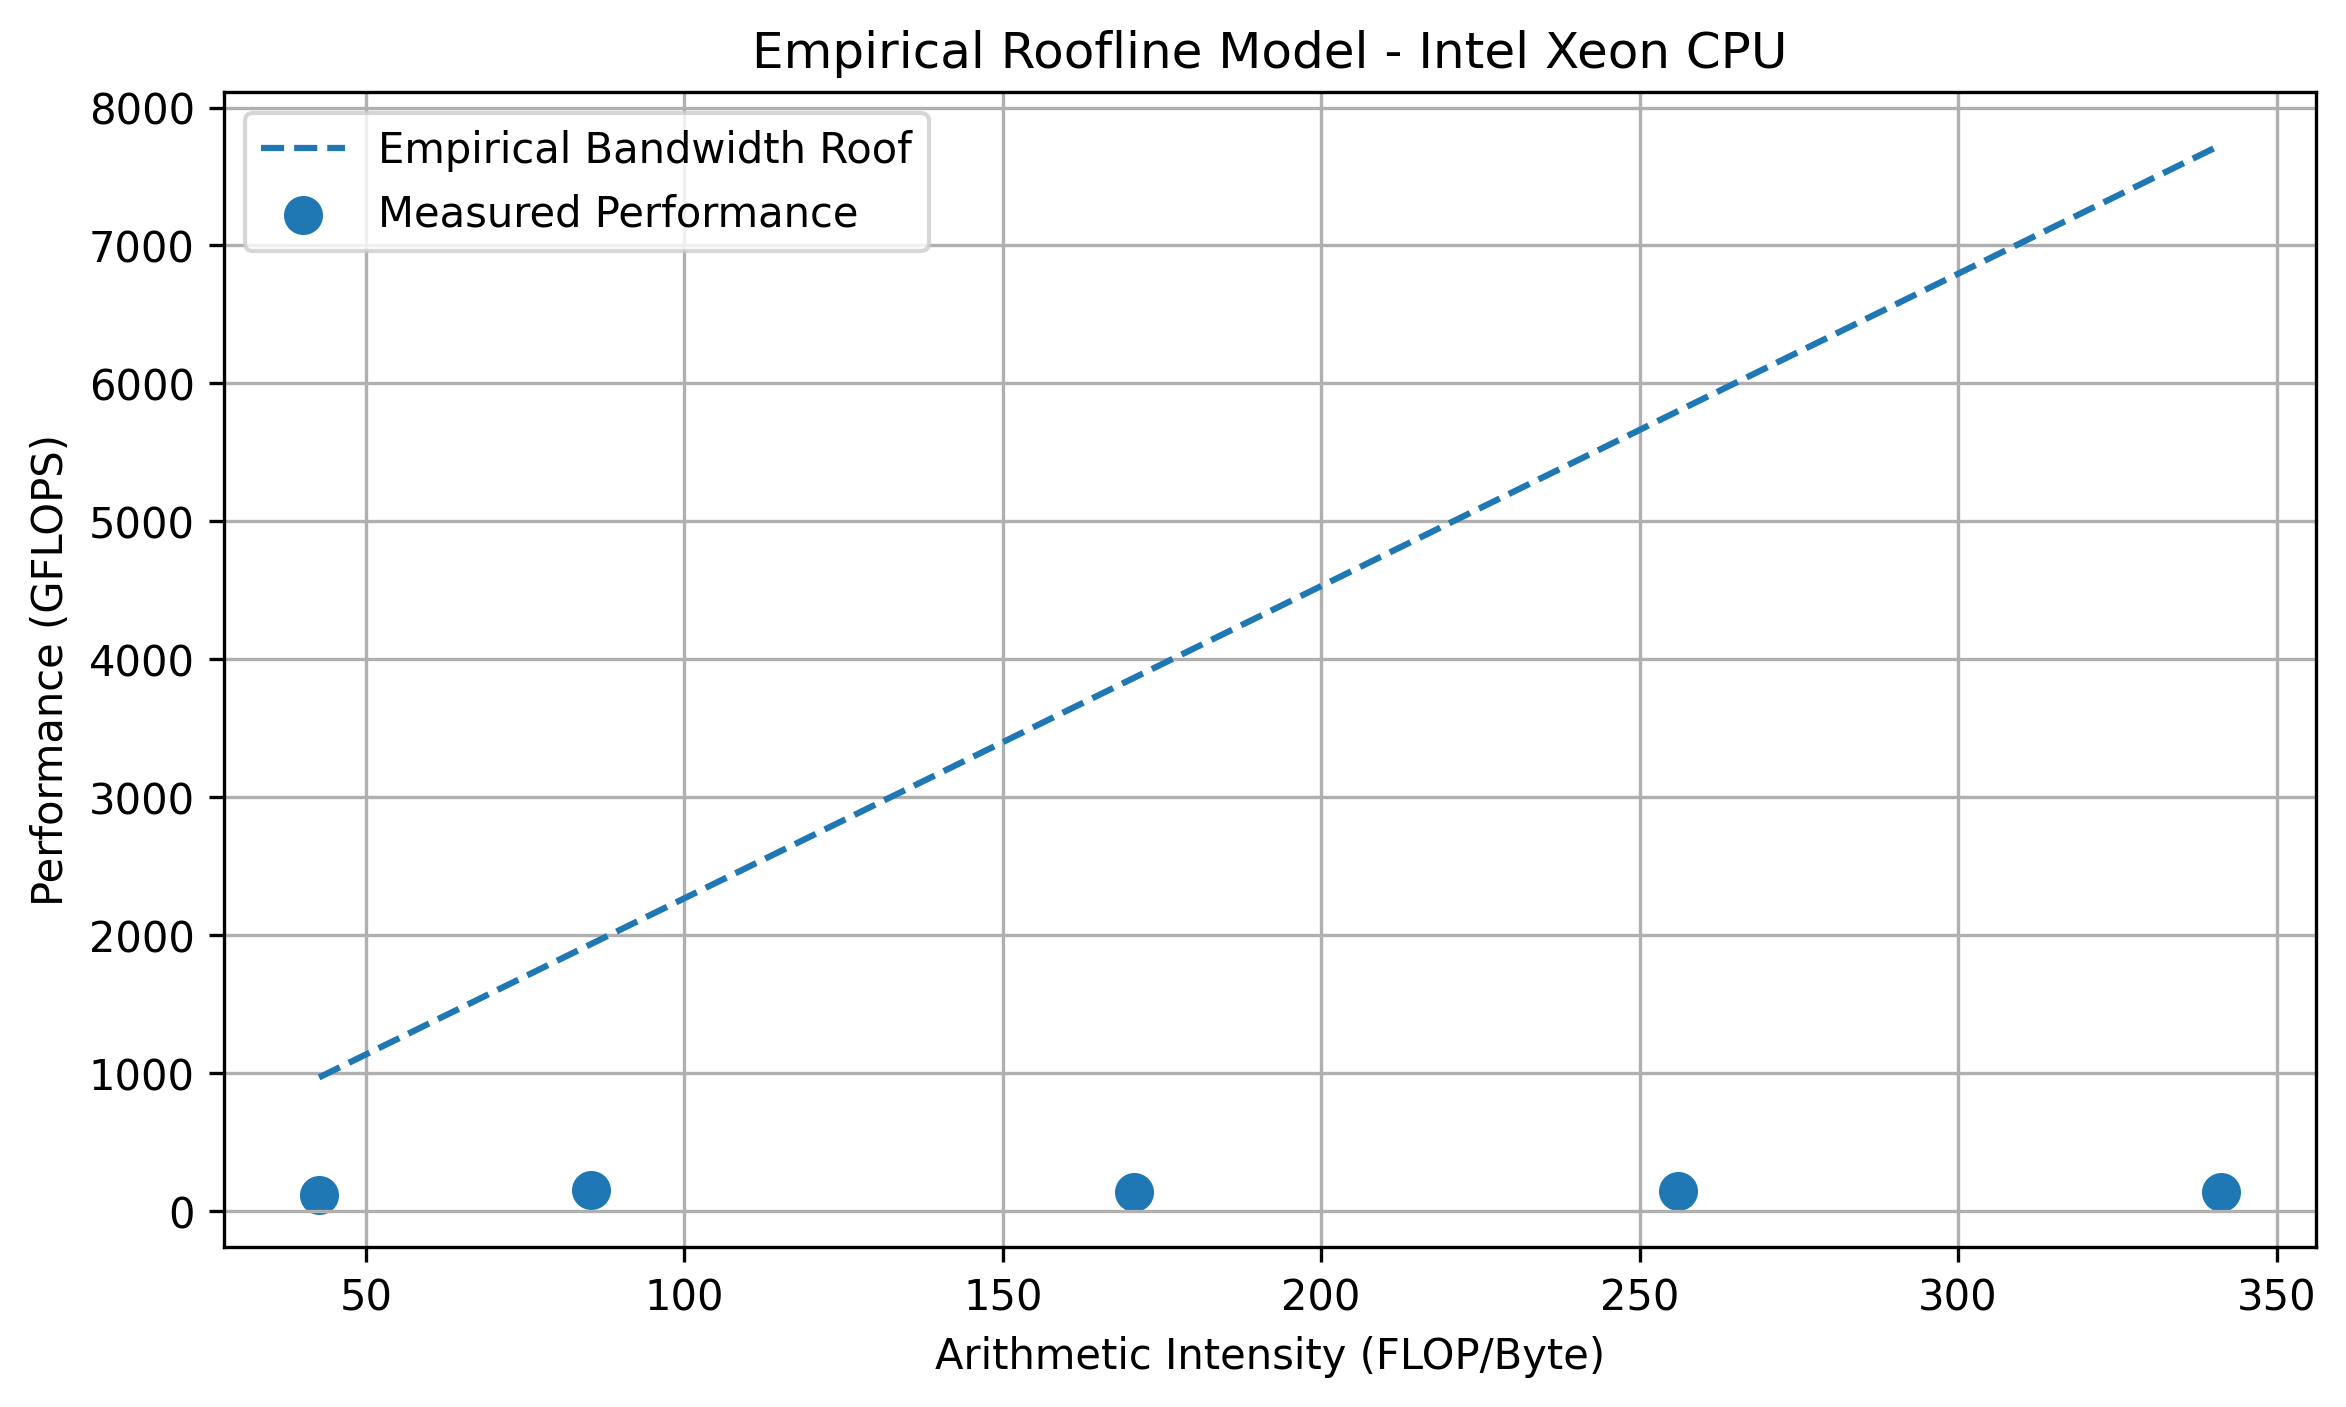


========== nvidia_tesla_t4_roofline.png ==========


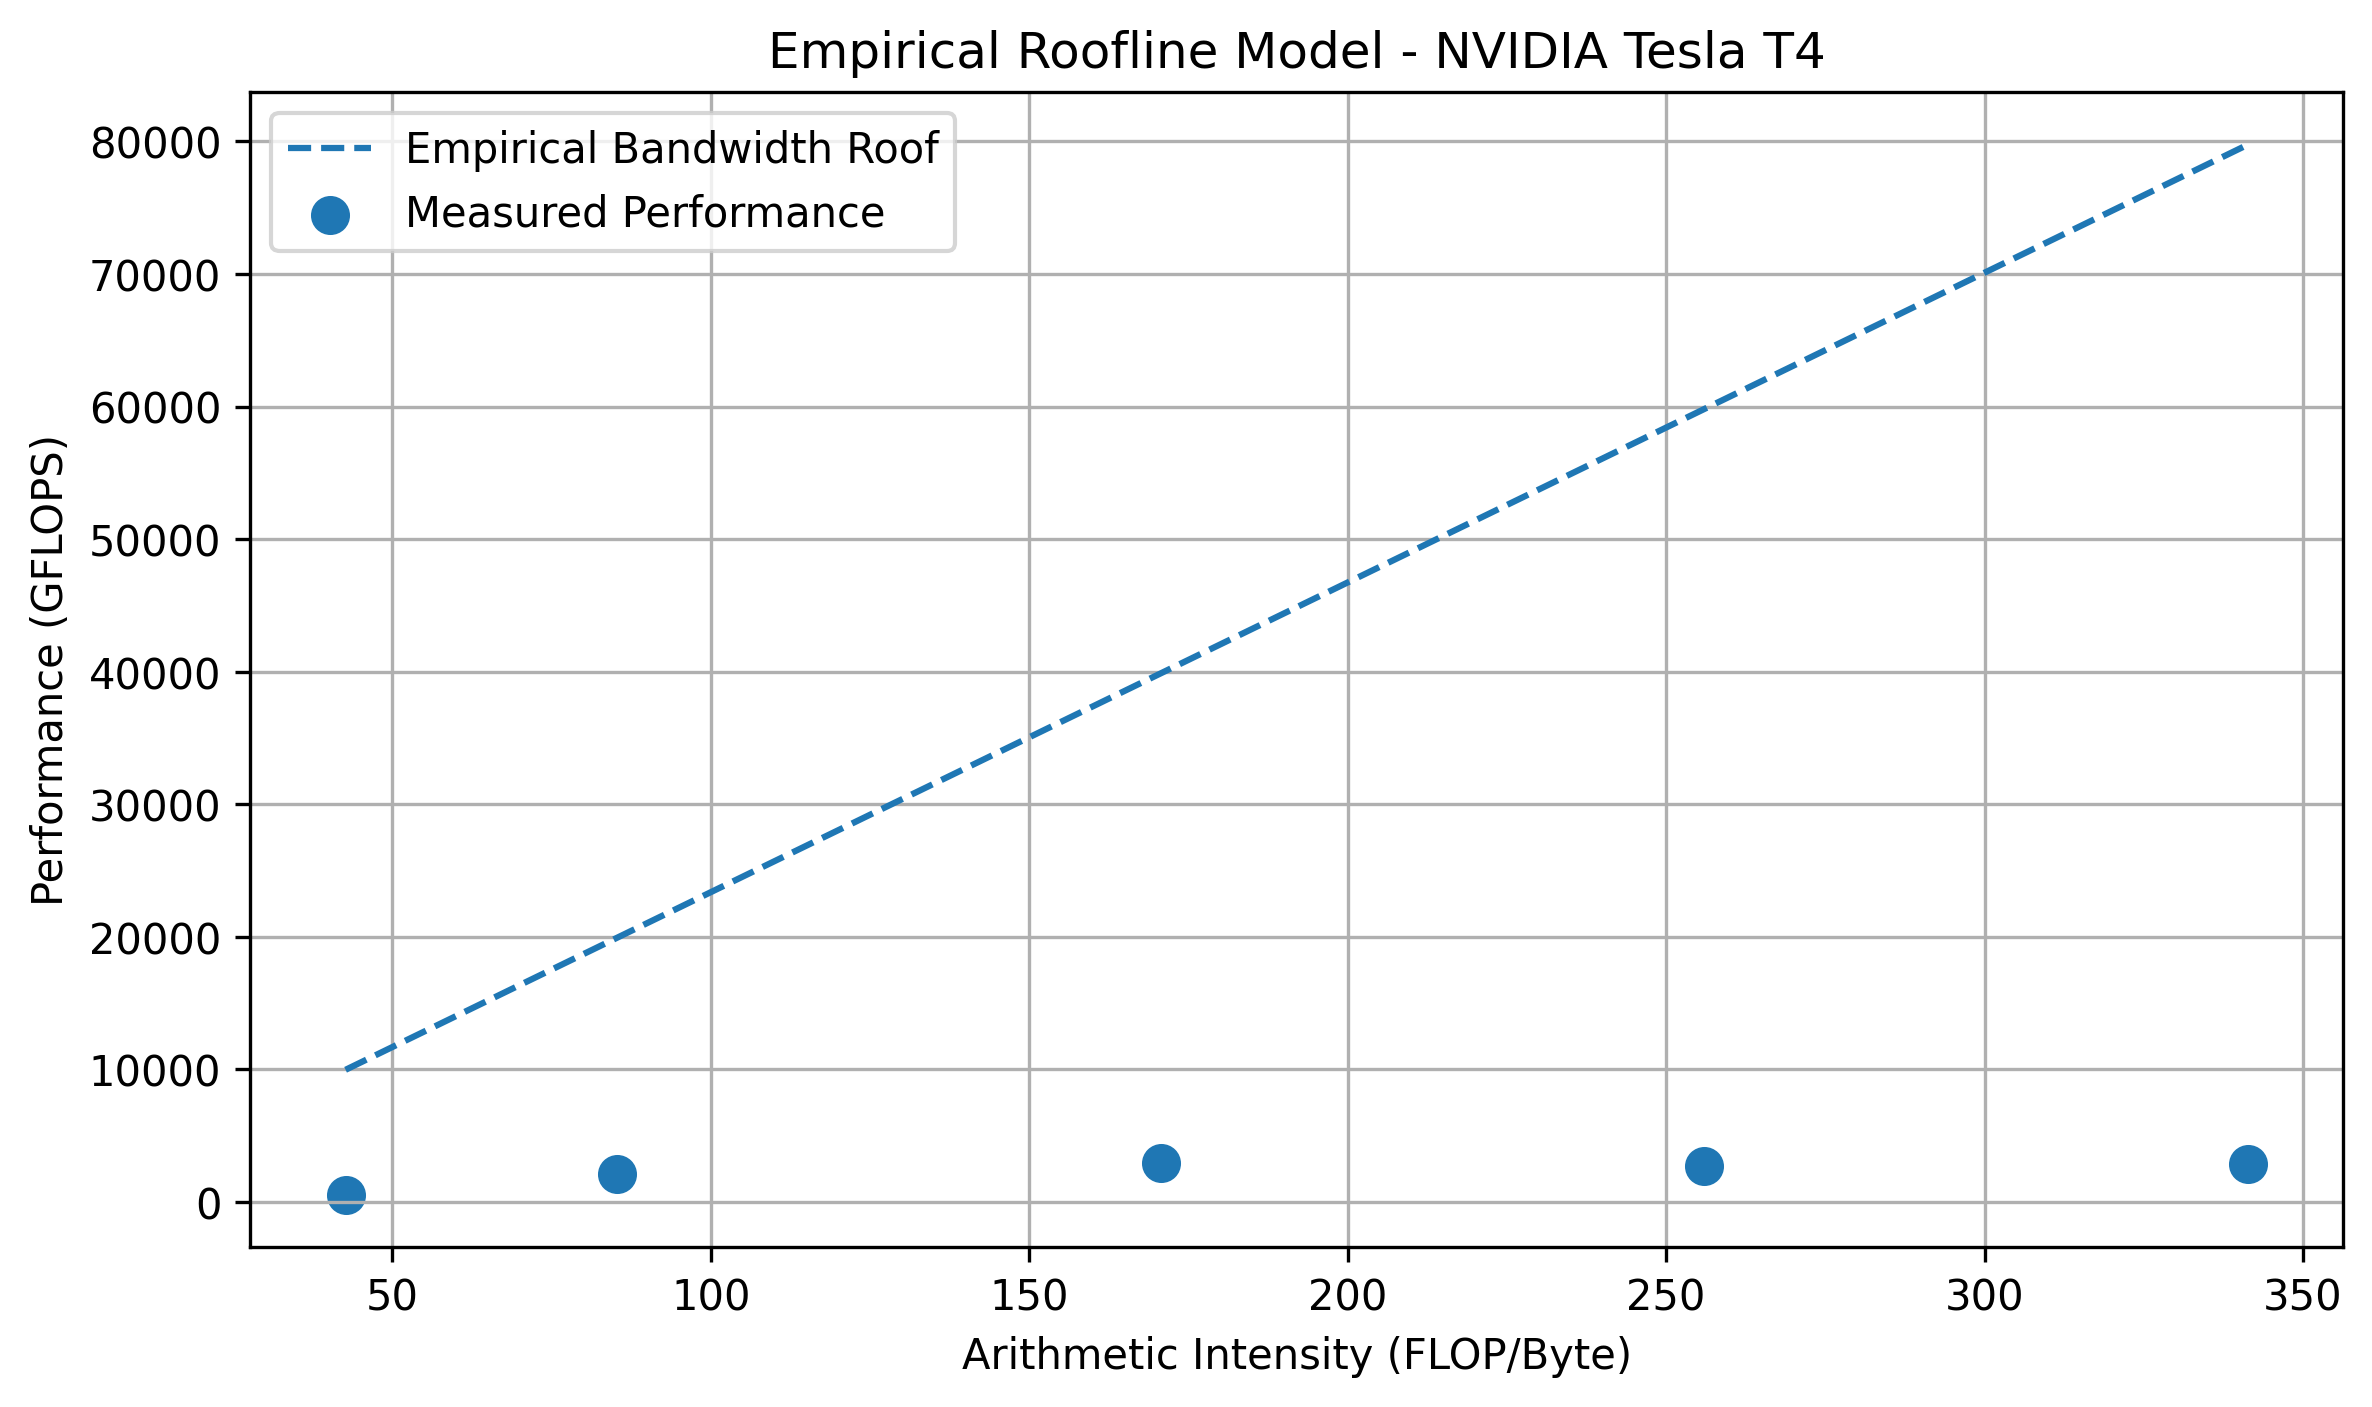


========== google_cloud_tpu_v5e_1_roofline.png ==========


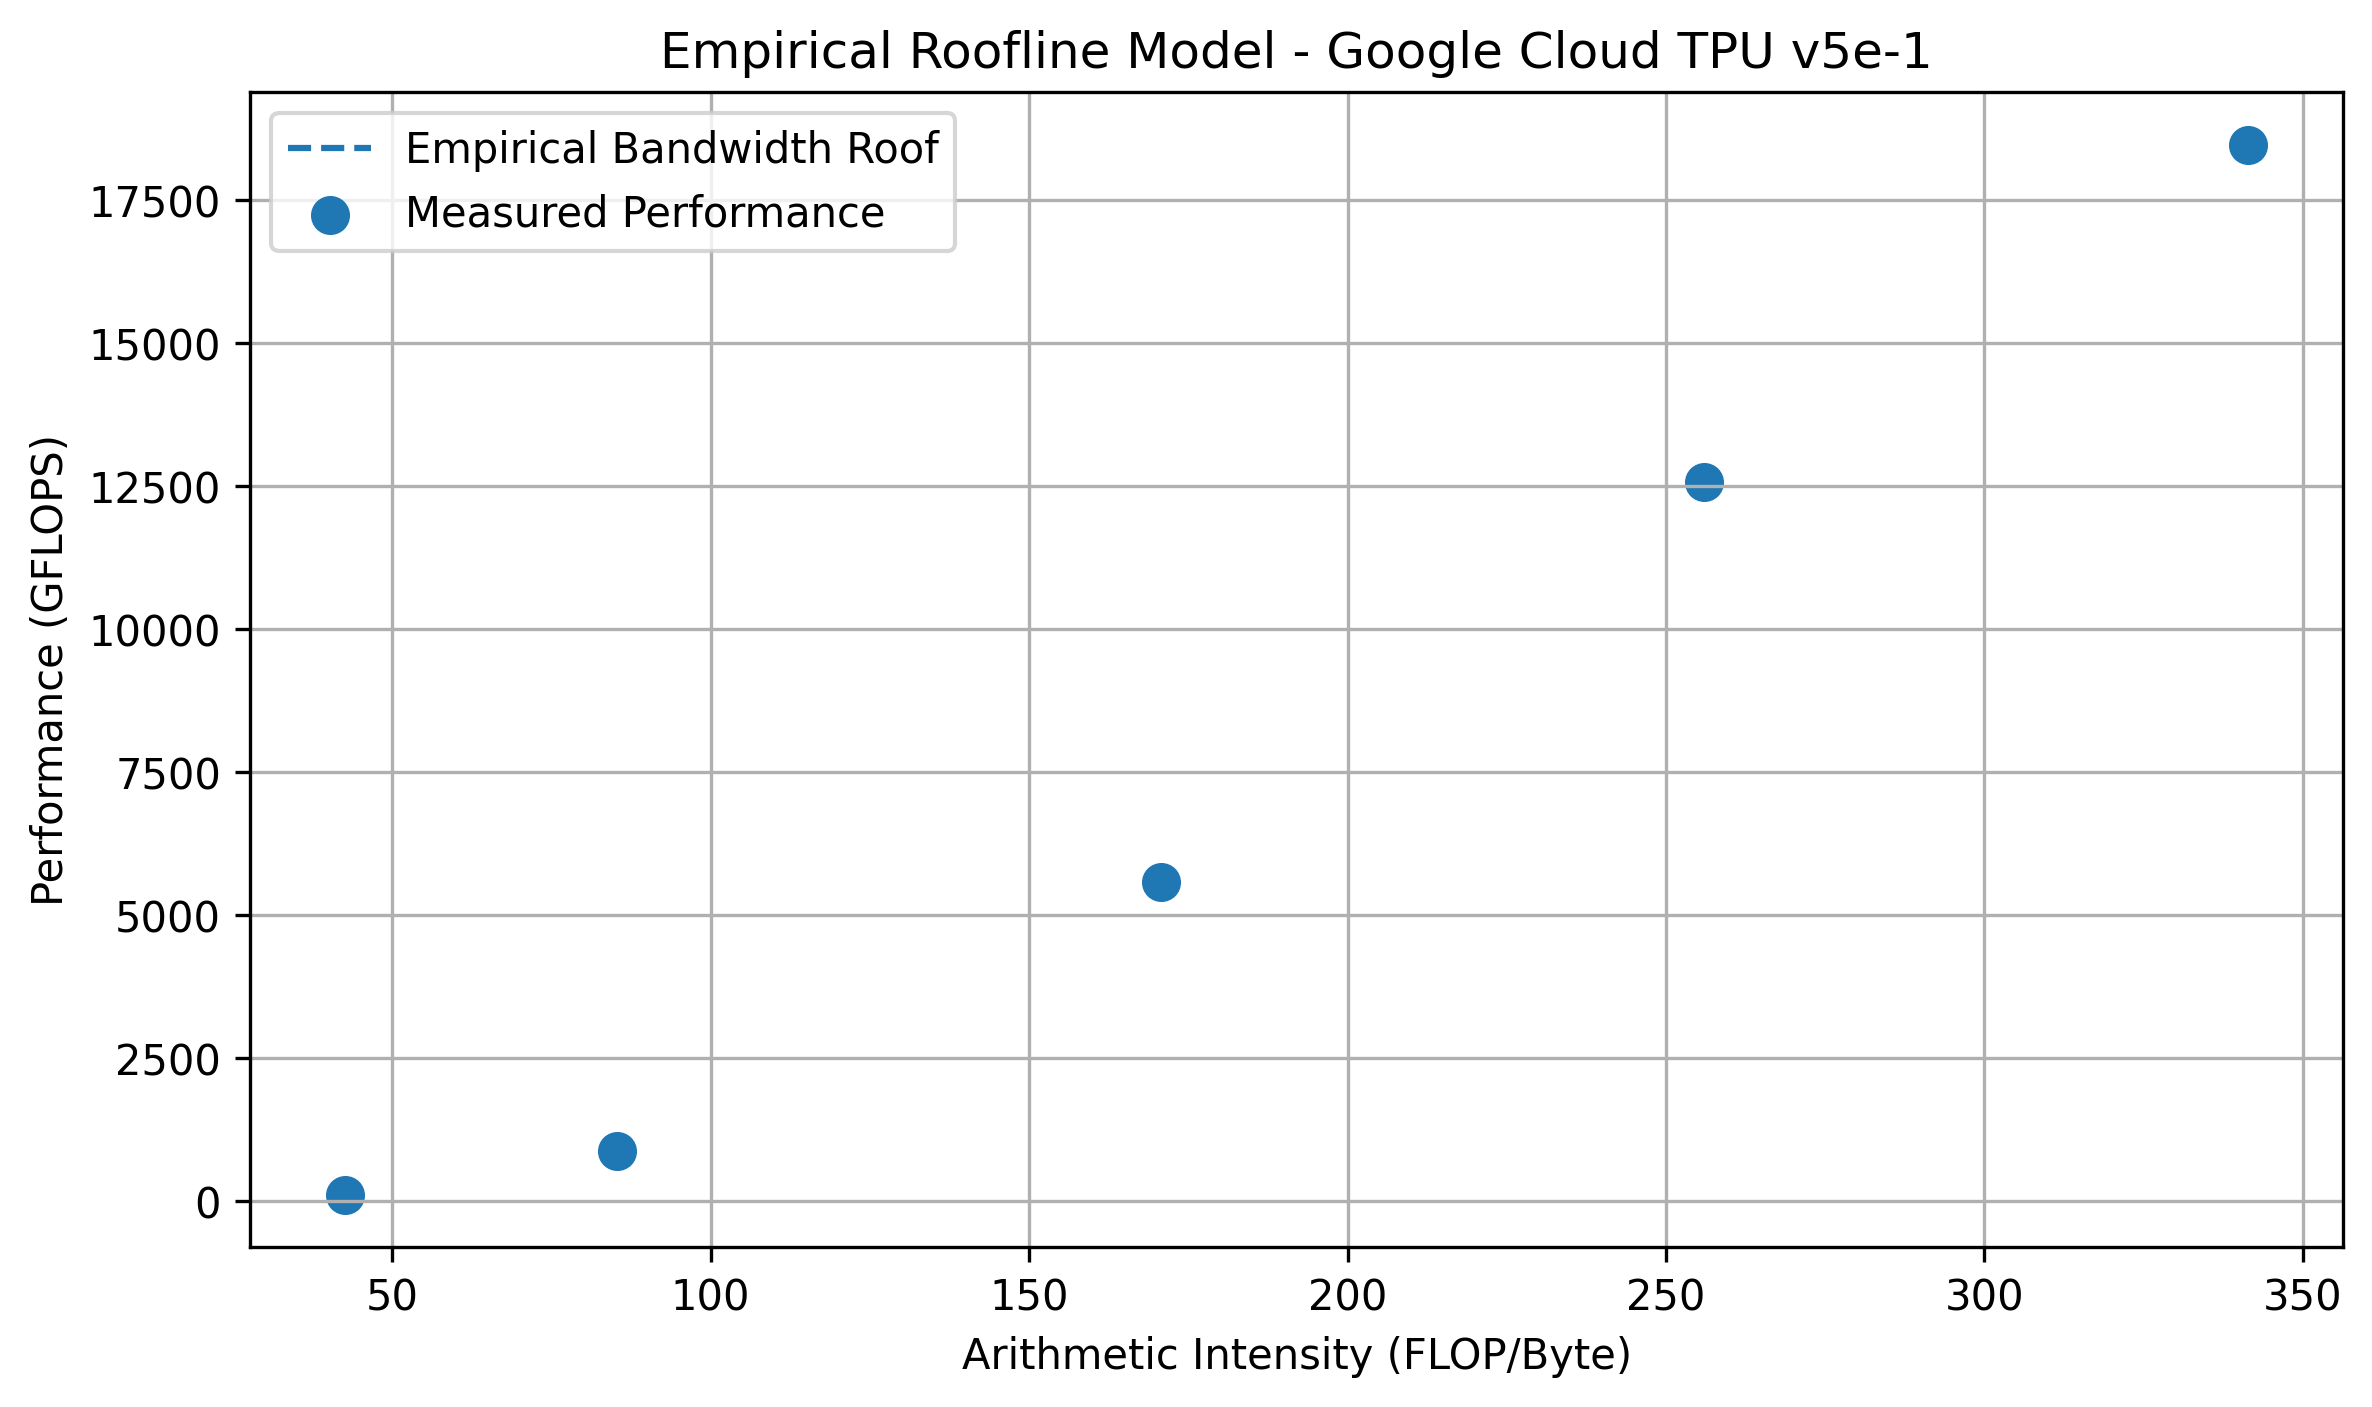

In [ ]:
from PIL import Image
from IPython.display import display

graphs = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Graphs"

files = [
    "intel_xeon_cpu_roofline.png",
    "nvidia_tesla_t4_roofline.png",
    "google_cloud_tpu_v5e_1_roofline.png"
]

for filename in files:
    print("\n==========", filename, "==========")
    display(Image.open(f"{graphs}/{filename}"))

In [ ]:
import os
import json
import pandas as pd

base = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Documentation"

print("========== HARDWARE INVENTORY ==========")

with open(os.path.join(base, "hardware_inventory.json")) as f:
    inventory = json.load(f)

print(json.dumps(inventory, indent=4))

print("\n========== ARCHITECTURE COMPARISON ==========")

path = os.path.join(base, "hardware_architecture_comparison.csv")
df = pd.read_csv(path)

print(df.to_string(index=False))

========== HARDWARE INVENTORY ==========
{
    "project": "Numerical Precision Impact on AI Inference",
    "platform": "Google Colab",
    "CPU": "Intel Xeon CPU @ 2.00GHz (2 logical CPUs)",
    "GPU": "NVIDIA Tesla T4 (15 GB)",
    "TPU": "Google Cloud TPU v5e-1",
    "framework": "PyTorch",
    "GPU_runtime_torch_version": "2.11.0+cu130",
    "TPU_runtime_torch_version": "2.14.1+cpu",
    "NPU": "Not confirmed; instructor discussion pending",
    "record_date": "2026-11-05"
}

========== ARCHITECTURE COMPARISON ==========
                Device Architecture                     Compute_Units   FP32_Peak_TFLOPS Lowest_Precision_Peak                   Memory                           Notes
        Intel Xeon CPU       x86-64          2 logical CPUs available       Not verified          Not verified Virtualized Colab memory           Exact CPU SKU unknown
       NVIDIA Tesla T4       Turing 2560 CUDA cores, 320 Tensor Cores                8.1        INT4: 260 TOPS              16 GB GDD

In [ ]:
import subprocess

print("========== CPU IDENTIFICATION ==========")

result = subprocess.run(
    ["lscpu"],
    capture_output=True,
    text=True
)

print(result.stdout)

print("\n========== CPU MODEL AND FLAGS ==========")

with open("/proc/cpuinfo", "r") as f:
    lines = f.readlines()

for line in lines:
    if any(key in line for key in [
        "model name", "vendor_id", "cpu family",
        "model\t", "flags"
    ]):
        print(line.strip())

========== CPU IDENTIFICATION ==========
Architecture:                            x86_64
CPU op-mode(s):                          32-bit, 64-bit
Address sizes:                           46 bits physical, 48 bits virtual
Byte Order:                              Little Endian
CPU(s):                                  2
On-line CPU(s) list:                     0,1
Vendor ID:                               GenuineIntel
Model name:                              Intel(R) Xeon(R) CPU @ 2.20GHz
CPU family:                              6
Model:                                   79
Thread(s) per core:                      2
Core(s) per socket:                      1
Socket(s):                               1
Stepping:                                0
BogoMIPS:                                4400.43
Flags:                                   fpu vme de pse tsc msr pae mce cx8 apic sep mtrr pge mca cmov pat pse36 clflush mmx fxsr sse sse2 ss ht syscall nx pdpe1gb rdtscp lm constant_tsc rep_good nopl xt

In [ ]:
import subprocess

print("========== CPU TOPOLOGY ==========")

result = subprocess.run(
    ["lscpu", "-e=CPU,CORE,SOCKET,ONLINE"],
    capture_output=True,
    text=True
)
print(result.stdout)

print("\n========== REPORTED CPU FREQUENCIES ==========")

with open("/proc/cpuinfo") as f:
    for line in f:
        if "cpu MHz" in line:
            print(line.strip())

========== CPU TOPOLOGY ==========
CPU CORE SOCKET ONLINE
  0    0      0    yes
  1    0      0    yes


========== REPORTED CPU FREQUENCIES ==========
cpu MHz		: 2200.218
cpu MHz		: 2200.218


In [ ]:
import os
import json
import pandas as pd

base = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison"
docs = os.path.join(base, "Documentation")

# Updated hardware inventory
inventory_path = os.path.join(docs, "hardware_inventory.json")

with open(inventory_path, "r") as f:
    inventory = json.load(f)

inventory["CPU"] = (
    "Intel Xeon, family 6 model 79 (Broadwell generation), "
    "2 logical CPUs, 1 reported core, 2.20 GHz reported"
)

inventory["CPU_FP32_peak"] = (
    "70.4 GFLOPS conditional theoretical estimate; "
    "not a verified vendor peak"
)

inventory["NPU"] = "Not available/verified; no NPU benchmark performed"

with open(inventory_path, "w") as f:
    json.dump(inventory, f, indent=4)

# Audited comparison table
data = [
    {
        "Device": "Intel Xeon CPU",
        "Architecture": "Broadwell generation (family 6, model 79)",
        "Compute_Units": "1 reported core, 2 logical CPUs",
        "FP32_Peak": "70.4 GFLOPS (conditional estimate)",
        "Reduced_Precision": "Not verified",
        "Memory": "Virtualized Colab memory",
        "Memory_Bandwidth_Peak": "Not verified",
        "Notes": "Exact physical SKU unknown; KVM virtualized"
    },
    {
        "Device": "NVIDIA Tesla T4",
        "Architecture": "Turing",
        "Compute_Units": "2560 CUDA cores, 320 Tensor Cores",
        "FP32_Peak": "8.1 TFLOPS",
        "Reduced_Precision": "FP16 65 TFLOPS; INT8 130 TOPS; INT4 260 TOPS",
        "Memory": "16 GB GDDR6",
        "Memory_Bandwidth_Peak": "300 GB/s",
        "Notes": "Vendor theoretical specifications"
    },
    {
        "Device": "Google Cloud TPU v5e-1",
        "Architecture": "TPU v5e",
        "Compute_Units": "1 TensorCore, 4 MXUs",
        "FP32_Peak": "Not specified",
        "Reduced_Precision": "BF16 197 TFLOPS; INT8 393 TOPS",
        "Memory": "16 GB HBM",
        "Memory_Bandwidth_Peak": "800 GiB/s",
        "Notes": "Per-chip vendor specifications"
    }
]

df = pd.DataFrame(data)

output = os.path.join(
    docs,
    "hardware_architecture_comparison_audited.csv"
)

df.to_csv(output, index=False)

print("Hardware inventory updated.")
print("Audited comparison saved:")
print(output)

print("\n========== AUDITED TABLE ==========")
print(df.to_string(index=False))

Hardware inventory updated.
Audited comparison saved:
/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Documentation/hardware_architecture_comparison_audited.csv

========== AUDITED TABLE ==========
                Device                              Architecture                     Compute_Units                          FP32_Peak                            Reduced_Precision                   Memory Memory_Bandwidth_Peak                                       Notes
        Intel Xeon CPU Broadwell generation (family 6, model 79)   1 reported core, 2 logical CPUs 70.4 GFLOPS (conditional estimate)                                 Not verified Virtualized Colab memory          Not verified Exact physical SKU unknown; KVM virtualized
       NVIDIA Tesla T4                                    Turing 2560 CUDA cores, 320 Tensor Cores                         8.1 TFLOPS FP16 65 TFLOPS; INT8 130 TOPS; INT4 260 TOPS              16 GB GDDR6              300 GB/s           Vendor theoretic

In [ ]:
import os

base = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison"

for folder in ["Documentation", "Code"]:
    path = os.path.join(base, folder)

    print("\n==========", folder, "==========")

    for item in sorted(os.listdir(path)):
        full_path = os.path.join(path, item)

        if os.path.isfile(full_path):
            print("FILE:", item)
        else:
            print("FOLDER:", item)


========== Documentation ==========
FILE: cpu_iron_law_limitations.txt
FILE: hardware_architecture_comparison.csv
FILE: hardware_architecture_comparison_audited.csv
FILE: hardware_inventory.json

========== Code ==========


In [ ]:
import os

base = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison"
docs = os.path.join(base, "Documentation")

content = """
RESEARCH QUESTION

How do numerical precision formats and hardware architectures
affect the performance and numerical accuracy of AI workloads
across CPU, GPU, and TPU platforms?

HYPOTHESIS

Reduced numerical precision will generally improve computational
performance on hardware with specialized accelerator units,
but the performance improvement and numerical error will vary
across hardware architectures and workloads.

RESEARCH SCOPE

Hardware: Intel Xeon CPU, NVIDIA Tesla T4 GPU, Google Cloud TPU v5e-1.

Workloads: Matrix multiplication, ResNet-50, DistilBERT,
LSTM, and FashionMNIST CNN training.

Evaluation metrics: Latency, throughput, GFLOPS, numerical error,
RMSE, memory bandwidth, and transfer overhead.

DOCUMENTATION NOTE

The research question and hypothesis were formalized after
the experiments. They are not represented as pre-experiment
documentation.
"""

path = os.path.join(docs, "research_question_hypothesis.txt")

with open(path, "w") as f:
    f.write(content)

print("Research question and hypothesis saved!")
print(path)

Research question and hypothesis saved!
/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Documentation/research_question_hypothesis.txt


In [ ]:
import os
import pandas as pd

raw = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV"

print("========== TPU INFERENCE FILE SEARCH ==========")

for filename in sorted(os.listdir(raw)):
    if "tpu" in filename.lower():
        print(filename)

print("\n========== EXPERIMENT LOG ==========")

path = os.path.join(raw, "experiment_log.csv")

if os.path.exists(path):
    df = pd.read_csv(path)
    print("Rows:", len(df))
    print(df.to_string(index=False))
else:
    print("Experiment log not found.")

========== TPU INFERENCE FILE SEARCH ==========
matrix_multiplication_tpu_validated.csv
memory_bandwidth_tpu.csv
tpu_precision_comparison.csv
tpu_precision_timing_validation.csv

========== EXPERIMENT LOG ==========
Rows: 0
Empty DataFrame
Columns: [Experiment, Device, Matrix_Size, Precision, Repetition, Runtime_Seconds, FLOPS, Notes]
Index: []


In [ ]:
keywords = [
    "resnet50",
    "distilbert",
    "lstm"
]

print("========== INFERENCE CODE CELL INDEX ==========")

for i, code in enumerate(In):
    if not code.strip():
        continue

    code_lower = code.lower()

    if any(word in code_lower for word in keywords):
        if any(word in code_lower for word in [
            "median", "warmup", "warm_up",
            "synchronize", "perf_counter",
            "time.time", "repetitions", "inference"
        ]):
            print(f"\nCell index: {i}")
            print(code[:1200])
            print("-" * 60)

========== INFERENCE CODE CELL INDEX ==========

Cell index: 3
import os
import pandas as pd

raw = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV"

files = [
    "matrix_multiplication_cpu_gpu.csv",
    "gpu_precision_comparison.csv",
    "memory_bandwidth_cpu.csv",
    "memory_bandwidth_gpu.csv",
    "memory_bandwidth_tpu.csv",
    "resnet50_cpu_gpu_fair_comparison.csv",
    "experiment_log.csv"
]

for filename in files:
    path = os.path.join(raw, filename)

    print("\n" + "="*60)
    print(filename)

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Columns:", list(df.columns))
        print(df.head(3).to_string(index=False))
    else:
        print("FILE NOT FOUND")
------------------------------------------------------------

Cell index: 10
import os

project = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison"

raw = os.path.join(project, "Results/Raw_CSV")
graphs = os.path.join(project, "Results/Graphs")

expected

In [ ]:
keywords = ["resnet50", "distilbert", "lstm"]

print("========== ORIGINAL INFERENCE CELLS ==========")

for i, code in enumerate(In):
    if not code.strip():
        continue

    lower = code.lower()

    if any(k in lower for k in keywords):
        print(f"\n\n{'='*25} CELL {i} {'='*25}")
        print(code)

========== ORIGINAL INFERENCE CELLS ==========


========================= CELL 3 =========================
import os
import pandas as pd

raw = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV"

files = [
    "matrix_multiplication_cpu_gpu.csv",
    "gpu_precision_comparison.csv",
    "memory_bandwidth_cpu.csv",
    "memory_bandwidth_gpu.csv",
    "memory_bandwidth_tpu.csv",
    "resnet50_cpu_gpu_fair_comparison.csv",
    "experiment_log.csv"
]

for filename in files:
    path = os.path.join(raw, filename)

    print("\n" + "="*60)
    print(filename)

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Columns:", list(df.columns))
        print(df.head(3).to_string(index=False))
    else:
        print("FILE NOT FOUND")


========================= CELL 10 =========================
import os

project = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison"

raw = os.path.join(project, "Results/Raw_CSV")
graphs = os.path.join(projec

In [ ]:
import os

from google.colab import drive
drive.mount('/content/gdrive')

base = "/content/gdrive/MyDrive"

print("========== SAVED NOTEBOOKS ==========")

for root, dirs, files in os.walk(base):
    dirs[:] = [d for d in dirs if d not in [
        ".ipynb_checkpoints", "node_modules"
    ]]

    for filename in files:
        if filename.endswith(".ipynb") and (
            "inference" in filename.lower()
            or "precision" in filename.lower()
            or "architecture" in filename.lower()
        ):
            print(os.path.join(root, filename))

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).
========== SAVED NOTEBOOKS ==========


In [ ]:
import os

project = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison"

print("========== PROJECT FOLDER ==========")

for root, dirs, files in os.walk(project):
    level = root.replace(project, "").count(os.sep)
    indent = "  " * level

    print(f"{indent}{os.path.basename(root)}/")

    for filename in files:
        print(f"{indent}  {filename}")

========== PROJECT FOLDER ==========
AI_Inference_Precision_Comparison/
  Code/
  Raw_Results/
  CSV_Data/
  Graphs/
  Research_Paper/
  Documentation/
    hardware_inventory.json
    cpu_iron_law_limitations.txt
    hardware_architecture_comparison.csv
    hardware_architecture_comparison_audited.csv
    research_question_hypothesis.txt
  Results/
    Raw_CSV/
      experiment_log.csv
      matrix_multiplication_cpu_gpu.csv
      memory_bandwidth_gpu.csv
      memory_bandwidth_cpu.csv
      memory_bandwidth_tpu.csv
      combined_memory_bandwidth.csv
      gpu_precision_comparison.csv
      resnet50_gpu_inference.csv
      resnet50_cpu_inference.csv
      combined_resnet50_inference.csv
      resnet50_gpu_wall_timing.csv
      resnet50_cpu_gpu_fair_comparison.csv
      distilbert_gpu_inference.csv
      distilbert_cpu_inference.csv
      combined_distilbert_inference.csv
      lstm_cpu_inference.csv
      lstm_gpu_inference.csv
      combined_lstm_inference.csv
      roofline_input_da

In [ ]:
import os

base = "/content/gdrive/MyDrive"

print("========== ALL NOTEBOOK FILES ==========")

count = 0

for root, dirs, files in os.walk(base):
    dirs[:] = [d for d in dirs if d != ".ipynb_checkpoints"]

    for filename in files:
        if filename.endswith(".ipynb"):
            count += 1
            print(os.path.join(root, filename))

print("\nTotal notebooks found:", count)

========== ALL NOTEBOOK FILES ==========
/content/gdrive/MyDrive/Classroom/Artificial Intelligence BCS-4C/24f-0583_section C.ipynb
/content/gdrive/MyDrive/Classroom/Artificial Intelligence BCS-4C/notebooks_24F-0583 AI ASS05.ipynb
/content/gdrive/MyDrive/Classroom/AI-Lab 4F/AI LAB3.ipynb
/content/gdrive/MyDrive/Classroom/AI-Lab 4F/AI LAB 24F-0583.ipynb
/content/gdrive/MyDrive/Classroom/AI-Lab 4F/24F-0583 AI LAB 5.ipynb
/content/gdrive/MyDrive/Classroom/AI-Lab 4F/LAB8_24F-0583_.ipynb
/content/gdrive/MyDrive/Classroom/AI-Lab 4F/LAB 9_24F-0583_.ipynb
/content/gdrive/MyDrive/Classroom/AI-Lab 4F/LAB10_24F-0583_ (2).ipynb
/content/gdrive/MyDrive/Classroom/AI-Lab 4F/f240583-lab#12.ipynb
/content/gdrive/MyDrive/Classroom/AI-Lab 4F/AILAB_24f-0583.ipynb
/content/gdrive/MyDrive/Colab Notebooks/Untitled0.ipynb
/content/gdrive/MyDrive/Colab Notebooks/Untitled1.ipynb

Total notebooks found: 12


In [ ]:
import json
import os

paths = [
    "/content/gdrive/MyDrive/Colab Notebooks/Untitled0.ipynb",
    "/content/gdrive/MyDrive/Colab Notebooks/Untitled1.ipynb"
]

for path in paths:
    print("\n" + "=" * 60)
    print("NOTEBOOK:", os.path.basename(path))

    with open(path, "r", encoding="utf-8") as f:
        notebook = json.load(f)

    cells = notebook.get("cells", [])
    print("Total cells:", len(cells))

    for i, cell in enumerate(cells):
        source = "".join(cell.get("source", []))
        lower = source.lower()

        if any(k in lower for k in [
            "resnet50", "distilbert", "lstm",
            "tesla t4", "tpu", "matrix_multiplication"
        ]):
            print(f"\nMatching cell {i}:")
            print(source[:350])


NOTEBOOK: Untitled0.ipynb
Total cells: 1

NOTEBOOK: Untitled1.ipynb
Total cells: 1


In [ ]:
import os

base = "/content/gdrive/MyDrive"

for root, dirs, files in os.walk(base):
    for filename in files:
        if "AI_Inference_Precision_Comparison" in filename:
            print(os.path.join(root, filename))

/content/gdrive/MyDrive/Colab Notebooks/AI_Inference_Precision_Comparison


In [ ]:
import json

path = "/content/gdrive/MyDrive/Colab Notebooks/AI_Inference_Precision_Comparison"

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

cells = nb.get("cells", [])

print("Total notebook cells:", len(cells))
print("Code cells:", sum(c.get("cell_type") == "code" for c in cells))
print("Markdown cells:", sum(c.get("cell_type") == "markdown" for c in cells))

for i, cell in enumerate(cells):
    source = "".join(cell.get("source", []))
    lower = source.lower()

    if any(k in lower for k in ["resnet50", "distilbert", "lstm"]):
        print(f"\n{'='*20} CELL {i} {'='*20}")
        print(source)

Total notebook cells: 182
Code cells: 182
Markdown cells: 0

==================== CELL 78 ====================
import torch
from torchvision.models import resnet50, ResNet50_Weights

# Load pretrained ResNet-50
weights = ResNet50_Weights.DEFAULT
model = resnet50(weights=weights)

# Evaluation mode
model.eval()
model = model.to("cuda")

print("Model: ResNet-50")
print("Weights: ImageNet pretrained")
print("Device:", next(model.parameters()).device)
print("Total parameters:", sum(p.numel() for p in model.parameters()))
print("Model loaded successfully!")

==================== CELL 80 ====================
import time
import numpy as np
import pandas as pd
import torch
import os

model.eval()
results = []

for batch in batch_sizes:

    x = inputs[batch]

    # Warm-up
    with torch.inference_mode():
        for _ in range(3):
            _ = model(x)

    torch.cuda.synchronize()

    timings = []

    # 10 measured repetitions
    with torch.inference_mode():
        for _ in range(10):

In [ ]:
import json
import os
from datetime import datetime

notebook_path = "/content/gdrive/MyDrive/Colab Notebooks/AI_Inference_Precision_Comparison"
csv_path = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/lstm_cpu_inference.csv"

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

print("========== LSTM CELL EXECUTION HISTORY ==========")

for i in [102, 105, 106, 107, 108, 109, 110]:
    cell = nb["cells"][i]
    print(
        "Cell:", i,
        "| Execution count:", cell.get("execution_count"),
        "| Has output:", bool(cell.get("outputs"))
    )

print("\n========== SAVED CPU CSV ==========")

if os.path.exists(csv_path):
    print("File:", csv_path)
    print("Last modified:", datetime.fromtimestamp(
        os.path.getmtime(csv_path)
    ))
else:
    print("CSV not found")

========== LSTM CELL EXECUTION HISTORY ==========
Cell: 102 | Execution count: 54 | Has output: True
Cell: 105 | Execution count: 58 | Has output: True
Cell: 106 | Execution count: 59 | Has output: True
Cell: 107 | Execution count: 60 | Has output: True
Cell: 108 | Execution count: 61 | Has output: True
Cell: 109 | Execution count: 62 | Has output: True
Cell: 110 | Execution count: 63 | Has output: True

========== SAVED CPU CSV ==========
File: /content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/lstm_cpu_inference.csv
Last modified: 2026-11-05 17:05:02


In [ ]:
import json
import pandas as pd
import os

notebook_path = "/content/gdrive/MyDrive/Colab Notebooks/AI_Inference_Precision_Comparison"
raw = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV"

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

for i in [107, 108, 109, 110]:
    cell = nb["cells"][i]
    print("\n========== CELL", i, "==========")

    for output in cell.get("outputs", []):
        data = output.get("data", {})
        if "text/plain" in data:
            print("".join(data["text/plain"])[:2500])

        if "text" in output:
            print("".join(output["text"])[:1500])

for filename in ["lstm_cpu_inference.csv", "lstm_gpu_inference.csv"]:
    path = os.path.join(raw, filename)
    print("\n==========", filename, "==========")
    if os.path.exists(path):
        print(pd.read_csv(path).to_string(index=False))


========== CELL 107 ==========
Batch 1: Median = 6.016 ms | Std Dev = 8.014 ms
Batch 2: Median = 6.182 ms | Std Dev = 1.680 ms
Batch 4: Median = 7.474 ms | Std Dev = 2.063 ms
Batch 8: Median = 10.169 ms | Std Dev = 1.691 ms

           Device Model  Batch_Size  Sequence_Length  Median_Latency_ms  \
0  Intel Xeon CPU  LSTM           1              100           6.015522   
1  Intel Xeon CPU  LSTM           2              100           6.181630   
2  Intel Xeon CPU  LSTM           4              100           7.474275   
3  Intel Xeon CPU  LSTM           8              100          10.168667   

   Mean_Latency_ms  Std_Dev_ms  Throughput_Sequences_Per_Second  
0         8.819924    8.013971                       166.236601  
1         7.135668    1.679694                       323.539261  
2         8.732724    2.062917                       535.168927  
3        10.928267    1.690773                       786.730492  

========== CELL 108 ==========
LSTM CPU results saved successfully!

In [ ]:
import json
import os

notebook_path = "/content/gdrive/MyDrive/Colab Notebooks/AI_Inference_Precision_Comparison"

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

for i in [78, 80, 82, 84, 85, 90, 92, 94, 95, 97]:
    cell = nb["cells"][i]

    print("\n========== CELL", i, "==========")
    print("Execution count:", cell.get("execution_count"))

    for output in cell.get("outputs", []):
        if "text" in output:
            print("".join(output["text"])[:1200])

        data = output.get("data", {})
        if "text/plain" in data:
            print("".join(data["text/plain"])[:1800])


========== CELL 78 ==========
Execution count: 28
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth

100%|██████████| 97.8M/97.8M [00:00<00:00, 191MB/s]

Model: ResNet-50
Weights: ImageNet pretrained
Device: cuda:0
Total parameters: 25557032
Model loaded successfully!


========== CELL 80 ==========
Execution count: 30
            Device      Model  Batch_Size  Median_Latency_ms  Mean_Latency_ms  \
0  NVIDIA Tesla T4  ResNet-50           1          17.615264        19.931933   
1  NVIDIA Tesla T4  ResNet-50           2          18.827872        19.954640   
2  NVIDIA Tesla T4  ResNet-50           4          28.092064        25.949350   
3  NVIDIA Tesla T4  ResNet-50           8          27.884384        28.776448   
4  NVIDIA Tesla T4  ResNet-50          16          48.689104        48.731482   
5  NVIDIA Tesla T4  ResNet-50          32          94.543934        94.482994   

   Std_Dev_ms  Throughput_I

In [ ]:
import json

notebook_path = "/content/gdrive/MyDrive/Colab Notebooks/AI_Inference_Precision_Comparison"

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

keywords = [
    "FashionMNIST",
    "fashion_mnist",
    "train_loader",
    "test_loader",
    "Epoch",
    "cnn_cpu_training",
    "cnn_gpu_training"
]

print("========== CNN TRAINING CELL SEARCH ==========")

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))

    if any(word.lower() in source.lower() for word in keywords):
        print("\nCELL:", i)
        print("Execution count:", cell.get("execution_count"))
        print("SOURCE:")
        print(source[:1800])

        for output in cell.get("outputs", []):
            if "text" in output:
                print("OUTPUT:")
                print("".join(output["text"])[:1200])

========== CNN TRAINING CELL SEARCH ==========

CELL: 120
Execution count: 75
SOURCE:
from torchvision import datasets, transforms

dataset_path = os.path.join(project, "Dataset")

os.makedirs(dataset_path, exist_ok=True)

transform = transforms.ToTensor()

train_dataset = datasets.FashionMNIST(
    root=dataset_path,
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root=dataset_path,
    train=False,
    download=True,
    transform=transform
)

print("Dataset downloaded successfully!")
print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Image shape:", train_dataset[0][0].shape)
print("Number of classes:", len(train_dataset.classes))
print("Classes:", train_dataset.classes)
OUTPUT:
100%|██████████| 26.4M/26.4M [00:01<00:00, 18.6MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 14.7MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.62MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 26.2MB

In [ ]:
import json

path = "/content/gdrive/MyDrive/Colab Notebooks/AI_Inference_Precision_Comparison"

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))

    if (
        "fashion_mnist" in source.lower()
        or "fashionmnist" in source.lower()
        or "cnn_model" in source.lower()
    ):
        print("\nCELL:", i)
        print("Execution count:", cell.get("execution_count"))
        print(source[:2500])


CELL: 120
Execution count: 75
from torchvision import datasets, transforms

dataset_path = os.path.join(project, "Dataset")

os.makedirs(dataset_path, exist_ok=True)

transform = transforms.ToTensor()

train_dataset = datasets.FashionMNIST(
    root=dataset_path,
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root=dataset_path,
    train=False,
    download=True,
    transform=transform
)

print("Dataset downloaded successfully!")
print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Image shape:", train_dataset[0][0].shape)
print("Number of classes:", len(train_dataset.classes))
print("Classes:", train_dataset.classes)

CELL: 171
Execution count: 31
import os

base = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison"
docs = os.path.join(base, "Documentation")

content = """
RESEARCH QUESTION

How do numerical precision formats and hardware architectures
affect the performance 

In [ ]:
import json

path = "/content/gdrive/MyDrive/Colab Notebooks/AI_Inference_Precision_Comparison"

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

keywords = [
    "optimizer",
    "CrossEntropyLoss",
    "backward()",
    "optimizer.step",
    "train_loader",
    "model.train()",
    "Training_Time_sec",
    "cnn_cpu",
    "cnn_gpu"
]

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))

    if any(k.lower() in source.lower() for k in keywords):
        print("\nCELL:", i)
        print("Execution:", cell.get("execution_count"))
        print(source[:2200])


CELL: 121
Execution: 76
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import copy
import numpy as np
import time

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# CNN architecture
class FashionCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


# Training configuration
BATCH_SIZE = 128
EPOCHS = 2
LEARNING_RATE = 0.001

# Data loaders
train_loader = DataLoader(
    train_dataset,


In [ ]:
import json

path = "/content/gdrive/MyDrive/Colab Notebooks/AI_Inference_Precision_Comparison"

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

keywords = [
    "optimizer",
    "CrossEntropyLoss",
    "backward()",
    "optimizer.step",
    "train_loader",
    "model.train()",
    "Training_Time_sec",
    "cnn_cpu",
    "cnn_gpu"
]

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))

    if any(k.lower() in source.lower() for k in keywords):
        print("\nCELL:", i)
        print("Execution:", cell.get("execution_count"))
        print(source[:2200])


CELL: 121
Execution: 76
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import copy
import numpy as np
import time

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# CNN architecture
class FashionCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


# Training configuration
BATCH_SIZE = 128
EPOCHS = 2
LEARNING_RATE = 0.001

# Data loaders
train_loader = DataLoader(
    train_dataset,


In [ ]:
import json

notebook_path = "/content/gdrive/MyDrive/Colab Notebooks/AI_Inference_Precision_Comparison"

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))

    if any(x in source.lower() for x in [
        "cnn_cpu_training.csv",
        "cnn_gpu_training.csv",
        "combined_cnn_training.csv"
    ]):
        print("\nCELL:", i)
        print("Execution count:", cell.get("execution_count"))
        print(source[:3000])

        for output in cell.get("outputs", []):
            if "text" in output:
                print("OUTPUT:")
                print("".join(output["text"])[:2000])


CELL: 123
Execution count: 78
gpu_training_path = os.path.join(
    raw,
    "cnn_gpu_training.csv"
)

df_gpu_training.to_csv(
    gpu_training_path,
    index=False
)

print("GPU training results saved!")
print(gpu_training_path)

print("Total elapsed time:", gpu_total_time)
print("Peak GPU memory (MB):", gpu_peak_memory)
OUTPUT:
GPU training results saved!
/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/cnn_gpu_training.csv
Total elapsed time: 21.586093273999722
Peak GPU memory (MB): 478.04736328125


CELL: 125
Execution count: 80
cpu_training_path = os.path.join(
    raw,
    "cnn_cpu_training.csv"
)

df_cpu_training.to_csv(
    cpu_training_path,
    index=False
)

print("CPU training results saved!")
print(cpu_training_path)

print("Total CPU elapsed time:", cpu_total_time)
OUTPUT:
CPU training results saved!
/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/cnn_cpu_training.csv
Total CPU elapsed time: 100.37094390600032


CELL: 1

In [ ]:
import json

notebook_path = "/content/gdrive/MyDrive/Colab Notebooks/AI_Inference_Precision_Comparison"

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

keywords = [
    "class CNN",
    "Conv2d",
    "MaxPool2d",
    "CrossEntropyLoss",
    "optimizer.step",
    "for epoch",
    "Training_Time_sec"
]

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))

    if any(k.lower() in source.lower() for k in keywords):
        print("\n========== CELL", i, "==========")
        print("Execution count:", cell.get("execution_count"))
        print(source[:3000])


========== CELL 121 ==========
Execution count: 76
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import copy
import numpy as np
import time

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# CNN architecture
class FashionCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


# Training configuration
BATCH_SIZE = 128
EPOCHS = 2
LEARNING_RATE = 0.001

# Data loaders
train_loader = Data

In [ ]:
import json

path = "/content/gdrive/MyDrive/Colab Notebooks/AI_Inference_Precision_Comparison"

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

print("Total notebook cells:", len(nb["cells"]))

for i, cell in enumerate(nb["cells"]):
    count = cell.get("execution_count")

    if count is not None and 65 <= count <= 100:
        source = "".join(cell.get("source", []))

        print("\n" + "=" * 60)
        print("CELL:", i, "| EXECUTION:", count)
        print(source[:1800])

Total notebook cells: 192

CELL: 112 | EXECUTION: 65
import matplotlib.pyplot as plt
import os

# Ensure graph folder exists
os.makedirs(graphs, exist_ok=True)

# 1. LSTM Latency Comparison
plt.figure(figsize=(9, 5))

for device, group in df_lstm_combined.groupby("Device"):
    plt.plot(
        group["Batch_Size"],
        group["Median_Latency_ms"],
        marker="o",
        label=device
    )

plt.xlabel("Batch Size")
plt.ylabel("Median Latency (ms)")
plt.title("LSTM CPU vs GPU Latency")
plt.legend()
plt.grid(True)
plt.savefig(
    os.path.join(graphs, "lstm_latency_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# 2. LSTM Throughput Comparison
plt.figure(figsize=(9, 5))

for device, group in df_lstm_combined.groupby("Device"):
    plt.plot(
        group["Batch_Size"],
        group["Throughput_Sequences_Per_Second"],
        marker="o",
        label=device
    )

plt.xlabel("Batch Size")
plt.ylabel("Throughput (Sequences/Second)")
plt.title("LSTM CPU vs GP

In [ ]:
import json

path = "/content/gdrive/MyDrive/Colab Notebooks/AI_Inference_Precision_Comparison"

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

print("Total cells:", len(nb["cells"]))

for i, cell in enumerate(nb["cells"]):
    count = cell.get("execution_count")

    if count is not None and count <= 80:
        source = "".join(cell.get("source", []))

        if i < 185:
            print(
                f"\nCELL {i} | EXECUTION {count}\n",
                source[:900]
            )

Total cells: 193

CELL 21 | EXECUTION 9
 import torch
import time
import statistics
import csv
import os

device = torch.device("tpu")
sizes = [256, 512, 1024, 1536, 2048]
modes = ["medium", "high", "highest"]
repetitions = 10
warmups = 3

results = []

for n in sizes:
    torch.manual_seed(42)

    # Same input matrices for every precision mode
    a_cpu = torch.randn(n, n, dtype=torch.float32)
    b_cpu = torch.randn(n, n, dtype=torch.float32)

    # CPU FP32 reference
    reference = a_cpu @ b_cpu

    a_tpu = a_cpu.to(device)
    b_tpu = b_cpu.to(device)

    for mode in modes:
        torch.set_float32_matmul_precision(mode)

        # Warm-up: allow TPU execution/compilation to finish
        for _ in range(warmups):
            output = a_tpu @ b_tpu
            torch.accelerator.synchronize()

        # Timed compute-only repetitions
        times = []

        for _ in range(repetitions):
            torch.accelerator.

CELL 22 | EXECUTION 10
 
import torch
import time
import 

In [ ]:
import os

base = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison"

for folder in [
    "Results/Graphs",
    "Results/Graphs",
    "Documentation"
]:
    path = os.path.join(base, folder)
    print("\nFOLDER:", path)

    if os.path.exists(path):
        for filename in sorted(os.listdir(path)):
            print(filename)
    else:
        print("Folder not found")


FOLDER: /content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Graphs
amdahl_law_speedup.png
cnn_training_accuracy.png
cnn_training_speedup.png
cnn_training_time.png
cpu_thread_scaling.png
distilbert_gpu_speedup.png
distilbert_latency_comparison.png
distilbert_throughput_comparison.png
google_cloud_tpu_v5e_1_roofline.png
host_device_transfer_bandwidth.png
host_device_transfer_latency.png
intel_xeon_cpu_precision_time.png
intel_xeon_cpu_roofline.png
lstm_gpu_speedup.png
lstm_latency_comparison.png
lstm_throughput_comparison.png
matrix_latency_comparison.png
matrix_performance_gflops.png
memory_bandwidth_comparison.png
nvidia_tesla_t4_precision_time.png
nvidia_tesla_t4_roofline.png
resnet50_gpu_speedup.png
resnet50_latency_comparison.png
resnet50_throughput_comparison.png

FOLDER: /content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Graphs
amdahl_law_speedup.png
cnn_training_accuracy.png
cnn_training_speedup.png
cnn_training_time.png
cpu_thread_scaling.png
distil

In [ ]:
import os

graphs = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Graphs"

files = [f for f in os.listdir(graphs) if f.endswith(".png")]

print("Total PNG graphs:", len(files))

for f in sorted(files):
    path = os.path.join(graphs, f)
    print(f"{f} | {os.path.getsize(path) / 1024:.1f} KB")

Total PNG graphs: 24
amdahl_law_speedup.png | 248.1 KB
cnn_training_accuracy.png | 144.3 KB
cnn_training_speedup.png | 109.5 KB
cnn_training_time.png | 124.3 KB
cpu_thread_scaling.png | 79.6 KB
distilbert_gpu_speedup.png | 101.0 KB
distilbert_latency_comparison.png | 105.9 KB
distilbert_throughput_comparison.png | 110.3 KB
google_cloud_tpu_v5e_1_roofline.png | 126.8 KB
host_device_transfer_bandwidth.png | 162.7 KB
host_device_transfer_latency.png | 136.6 KB
intel_xeon_cpu_precision_time.png | 158.2 KB
intel_xeon_cpu_roofline.png | 151.4 KB
lstm_gpu_speedup.png | 100.1 KB
lstm_latency_comparison.png | 103.3 KB
lstm_throughput_comparison.png | 138.6 KB
matrix_latency_comparison.png | 133.6 KB
matrix_performance_gflops.png | 156.1 KB
memory_bandwidth_comparison.png | 186.8 KB
nvidia_tesla_t4_precision_time.png | 155.8 KB
nvidia_tesla_t4_roofline.png | 154.8 KB
resnet50_gpu_speedup.png | 69.8 KB
resnet50_latency_comparison.png | 120.3 KB
resnet50_throughput_comparison.png | 112.3 KB


In [ ]:
import os

base = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison"

for root, dirs, files in os.walk(base):
    for f in files:
        if f.lower().endswith((".png", ".jpg", ".jpeg", ".svg", ".pdf")):
            if any(word in f.lower() for word in ["architecture", "diagram", "cpu", "gpu", "tpu", "npu"]):
                print(os.path.relpath(os.path.join(root, f), base))

Results/Graphs/resnet50_gpu_speedup.png
Results/Graphs/distilbert_gpu_speedup.png
Results/Graphs/lstm_gpu_speedup.png
Results/Graphs/intel_xeon_cpu_roofline.png
Results/Graphs/google_cloud_tpu_v5e_1_roofline.png
Results/Graphs/cpu_thread_scaling.png
Results/Graphs/intel_xeon_cpu_precision_time.png


In [ ]:
import os

base = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison"

for root, dirs, files in os.walk(base):
    for f in files:
        if f.lower().endswith((".txt", ".bib", ".ris", ".docx", ".doc", ".md")):
            print(os.path.relpath(os.path.join(root, f), base))

Documentation/cpu_iron_law_limitations.txt
Documentation/research_question_hypothesis.txt


In [ ]:
import os

base = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison"
folder = os.path.join(base, "Documentation")
os.makedirs(folder, exist_ok=True)

references = """PRELIMINARY IEEE REFERENCE REGISTER
Computer Architecture Research Project

[1] Intel, "Intel 64 and IA-32 Architectures Optimization Reference Manual."
https://www.intel.com/content/www/us/en/developer/articles/technical/intel64-and-ia32-architectures-optimization.html

[2] NVIDIA, "The Tesla T4 Tensor Core GPU, Based on NVIDIA Turing Architecture."
https://www.nvidia.com/content/dam/en-zz/Solutions/Data-Center/tesla-product-literature/t4-inference-print-update-inference-tech-overview-final.pdf

[3] Google Cloud, "TPU v5e."
https://docs.cloud.google.com/tpu/docs/v5e

[4] S. Williams, A. Waterman, and D. Patterson, "Roofline: An Insightful Visual Performance Model for Multicore Architectures," Communications of the ACM, 2009.
https://doi.org/10.1145/1498765.1498785

[5] G. M. Amdahl, "Validity of the Single Processor Approach to Achieving Large Scale Computing Capabilities," AFIPS, pp. 483-485, 1967.
https://doi.org/10.1145/1465482.1465560

[6] PyTorch, "PyTorch Benchmark."
https://docs.pytorch.org/tutorials/recipes/recipes/benchmark.html

[7] K. He, X. Zhang, S. Ren, and J. Sun, "Deep Residual Learning for Image Recognition," CVPR, pp. 770-778, 2016.
https://doi.org/10.1109/CVPR.2016.90

[8] H. Xiao, K. Rasul, and R. Vollgraf, "Fashion-MNIST: A Novel Image Dataset for Benchmarking Machine Learning Algorithms," 2017.
https://arxiv.org/abs/1708.07747

[9] V. Sanh, L. Debut, J. Chaumond, and T. Wolf, "DistilBERT, a Distilled Version of BERT: Smaller, Faster, Cheaper and Lighter," 2019.
https://arxiv.org/abs/1910.01108

[10] S. Hochreiter and J. Schmidhuber, "Long Short-Term Memory," Neural Computation, vol. 9, no. 8, pp. 1735-1780, 1997.
https://doi.org/10.1162/neco.1997.9.8.1735

AUDIT NOTE:
This is a preliminary reference register. Verify final publication metadata,
access dates, and the exact claims supported by each source before submission.
"""

path = os.path.join(folder, "preliminary_IEEE_references.txt")

with open(path, "w", encoding="utf-8") as f:
    f.write(references)

print("Reference register saved successfully.")
print(path)

Reference register saved successfully.
/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Documentation/preliminary_IEEE_references.txt


In [ ]:
import os
import shutil

source = "/content/intel_xeon_cpu_architecture_diagram.png"

destination = (
    "/content/gdrive/MyDrive/"
    "AI_Inference_Precision_Comparison/"
    "Documentation/intel_xeon_cpu_architecture_diagram.png"
)

shutil.copy2(source, destination)

print("Saved successfully!")
print(destination)

FileNotFoundError: [Errno 2] No such file or directory: '/content/intel_xeon_cpu_architecture_diagram.png'

In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    for filename in files:
        if filename == "intel_xeon_cpu_architecture_diagram.png":
            print("FOUND:", os.path.join(root, filename))

In [ ]:
import os

folder = (
    "/content/gdrive/MyDrive/"
    "AI_Inference_Precision_Comparison/Results/Raw_CSV"
)

print("TPU-related CSV files:")

for f in sorted(os.listdir(folder)):
    if "tpu" in f.lower():
        print(f)

TPU-related CSV files:
matrix_multiplication_tpu_validated.csv
memory_bandwidth_tpu.csv
tpu_precision_comparison.csv
tpu_precision_timing_validation.csv


In [ ]:
import os

folder = (
    "/content/gdrive/MyDrive/"
    "AI_Inference_Precision_Comparison/Results/Raw_CSV"
)

keywords = ["resnet", "distilbert", "lstm", "cnn", "inference", "training"]

print("AI workload CSV files:")
for f in sorted(os.listdir(folder)):
    if f.endswith(".csv") and any(k in f.lower() for k in keywords):
        print(f)

AI workload CSV files:
cnn_cpu_training.csv
cnn_gpu_training.csv
combined_cnn_training.csv
combined_distilbert_inference.csv
combined_lstm_inference.csv
combined_resnet50_inference.csv
distilbert_cpu_inference.csv
distilbert_gpu_inference.csv
lstm_cpu_inference.csv
lstm_gpu_inference.csv
resnet50_cpu_gpu_fair_comparison.csv
resnet50_cpu_inference.csv
resnet50_gpu_inference.csv
resnet50_gpu_wall_timing.csv


In [ ]:
import json

notebook_path = (
    "/content/gdrive/MyDrive/Colab Notebooks/"
    "AI_Inference_Precision_Comparison"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

terms = ["TPU", "ResNet", "DistilBERT", "LSTM", "FashionMNIST"]

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))
    if "TPU" in source.upper() and any(
        term.upper() in source.upper()
        for term in terms[1:]
    ):
        print(f"\n--- Cell {i} ---")
        print(source[:1200])


--- Cell 100 ---
import torch
import torch.nn as nn

class LSTMModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=64,
            hidden_size=128,
            num_layers=2,
            batch_first=True
        )

        self.fc = nn.Linear(128, 10)

    def forward(self, x):
        output, (hidden, cell) = self.lstm(x)
        return self.fc(output[:, -1, :])


# Create model
lstm_model = LSTMModel()

# Move to GPU
lstm_model = lstm_model.to("cuda")
lstm_model.eval()

print("Model: LSTM")
print("Device:", next(lstm_model.parameters()).device)
print(
    "Total parameters:",
    sum(p.numel() for p in lstm_model.parameters())
)

print("LSTM model loaded successfully!")

--- Cell 143 ---
import os
import pandas as pd

raw = "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV"

files = [
    "matrix_multiplication_cpu_gpu.csv",
    "gpu_precision_comparison.csv",
    "memory_bandwidth_cpu.csv

In [ ]:
import json

path = (
    "/content/gdrive/MyDrive/Colab Notebooks/"
    "AI_Inference_Precision_Comparison"
)

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

terms = [
    "torch_xla",
    "xla_device",
    "xm.xla_device",
    "device('xla')",
    'device("xla")',
    "TPU"
]

print("========== EXECUTED TPU-RELATED CELLS ==========")

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))
    if (
        cell.get("execution_count") is not None
        and any(term.lower() in source.lower() for term in terms)
    ):
        print(
            f"\nCell {i} | Execution: "
            f"{cell.get('execution_count')}"
        )
        print(source[:1000])

========== EXECUTED TPU-RELATED CELLS ==========

Cell 21 | Execution: 9
import torch
import time
import statistics
import csv
import os

device = torch.device("tpu")
sizes = [256, 512, 1024, 1536, 2048]
modes = ["medium", "high", "highest"]
repetitions = 10
warmups = 3

results = []

for n in sizes:
    torch.manual_seed(42)

    # Same input matrices for every precision mode
    a_cpu = torch.randn(n, n, dtype=torch.float32)
    b_cpu = torch.randn(n, n, dtype=torch.float32)

    # CPU FP32 reference
    reference = a_cpu @ b_cpu

    a_tpu = a_cpu.to(device)
    b_tpu = b_cpu.to(device)

    for mode in modes:
        torch.set_float32_matmul_precision(mode)

        # Warm-up: allow TPU execution/compilation to finish
        for _ in range(warmups):
            output = a_tpu @ b_tpu
            torch.accelerator.synchronize()

        # Timed compute-only repetitions
        times = []

        for _ in range(repetitions):
            torch.accelerator.synchronize()
            s

In [ ]:
import json

path = (
    "/content/gdrive/MyDrive/Colab Notebooks/"
    "AI_Inference_Precision_Comparison"
)

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))
    lower = source.lower()

    if any(x in lower for x in [
        "torch.device('tpu')",
        'torch.device("tpu")',
        "torch_xla",
        "xm.mark_step",
        "xla_model",
        "device = 'tpu'",
        'device = "tpu"'
    ]):
        print(f"\nCell {i}")
        print(source[:1800])


Cell 2
import torch

print("PyTorch TPU Check:")

try:
    import torch_xla
    import torch_xla.core.xla_model as xm

    device = xm.xla_device()

    print("TPU detected successfully!")
    print("TPU Device:", device)

except Exception as e:
    print("TPU check failed:")
    print(e)

Cell 4
import torch

print("PyTorch version:", torch.__version__)
print("Available devices:")

print("CPU:", torch.device("cpu"))
print("CUDA available:", torch.cuda.is_available())

try:
    device = torch.device("tpu")
    print("TPU device:", device)
except Exception as e:
    print("TPU device error:", e)

Cell 5
import torch

x = torch.randn(100, 100)
print("CPU tensor created:", x.shape)

try:
    tpu = torch.device("tpu")
    y = x.to(tpu)
    print("TPU tensor created:", y.shape)
except Exception as e:
    print("TPU operation failed:", repr(e))

Cell 6
import torch

device = torch.device("tpu")

a = torch.randn(1000, 1000).to(device)
b = torch.randn(1000, 1000).to(device)

c = torch.matmul(

In [ ]:
import os
import pandas as pd

raw = (
    "/content/gdrive/MyDrive/"
    "AI_Inference_Precision_Comparison/Results/Raw_CSV"
)

files = [
    "resnet50_cpu_inference.csv",
    "resnet50_gpu_inference.csv",
    "distilbert_cpu_inference.csv",
    "distilbert_gpu_inference.csv",
    "lstm_cpu_inference.csv",
    "lstm_gpu_inference.csv",
    "cnn_cpu_training.csv",
    "cnn_gpu_training.csv"
]

for filename in files:
    path = os.path.join(raw, filename)

    print("\n==========", filename, "==========")

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Rows:", len(df))
        print("Columns:", df.columns.tolist())
        print(df.head(2).to_string(index=False))
    else:
        print("FILE NOT FOUND")


========== resnet50_cpu_inference.csv ==========
Rows: 6
Columns: ['Device', 'Model', 'Batch_Size', 'Median_Latency_ms', 'Mean_Latency_ms', 'Std_Dev_ms', 'Throughput_Images_Per_Second', 'P95_Latency_ms', 'P99_Latency_ms']
        Device     Model  Batch_Size  Median_Latency_ms  Mean_Latency_ms  Std_Dev_ms  Throughput_Images_Per_Second  P95_Latency_ms  P99_Latency_ms
Intel Xeon CPU ResNet-50           1         475.114414       461.359500  192.156902                      2.104756      746.765041      833.943139
Intel Xeon CPU ResNet-50           2         231.415086       238.127424   15.914779                      8.642479             NaN             NaN

========== resnet50_gpu_inference.csv ==========
Rows: 6
Columns: ['Device', 'Model', 'Batch_Size', 'Median_Latency_ms', 'Mean_Latency_ms', 'Std_Dev_ms', 'Throughput_Images_Per_Second', 'P95_Latency_ms', 'P99_Latency_ms']
         Device     Model  Batch_Size  Median_Latency_ms  Mean_Latency_ms  Std_Dev_ms  Throughput_Images_Per_Seco

In [ ]:
import os

raw = (
    "/content/gdrive/MyDrive/"
    "AI_Inference_Precision_Comparison/Results/Raw_CSV"
)

print("Precision-related AI workload files:")

for f in sorted(os.listdir(raw)):
    if any(x in f.lower() for x in [
        "resnet", "distilbert", "lstm", "cnn"
    ]):
        if "precision" in f.lower() or "accuracy" in f.lower():
            print(f)

Precision-related AI workload files:


In [ ]:
import json

path = (
    "/content/gdrive/MyDrive/Colab Notebooks/"
    "AI_Inference_Precision_Comparison"
)

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

for i in [80, 82, 92, 95, 102, 107, 109]:
    cell = nb["cells"][i]
    print(f"\n========== CELL {i} ==========")
    print("".join(cell.get("source", []))[:2500])


========== CELL 80 ==========
import time
import numpy as np
import pandas as pd
import torch
import os

model.eval()
results = []

for batch in batch_sizes:

    x = inputs[batch]

    # Warm-up
    with torch.inference_mode():
        for _ in range(3):
            _ = model(x)

    torch.cuda.synchronize()

    timings = []

    # 10 measured repetitions
    with torch.inference_mode():
        for _ in range(10):
            start = torch.cuda.Event(enable_timing=True)
            end = torch.cuda.Event(enable_timing=True)

            start.record()
            _ = model(x)
            end.record()

            torch.cuda.synchronize()
            timings.append(start.elapsed_time(end))

    median_ms = np.median(timings)
    mean_ms = np.mean(timings)
    std_ms = np.std(timings)

    throughput = batch / (median_ms / 1000)

    p95 = np.percentile(timings, 95) if batch == 1 else None
    p99 = np.percentile(timings, 99) if batch == 1 else None

    results.append({
        "Dev

In [ ]:
print("========== MODEL DATA TYPES ==========")

models = {
    "ResNet-50 GPU": model,
    "ResNet-50 CPU": model_cpu,
    "DistilBERT GPU": transformer_model,
    "DistilBERT CPU": transformer_model_cpu,
    "LSTM GPU": lstm_model,
    "LSTM CPU": lstm_model_cpu
}

for name, m in models.items():
    try:
        dtypes = sorted(set(str(p.dtype) for p in m.parameters()))
        print(name, ":", dtypes)
    except Exception as e:
        print(name, ":", str(e))

print("\n========== INPUT DATA TYPES ==========")

for name, collection, batch_size in [
    ("ResNet GPU", inputs, 1),
    ("ResNet CPU", inputs_cpu, 1),
    ("LSTM GPU", lstm_inputs, 1),
    ("LSTM CPU", lstm_inputs_cpu, 1)
]:
    print(name, ":", collection[batch_size].dtype)

print("DistilBERT input dtypes:")
for name, collection in [
    ("GPU", transformer_inputs),
    ("CPU", transformer_inputs_cpu)
]:
    print(name, {
        key: str(value.dtype)
        for key, value in collection[1].items()
    })

========== MODEL DATA TYPES ==========


NameError: name 'model' is not defined

In [ ]:
import json

path = (
    "/content/gdrive/MyDrive/Colab Notebooks/"
    "AI_Inference_Precision_Comparison"
)

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

keywords = [
    ".half()",
    ".bfloat16()",
    ".float()",
    "autocast",
    "float16",
    "bfloat16",
    "float32",
    "quantize",
    "dtype="
]

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))

    if any(word in source.lower() for word in keywords):
        print(f"\n========== CELL {i} ==========")
        print(source[:1400])


========== CELL 16 ==========
import torch
import time
import os
import pandas as pd
import statistics

# Reproducibility and CPU configuration
torch.manual_seed(42)
torch.set_num_threads(2)
torch.set_float32_matmul_precision("highest")

# Connect Google Drive if needed
from google.colab import drive
if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")

project_path = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
results = []

matrix_sizes = [256, 512, 1024, 2048, 1536]
repetitions = 10
warmups = 3

def benchmark(device, a, b, n):

    # Warm-up
    for _ in range(warmups):
        c = torch.matmul(a, b)

    if device == "GPU":
        torch.cuda.synchronize()

    times = []

    # Actual measurements
    for _ in range(repetitions):

        if device == "GPU":
            torch.cuda.synchronize()

        start = time.perf_counter()

        c = torch.matmul(a, b)

        if device == "GPU":
            torch.cuda.synchronize()

        

In [ ]:
import os

path = os.path.join(graphs, "cpu_thread_scaling.png")

print("✓ FOUND" if os.path.exists(path) else "✗ MISSING")
print(path)

✓ FOUND
/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Graphs/cpu_thread_scaling.png


In [ ]:
import os

path = (
    "/content/gdrive/MyDrive/"
    "AI_Inference_Precision_Comparison/"
    "Documentation/cpu_iron_law_limitations.txt"
)

if os.path.exists(path):
    with open(path, "r", encoding="utf-8") as f:
        print(f.read())
else:
    print("CPU Iron Law documentation file not found.")


CPU IRON LAW PROFILING

CPU:
Intel Xeon CPU @ 2.00 GHz
Architecture: x86-64
Logical CPUs available: 2
Environment: Google Colab virtual machine (KVM)

Workload:
512 x 512 matrix multiplication
5 profiled calls

Software profiling:
Total CPU time: 106488.075 microseconds
Average time per call: 21297.615 microseconds

Iron Law:
CPU Execution Time = Instruction Count x CPI x Clock Cycle Time

Limitations:
1. Linux perf utility was unavailable in the Colab environment.
2. Hardware instruction counts could not be collected.
3. Hardware cycle counts could not be collected.
4. Actual CPI could not be calculated.
5. PyTorch profiler provided software-level operator timings,
   not hardware performance-counter measurements.

Conclusion:
Software-level profiling was successfully performed.
Hardware-level Iron Law analysis remains limited by
virtualized Colab access and unavailable performance counters.
No instruction count or CPI values were fabricated.



In [ ]:
import os
import pandas as pd

raw = (
    "/content/gdrive/MyDrive/"
    "AI_Inference_Precision_Comparison/Results/Raw_CSV"
)

for f in os.listdir(raw):
    if "thread" in f.lower() or "scaling" in f.lower():
        path = os.path.join(raw, f)

        print("\n==========", f, "==========")

        if f.endswith(".csv"):
            df = pd.read_csv(path)
            print(df.to_string(index=False))
        else:
            print("Found:", path)


========== cpu_thread_scaling.csv ==========
 CPU_Threads  Matrix_Size  Median_Time_ms    GFLOPS
           1         1024       27.778268 77.308048
           2         1024       34.465955 62.307388


In [ ]:
import json

path = (
    "/content/gdrive/MyDrive/Colab Notebooks/"
    "AI_Inference_Precision_Comparison"
)

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))

    if "cpu_thread_scaling.csv" in source:
        print(f"\n========== CELL {i} ==========")
        print(source[:3500])


========== CELL 136 ==========
import torch
import time
import statistics
import pandas as pd
import os

torch.manual_seed(42)

N = 1024

A = torch.randn(N, N)
B = torch.randn(N, N)

thread_results = []

for threads in [1, 2]:

    torch.set_num_threads(threads)

    # Warm-up
    for _ in range(3):
        C = torch.matmul(A, B)

    times = []

    # Ten measurements
    for _ in range(10):

        start = time.perf_counter()

        C = torch.matmul(A, B)

        end = time.perf_counter()

        times.append(end - start)

    median_time = statistics.median(times)

    gflops = (2 * N**3) / median_time / 1e9

    thread_results.append({
        "CPU_Threads": threads,
        "Matrix_Size": N,
        "Median_Time_ms": median_time * 1000,
        "GFLOPS": gflops
    })

df_thread_scaling = pd.DataFrame(thread_results)

display(df_thread_scaling)

thread_path = os.path.join(
    raw,
    "cpu_thread_scaling.csv"
)

df_thread_scaling.to_csv(thread_path, index=False)

print("Thr

In [ ]:
import os
import pandas as pd

raw = (
    "/content/gdrive/MyDrive/"
    "AI_Inference_Precision_Comparison/Results/Raw_CSV"
)

for filename in [
    "amdahl_law_analysis.csv",
    "cpu_iron_law_analysis.csv",
    "cpu_iron_law_software_profile.csv"
]:
    path = os.path.join(raw, filename)

    print("\n==========", filename, "==========")

    if os.path.exists(path):
        df = pd.read_csv(path)
        print(df.to_string(index=False))
    else:
        print("FILE NOT FOUND")


========== amdahl_law_analysis.csv ==========
 Parallel_Fraction  Serial_Fraction  Processing_Units  Theoretical_Speedup
              0.50             0.50                 2             1.333333
              0.50             0.50                 4             1.600000
              0.50             0.50                 8             1.777778
              0.50             0.50                16             1.882353
              0.70             0.30                 2             1.538462
              0.70             0.30                 4             2.105263
              0.70             0.30                 8             2.580645
              0.70             0.30                16             2.909091
              0.80             0.20                 2             1.666667
              0.80             0.20                 4             2.500000
              0.80             0.20                 8             3.333333
              0.80             0.20                16

In [ ]:
import os
import pandas as pd

path = (
    "/content/gdrive/MyDrive/"
    "AI_Inference_Precision_Comparison/"
    "Results/Raw_CSV/roofline_input_data.csv"
)

if os.path.exists(path):
    df = pd.read_csv(path)

    print("ROOFLINE DATA")
    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())
    print(df.to_string(index=False))
else:
    print("Roofline input CSV not found.")

ROOFLINE DATA
Rows: 15
Columns: ['Device', 'Matrix_Size', 'Median_Time_ms', 'GFLOPS', 'Arithmetic_Intensity_FLOP_per_Byte', 'Measured_Bandwidth_Ceiling_GBps', 'Data_Status']
                Device  Matrix_Size  Median_Time_ms       GFLOPS  Arithmetic_Intensity_FLOP_per_Byte  Measured_Bandwidth_Ceiling_GBps                                                                            Data_Status
        Intel Xeon CPU          256           0.289   116.075981                           42.666667                        22.648432 Reconstructed from recorded benchmark summaries; CPU/GPU and TPU timing methods differ
        Intel Xeon CPU          512           1.800   149.107946                           85.333333                        22.648432 Reconstructed from recorded benchmark summaries; CPU/GPU and TPU timing methods differ
        Intel Xeon CPU         1024          16.136   133.082530                          170.666667                        22.648432 Reconstructed from recorded b

In [ ]:
import json

path = (
    "/content/gdrive/MyDrive/Colab Notebooks/"
    "AI_Inference_Precision_Comparison"
)

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))

    if (
        "roofline_input_data.csv" in source
        or "Measured_Bandwidth_Ceiling_GBps" in source
    ):
        print(f"\n========== CELL {i} ==========")
        print(source[:3500])


========== CELL 71 ==========
import pandas as pd
import os

base = "/content/drive/MyDrive/AI_Inference_Precision_Comparison"
raw = os.path.join(base, "Results", "Raw_CSV")

matrix = pd.read_csv(
    os.path.join(raw, "combined_matrix_benchmark.csv")
)

# Calculate estimated arithmetic intensity
matrix["Arithmetic_Intensity_FLOP_per_Byte"] = (
    matrix["Matrix_Size"] / 6
)

# Find maximum measured bandwidth for each device
memory = pd.read_csv(
    os.path.join(raw, "combined_memory_bandwidth.csv")
)

bandwidth_ceiling = (
    memory.groupby("Device")["Bandwidth_GBps"]
    .max()
    .reset_index()
    .rename(columns={"Bandwidth_GBps": "Measured_Bandwidth_Ceiling_GBps"})
)

# Combine the data
roofline_data = matrix.merge(
    bandwidth_ceiling,
    on="Device"
)

path = os.path.join(raw, "roofline_input_data.csv")
roofline_data.to_csv(path, index=False)

print("ROOFLINE INPUT DATA")
print(roofline_data.to_string(index=False))

print("\nSaved:", path)

========== CELL 72 ==========

In [ ]:
import os
import pandas as pd

raw = (
    "/content/gdrive/MyDrive/"
    "AI_Inference_Precision_Comparison/"
    "Results/Raw_CSV"
)

for filename in [
    "combined_memory_bandwidth.csv",
    "memory_bandwidth_cpu.csv",
    "memory_bandwidth_gpu.csv",
    "memory_bandwidth_tpu.csv"
]:
    path = os.path.join(raw, filename)

    print("\n==========", filename, "==========")

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Columns:", df.columns.tolist())
        print(df.to_string(index=False))
    else:
        print("FILE NOT FOUND")


========== combined_memory_bandwidth.csv ==========
Columns: ['Device', 'Elements', 'Data_Size_MB', 'Median_Time_ms', 'Bandwidth_GBps']
         Device  Elements  Data_Size_MB  Median_Time_ms  Bandwidth_GBps
 Intel Xeon CPU   1000000          12.0        0.529838       22.648432
NVIDIA Tesla T4   1000000          12.0        0.074500      161.080000
      TPU v5e-1   1000000          12.0        0.293615       40.869847
 Intel Xeon CPU   4000000          48.0        2.870705       16.720631
NVIDIA Tesla T4   4000000          48.0        0.226300      212.070000
      TPU v5e-1   4000000          48.0        0.366610      130.929325
 Intel Xeon CPU  16000000         192.0       29.674066        6.470296
NVIDIA Tesla T4  16000000         192.0        0.821700      233.660000
      TPU v5e-1  16000000         192.0        0.571880      335.734770

========== memory_bandwidth_cpu.csv ==========
Columns: ['Device', 'Elements', 'Data_Size_MB', 'Median_Time_ms', 'Bandwidth_GBps']
        Dev

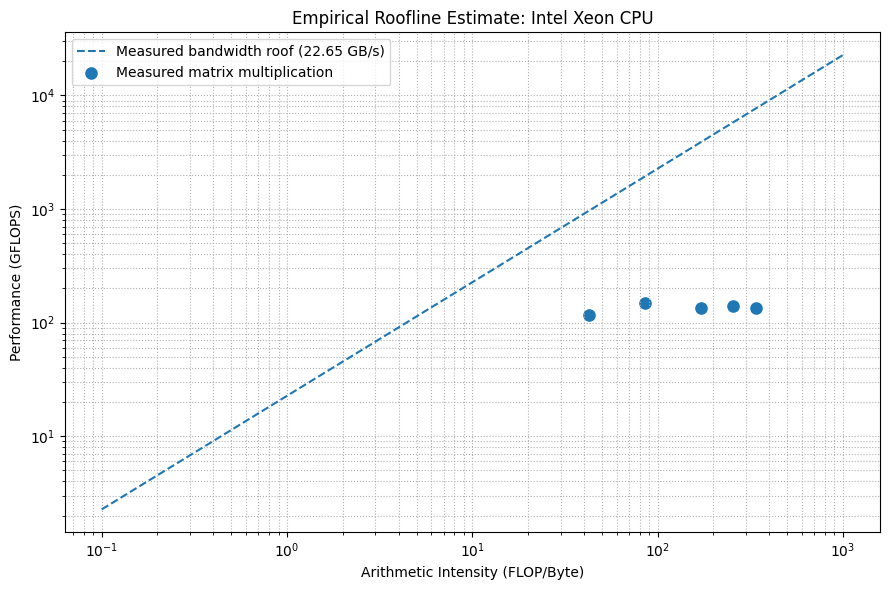

Updated: intel_xeon_cpu_roofline.png


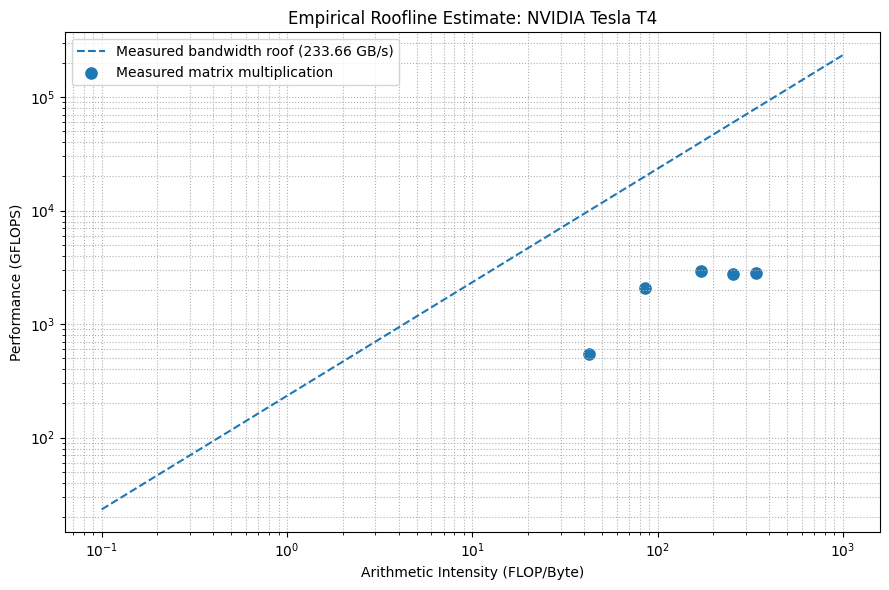

Updated: nvidia_tesla_t4_roofline.png


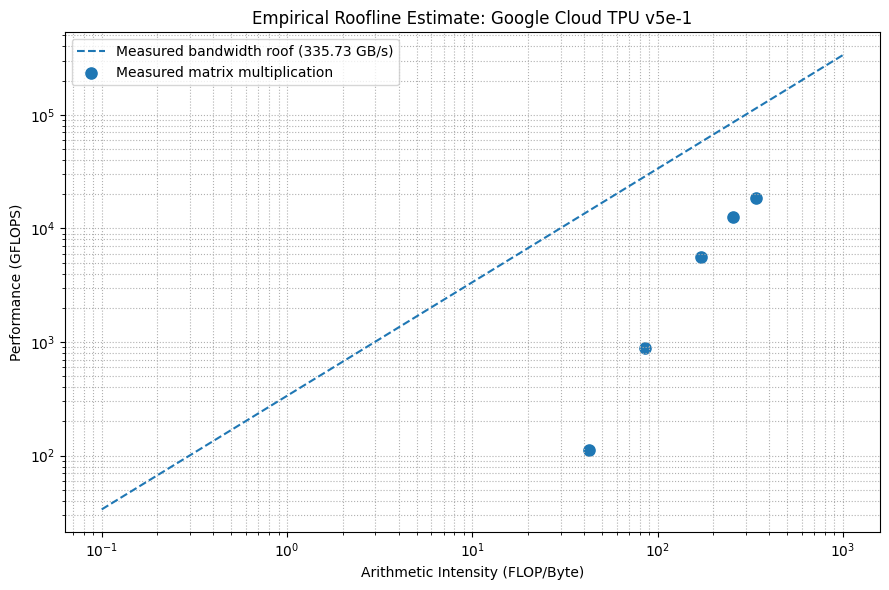

Updated: google_cloud_tpu_v5e_1_roofline.png

Corrected Roofline CSV saved:
/content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Results/Raw_CSV/roofline_input_data_corrected.csv

Verified bandwidth values:
Device
Google Cloud TPU v5e-1    335.734770
Intel Xeon CPU             22.648432
NVIDIA Tesla T4           233.660000
Name: Measured_Bandwidth_Ceiling_GBps, dtype: float64


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

project = (
    "/content/gdrive/MyDrive/"
    "AI_Inference_Precision_Comparison"
)

raw = os.path.join(project, "Results", "Raw_CSV")
graphs = os.path.join(project, "Results", "Graphs")

# Read existing Roofline data
df = pd.read_csv(
    os.path.join(raw, "roofline_input_data.csv")
)

# Read verified memory bandwidth data
memory = pd.read_csv(
    os.path.join(raw, "combined_memory_bandwidth.csv")
)

# Get maximum measured bandwidth per device
bandwidth = memory.groupby("Device")[
    "Bandwidth_GBps"
].max()

# Match the device names
device_mapping = {
    "Intel Xeon CPU": "Intel Xeon CPU",
    "NVIDIA Tesla T4": "NVIDIA Tesla T4",
    "Google Cloud TPU v5e-1": "TPU v5e-1"
}

df["Measured_Bandwidth_Ceiling_GBps"] = (
    df["Device"]
    .map(device_mapping)
    .map(bandwidth)
)

df["Data_Status"] = (
    "Reconstructed from recorded benchmark summaries; "
    "bandwidth ceiling verified from memory-bandwidth CSV; "
    "CPU/GPU and TPU timing methods differ"
)

# Save corrected dataset separately
corrected_path = os.path.join(
    raw,
    "roofline_input_data_corrected.csv"
)

df.to_csv(corrected_path, index=False)

# Regenerate the three empirical Roofline plots
for device in df["Device"].unique():

    subset = df[df["Device"] == device]

    ai = subset["Arithmetic_Intensity_FLOP_per_Byte"]
    performance = subset["GFLOPS"]

    bw = subset[
        "Measured_Bandwidth_Ceiling_GBps"
    ].iloc[0]

    x = np.logspace(-1, 3, 200)
    y = bw * x

    plt.figure(figsize=(9, 6))

    plt.loglog(
        x,
        y,
        linestyle="--",
        label=f"Measured bandwidth roof ({bw:.2f} GB/s)"
    )

    plt.scatter(
        ai,
        performance,
        s=65,
        label="Measured matrix multiplication"
    )

    plt.title(f"Empirical Roofline Estimate: {device}")
    plt.xlabel("Arithmetic Intensity (FLOP/Byte)")
    plt.ylabel("Performance (GFLOPS)")
    plt.grid(True, which="both", linestyle=":")
    plt.legend()
    plt.tight_layout()

    filename = (
        device.lower()
        .replace(" ", "_")
        .replace("-", "_")
        + "_roofline.png"
    )

    plt.savefig(
        os.path.join(graphs, filename),
        dpi=300
    )

    plt.show()
    plt.close()

    print("Updated:", filename)

print("\nCorrected Roofline CSV saved:")
print(corrected_path)

print("\nVerified bandwidth values:")
print(
    df.groupby("Device")[
        "Measured_Bandwidth_Ceiling_GBps"
    ].first()
)

In [ ]:
import os

graphs = (
    "/content/gdrive/MyDrive/"
    "AI_Inference_Precision_Comparison/"
    "Results/Graphs"
)

files = [
    "intel_xeon_cpu_roofline.png",
    "nvidia_tesla_t4_roofline.png",
    "google_cloud_tpu_v5e_1_roofline.png"
]

for filename in files:
    path = os.path.join(graphs, filename)

    if os.path.exists(path):
        print("FOUND:", filename, "|", os.path.getsize(path), "bytes")
    else:
        print("MISSING:", filename)

FOUND: intel_xeon_cpu_roofline.png | 252951 bytes
FOUND: nvidia_tesla_t4_roofline.png | 259512 bytes
FOUND: google_cloud_tpu_v5e_1_roofline.png | 261068 bytes


In [ ]:
import pandas as pd
import os

architecture_data = [
    {
        "Device": "Intel Xeon CPU",
        "Architecture": "x86-64",
        "Compute_Units": "2 logical CPUs available",
        "FP32_Peak_TFLOPS": "Not verified",
        "Lowest_Precision_Peak": "Not verified",
        "Memory": "Virtualized Colab memory",
        "Notes": "Exact CPU SKU unknown"
    },
    {
        "Device": "NVIDIA Tesla T4",
        "Architecture": "Turing",
        "Compute_Units": "2560 CUDA cores, 320 Tensor Cores",
        "FP32_Peak_TFLOPS": 8.1,
        "Lowest_Precision_Peak": "INT4: 260 TOPS",
        "Memory": "16 GB GDDR6",
        "Notes": "FP16: 65 TFLOPS; INT8: 130 TOPS"
    },
    {
        "Device": "Google Cloud TPU v5e-1",
        "Architecture": "TPU v5e",
        "Compute_Units": "1 TensorCore, 4 MXUs",
        "FP32_Peak_TFLOPS": "Not specified here",
        "Lowest_Precision_Peak": "INT8: 393 TOPS",
        "Memory": "16 GB HBM",
        "Notes": "BF16: 197 TFLOPS"
    }
]

df_architecture = pd.DataFrame(architecture_data)

display(df_architecture)

architecture_path = os.path.join(
    documentation,
    "hardware_architecture_comparison.csv"
)

df_architecture.to_csv(architecture_path, index=False)

print("Architecture data saved:", architecture_path)

,Device,Architecture,Compute_Units,FP32_Peak_TFLOPS,Lowest_Precision_Peak,Memory,Notes
0,Intel Xeon CPU,x86-64,2 logical CPUs available,Not verified,Not verified,Virtualized Colab memory,Exact CPU SKU unknown
1,NVIDIA Tesla T4,Turing,"2560 CUDA cores, 320 Tensor Cores",8.1,INT4: 260 TOPS,16 GB GDDR6,FP16: 65 TFLOPS; INT8: 130 TOPS
2,Google Cloud TPU v5e-1,TPU v5e,"1 TensorCore, 4 MXUs",Not specified here,INT8: 393 TOPS,16 GB HBM,BF16: 197 TFLOPS


Architecture data saved: /content/gdrive/MyDrive/AI_Inference_Precision_Comparison/Documentation/hardware_architecture_comparison.csv


In [1]:

from google.colab import drive
from pathlib import Path

# Mount Google Drive
drive.mount('/content/gdrive')

# Main project folder
project_path = Path(
    "/content/gdrive/MyDrive/AI_Inference_Precision_Comparison"
)

# Create README.md in the main project folder
readme = """# Numerical Precision Impact on AI Inference Across CPU, GPU, TPU and NPU

## 1. Project Overview

This project investigates how numerical precision and hardware architecture
affect AI performance across CPU, GPU and TPU platforms.

The study uses computer architecture concepts, hardware benchmarks,
AI inference experiments and training experiments.

## 2. Experimental Environment

- Platform: Google Colab
- CPU: Intel Xeon CPU @ 2.00 GHz
- GPU: NVIDIA Tesla T4
- TPU: Google Cloud TPU v5e-1
- NPU: Not tested
- Framework: PyTorch
- Framework and library versions: See environment verification notebook.

Note: Hardware availability and configurations may vary between sessions.

## 3. Project Folder Structure

- Code/: Google Colab notebooks and experimental scripts.
- Results/Raw_CSV/: Raw benchmark measurements.
- Results/Graphs/: Generated charts and figures.
- Documentation/: Research paper and supporting documents.
- README.md: Project overview and reproduction instructions.

## 4. Experiments

### Hardware Benchmarks
- Matrix multiplication
- Memory bandwidth
- Numerical precision comparison
- Host-to-device transfer overhead

### AI Workloads
- ResNet-50: Convolutional network
- DistilBERT: Transformer
- LSTM: Memory-bound/sequential workload
- FashionMNIST CNN: Training experiment

### Computer Architecture Analysis
- Roofline model
- Amdahl's Law
- Iron Law of Performance
- CPU thread scaling

## 5. Results and Data

Raw measurements are stored in Results/Raw_CSV/.

Graphs and visualizations are stored in Results/Graphs/.

The CSV files contain the recorded experimental measurements.
Graphs are generated from the experimental data.

## 6. Reproduction Instructions

1. Open Google Colab.
2. Open the required notebook from the Code folder.
3. Connect to the appropriate runtime.
4. Check the hardware and software versions.
5. Mount Google Drive.
6. Run the notebook cells in their intended order.
7. Save generated CSV files in Results/Raw_CSV/.
8. Save generated graphs in Results/Graphs/.

Some experiments may require a particular hardware runtime.
TPU experiments must be run on a compatible TPU runtime.

## 7. Hardware Limitations

- Hardware availability depends on the Colab runtime and account.
- NPU experiments were not performed.
- TPU AI inference and training results are not established in this project record.
- Hardware-specific limitations and unavailable measurements are documented
  in the research paper.

## 8. Academic Integrity

The project uses documented experimental results, credited research sources,
and referenced software libraries and model resources.

AI assistance, where used, must be disclosed in the research paper.
All measurements should be reported honestly without fabricating results.

## 9. Team Contributions

Add the actual contributions of each team member here.

## 10. References

See the References section of the research paper for the complete
bibliography and source citations.
"""

readme_path = project_path / "README.md"
readme_path.write_text(readme, encoding="utf-8")

print("README created at:", readme_path)
print("File exists:", readme_path.exists())


Mounted at /content/gdrive
README created at: /content/gdrive/MyDrive/AI_Inference_Precision_Comparison/README.md
File exists: True
